# Evaluación de la deformación superficial asociada a movimientos en masa mediante análisis InSAR y datos GNSS en la cuenca media y baja del río Suárez, Colombia

## Notebook 1 de 3. Componente InSAR: series temporales Sentinel-1 con HyP3 y MintPy

**Autores:** Mariana Paredes Galindo · Sair Granada Garzón  
**Director:** José Pedro Mora Ortiz, Geólogo, MSc. en Sistemas de Información Geográfica y MSc. en Geofísica  
**Codirector:** José Luis Gómez Díaz, Ing. Catastral y Geodesta, MSc. en Ciencias de la Geoinformación y Observación de la Tierra  

Universidad Industrial de Santander · Facultad de Ingenierías Fisicoquímicas · Escuela de Geología  
Bucaramanga, 2026

Este notebook procesa solo las imágenes Sentinel-1. Las estaciones GNSS aparecen únicamente como ubicaciones: el sitio de la estación OAMU es el punto de referencia espacial de MintPy (sección 15), la estación VELZ es la referencia de los mapas de velocidad (sección 21) y en los sitios de las 12 estaciones se extrae la serie InSAR (sección 23). Ningún dato de posición GNSS entra en este notebook: las series GNSS se analizan en el notebook 2 y la comparación de ambas técnicas se hace en el notebook 3.

## 1. Librerías

Instala las librerías que falten en el núcleo (*kernel*) de Jupyter, las importa. El aspecto de las figuras y las tablas se fija en la celda de diseño que sigue. MintPy se instala aparte, en un entorno conda (sección 12).

| Librería | Uso | Referencia |
|---|---|---|
| Biblioteca estándar (`pathlib`, `subprocess`, `zipfile`, `re`, entre otras) | Rutas, procesos externos, descompresión, texto y contraseñas | Python Software Foundation (2024) |
| `numpy` | Arreglos, máscaras y estadísticas | Harris et al. (2020) |
| `pandas` | Tablas de escenas, pares y resultados | McKinney (2010) |
| `geopandas`, `shapely`, `pyproj` | Geometrías, reproyección y coordenadas | Jordahl et al. (2020); Gillies et al. (2024); Snow et al. (2024) |
| `h5py` | Lectura de los archivos HDF5 de MintPy | Collette (2013) |
| `rasterio` | Lectura, recorte, remuestreo y escritura de GeoTIFF | Gillies et al. (2013) |
| `matplotlib` | Gráficas y mapas | Hunter (2007) |
| `IPython.display` | Tablas en formato APA 7 y barras de avance | Pérez y Granger (2007) |
| `asf_search`, `hyp3_sdk` | Búsqueda de escenas y trabajos de interferometría | Alaska Satellite Facility [ASF] (s.f.-a); Hogenson et al. (2026) |

In [1]:
# Verificación de dependencias: instala solo las que falten
import importlib.util
import subprocess
import sys

PAQUETES = {
    "asf_search": "asf-search",
    "geopandas": "geopandas",
    "h5py": "h5py",
    "hyp3_sdk": "hyp3-sdk",
    "pyproj": "pyproj",
    "rasterio": "rasterio",
}

faltantes = [paquete for modulo, paquete in PAQUETES.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    print("instalando:", ", ".join(faltantes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltantes])

# Biblioteca estándar
import contextlib
import getpass
import html
import io
import os
import re
import shutil
import time
import warnings
import zipfile
from pathlib import Path

# Cálculo numérico y tablas
import numpy as np
import pandas as pd

# Datos vectoriales
import geopandas as gpd
from pyproj import Transformer
from shapely.geometry import Point, box, shape
from shapely.ops import orient
from shapely.validation import make_valid

# Datos ráster (GeoTIFF) y HDF5
import h5py
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin, rowcol
from rasterio.warp import Resampling, reproject, transform_bounds
import rasterio.warp
from rasterio.windows import Window, from_bounds

# Gráficas y salidas del cuaderno
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from matplotlib.lines import Line2D

# Sentinel-1 y HyP3
import asf_search as asf
from hyp3_sdk import HyP3

print("ok: librerías cargadas")

instalando: hyp3-sdk
  Using cached hyp3_sdk-7.7.8-py3-none-any.whl.metadata (6.2 kB)
Using cached hyp3_sdk-7.7.8-py3-none-any.whl (16 kB)
ok: librerías cargadas


### Diseño de figuras y tablas

Esta celda es la misma en los tres notebooks, para que todo el trabajo se vea igual. Fija la fuente (Times New Roman o la serif más parecida), la paleta (azul para lo que se aleja o desciende, rojo para lo que se acerca o asciende, gris para los datos), el ancho de 6,5 pulgadas, las coordenadas geográficas en grados y minutos, el norte, la escala en km, las letras de panel y las barras de colores horizontales. Los títulos de figura y de tabla llevan solo el número y el nombre; lo que cada una muestra se explica en el texto de su celda.

Al final de la celda quedan las dos funciones que dependen del área de estudio y solo se usan en este notebook (`panel` y `limitar_al_area`).

In [2]:
# Diseño común de los tres notebooks: fuente, paleta, estilo de los ejes, títulos de figura y tablas
import html

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from matplotlib import font_manager
from matplotlib.lines import Line2D

# Fuente: Times New Roman o la serif más parecida que esté instalada
FUENTES = ["Times New Roman", "Liberation Serif", "STIXGeneral", "DejaVu Serif"]
instaladas = {f.name for f in font_manager.fontManager.ttflist}
FUENTE = next(f for f in FUENTES if f in instaladas or f == "DejaVu Serif")

# Medidas y colores
FIG_ANCHO = 6.5            # pulgadas, ancho útil de la página
ESCALA_KM = 20             # longitud de la escala gráfica de los mapas, km
FONDO = "#ececec"
COLOR_AZUL, COLOR_ROJO, COLOR_DATOS, COLOR_NARANJA = "#2166ac", "#b2182b", "#9a9a9a", "#e08214"
PALETA_VELOCIDAD, PALETA_INCERTIDUMBRE = "RdBu_r", "magma_r"
# Color de cada geometría (descendente en azul, ascendente en rojo) y un tono claro para un segundo stack de la misma geometría
COLORES_STACK = {"DESCENDING": [COLOR_AZUL, "#5aa0d0"], "ASCENDING": [COLOR_ROJO, "#e06a5a"]}
# Series temporales: un color por geometría (el segundo stack de la misma geometría, más claro) y GNSS en negro
COLORES_STACK = {"DESCENDING": [COLOR_AZUL, "#5aa0d0"], "ASCENDING": [COLOR_ROJO, "#e06a5a"]}
COLOR_GNSS = "black"

plt.rcParams.update({
    "font.family": "serif", "font.serif": [FUENTE], "mathtext.fontset": "stix", "font.size": 8,
    "axes.linewidth": 0.8, "axes.labelweight": "bold", "axes.titleweight": "bold", "axes.titlesize": 9,
    "axes.axisbelow": True, "grid.color": "0.88", "grid.linewidth": 0.5, "lines.linewidth": 1.0,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "legend.fontsize": 7, "legend.framealpha": 0.9, "legend.edgecolor": "0.8",
    "figure.dpi": 120,
})
TIPO_HTML = "font-family:'Times New Roman',Times,serif;font-size:13px"


# Número con coma decimal
def coma(valor, decimales=1):
    return f"{valor:.{decimales}f}".replace(".", ",")


# Grados decimales a texto en grados y minutos con hemisferio
def gms(valor, positivo, negativo):
    total = round(abs(valor) * 60)
    return f"{total // 60}°{total % 60:02d}'{positivo if valor >= 0 else negativo}"


# Letra del panel en un recuadro blanco
def letra_panel(eje, letra, x=0.03, y=0.965):
    eje.text(x, y, letra, transform=eje.transAxes, ha="left", va="top", fontsize=9, fontweight="bold",
             bbox=dict(boxstyle="square,pad=0.25", fc="white", ec="black", lw=0.6), zorder=6)


# Marcas hacia adentro en los cuatro bordes y borde de 0,8 pt
def estilo_eje(eje):
    eje.tick_params(labelsize=7, direction="in", length=3, top=True, right=True)
    for borde in eje.spines.values():
        borde.set_linewidth(0.8)


# Marcas de longitud en el borde inferior y de latitud en el izquierdo, en grados y minutos
def coordenadas_geograficas(eje, epsg, paso_x, paso_y):
    from pyproj import Transformer
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    a_geo = Transformer.from_crs(epsg, 4326, always_xy=True)
    a_map = Transformer.from_crs(4326, epsg, always_xy=True)
    lon_min, lat_min = a_geo.transform(x0, y0)
    lon_max, lat_max = a_geo.transform(x1, y1)
    _, lat_borde = a_geo.transform((x0 + x1) / 2, y0)
    lon_borde, _ = a_geo.transform(x0, (y0 + y1) / 2)
    lons = np.arange(np.ceil(lon_min / paso_x) * paso_x, lon_max, paso_x)
    lats = np.arange(np.ceil(lat_min / paso_y) * paso_y, lat_max, paso_y)
    xs = [(a_map.transform(lon, lat_borde)[0], lon) for lon in lons]
    ys = [(a_map.transform(lon_borde, lat)[1], lat) for lat in lats]
    xs = [(x, v) for x, v in xs if x0 + 0.04 * (x1 - x0) < x < x1 - 0.04 * (x1 - x0)]
    ys = [(y, v) for y, v in ys if y0 + 0.03 * (y1 - y0) < y < y1 - 0.03 * (y1 - y0)]
    eje.set_xticks([x for x, _ in xs])
    eje.set_xticklabels([gms(v, "E", "W") for _, v in xs])
    eje.set_yticks([y for y, _ in ys])
    eje.set_yticklabels([gms(v, "N", "S") for _, v in ys], rotation=90, va="center")


# Inserta NaN donde hay huecos mayores que "dias" para que la línea no cruce los vacíos
def cortar_huecos(fechas, valores, dias=60):
    fechas = pd.DatetimeIndex(fechas)
    corte = np.where(np.diff(fechas.asi8) / 86.4e12 > dias)[0] + 1
    return np.insert(fechas.to_numpy(), corte, np.datetime64("NaT")), np.insert(np.asarray(valores, dtype=float), corte, np.nan)


# Serie temporal en el estilo común: puntos, mediana móvil de "ventana" fechas y tendencia lineal discontinua.
# Devuelve la pendiente en mm/año (la ajustada, o la dada en "pendiente")
def trazar_serie(eje, fechas, serie, color, ventana=5, hueco=60, tamano=2.6, color_puntos=None, pendiente=None):
    fechas, serie = pd.DatetimeIndex(fechas), np.asarray(serie, dtype=float)
    anios = ((fechas - fechas[0]).days / 365.25).to_numpy()
    if pendiente is None:
        pendiente, intercepto = np.polyfit(anios, serie, 1)
    else:
        intercepto = np.median(serie - pendiente * anios)
    eje.plot(fechas, serie, "o", ms=tamano, color=color_puntos or color, alpha=0.55, mew=0, zorder=2)
    suave = pd.Series(serie).rolling(ventana, center=True, min_periods=1).median().to_numpy()
    eje.plot(*cortar_huecos(fechas, suave, hueco), "-", lw=1.2, color=color, zorder=4)
    eje.plot(fechas, pendiente * anios + intercepto, "--", lw=1.0, color=color, zorder=5)
    return float(pendiente)


# Eje de una serie temporal: años en x, rejilla horizontal, línea en cero y un margen de 30 días a cada lado
def estilo_serie(eje, inicio, fin):
    eje.set_xlim(inicio - pd.Timedelta(days=30), fin + pd.Timedelta(days=30))
    eje.xaxis.set_major_locator(mdates.YearLocator())
    eje.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    eje.axhline(0, color="0.6", lw=0.5, zorder=0)
    eje.grid(axis="y")
    estilo_eje(eje)


# Leyenda de una serie temporal: con recuadro claro y sin negrita
def leyenda_serie(eje, manijas):
    eje.legend(handles=manijas, loc="best", frameon=True)


# Norte en la esquina superior derecha y escala gráfica en la inferior izquierda, sobre recuadros blancos (mapa en metros)
def norte_y_escala(eje, escala_km=ESCALA_KM):
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    ancho, alto = x1 - x0, y1 - y0
    bx, by, largo = x0 + 0.08 * ancho, y0 + 0.04 * alto, escala_km * 1000
    eje.add_patch(plt.Rectangle((bx - 0.05 * ancho, by - 0.017 * alto), largo + 0.24 * ancho, 0.06 * alto,
                                facecolor="white", edgecolor="black", lw=0.4, alpha=0.9, zorder=4))
    for i in range(2):
        eje.add_patch(plt.Rectangle((bx + i * largo / 2, by), largo / 2, 0.009 * alto,
                                    facecolor="black" if i == 0 else "white", edgecolor="black", lw=0.4, zorder=5))
    for v, x in ((0, bx), (escala_km // 2, bx + largo / 2), (escala_km, bx + largo)):
        eje.text(x, by + 0.014 * alto, f"{v}", ha="center", va="bottom", fontsize=5.5, zorder=5)
    eje.text(bx + largo + 0.04 * ancho, by + 0.005 * alto, "km", va="center", fontsize=5.5, zorder=5)
    nx, ny = x1 - 0.1 * ancho, y1 - 0.12 * alto
    eje.add_patch(plt.Rectangle((nx - 0.055 * ancho, ny - 0.01 * alto), 0.11 * ancho, 0.1 * alto,
                                facecolor="white", edgecolor="black", lw=0.4, alpha=0.9, zorder=4))
    eje.annotate("", xy=(nx, ny + 0.055 * alto), xytext=(nx, ny + 0.002 * alto),
                 arrowprops=dict(facecolor="black", edgecolor="black", width=1.5, headwidth=4.5, headlength=4), zorder=5)
    eje.text(nx, ny + 0.058 * alto, "N", ha="center", va="bottom", fontsize=6.5, fontweight="bold", zorder=5)


# Barra de colores horizontal con rótulo; con límite, marcas cada 10 unidades
def barra_colores(fig, imagen, ejes, rotulo, limite=None, encoger=0.6):
    marcas = range(-limite, limite + 1, 10) if limite else None
    barra = fig.colorbar(imagen, ax=ejes, orientation="horizontal", shrink=encoger, pad=0.02, aspect=40, ticks=marcas)
    barra.set_label(rotulo, fontsize=8)
    barra.ax.tick_params(labelsize=7)
    return barra


# Título de una figura, que se muestra encima de ella: "Figura N" en negrita (si se da el número) y el título en cursiva
def titulo_figura(titulo, numero=None):
    cabeza = f'<div style="font-weight:bold">Figura {numero}</div>' if numero is not None else ""
    display(HTML(f'<div style="{TIPO_HTML};margin:12px 0 2px">{cabeza}'
                 f'<div style="font-style:italic">{html.escape(titulo)}</div></div>'))


# Inserta NaN donde hay un hueco de más de max_dias días, para que la línea no lo cruce
def romper_huecos(fechas, valores, max_dias=30):
    f, v = [fechas[0]], [valores[0]]
    for k in range(1, len(fechas)):
        if (fechas[k] - fechas[k - 1]).days > max_dias:
            f.append(fechas[k - 1] + pd.Timedelta(days=1))
            v.append(np.nan)
        f.append(fechas[k])
        v.append(valores[k])
    return pd.DatetimeIndex(f), np.array(v, dtype=float)


# Serie de desplazamiento: puntos, mediana móvil y tendencia lineal (discontinua). Devuelve el elemento de la leyenda
def dibujar_serie(eje, fechas, valores, color, etiqueta, ventana=5, color_puntos=None, pendiente=None, tam=2.8, max_hueco=30):
    fechas, valores = pd.DatetimeIndex(fechas), np.asarray(valores, dtype=float)
    anios = ((fechas - fechas[0]).days / 365.25).to_numpy()
    if pendiente is None:
        pendiente, intercepto = np.polyfit(anios, valores, 1)
    else:
        intercepto = np.median(valores - pendiente * anios)
    color_puntos = color_puntos or color
    suave = pd.Series(valores).rolling(ventana, center=True, min_periods=1).median().to_numpy()
    eje.plot(fechas, valores, "o", ms=tam, color=color_puntos, alpha=0.55, mew=0, zorder=3)
    eje.plot(*romper_huecos(fechas, suave, max_hueco), "-", lw=1.3, color=color, zorder=4)
    eje.plot(fechas, pendiente * anios + intercepto, "--", lw=1.0, color=color, zorder=5)
    return Line2D([], [], color=color, lw=1.3, marker="o", ms=3, mfc=color_puntos, mec="none", label=etiqueta)


# Formato común de una serie temporal: línea en cero, cuadrícula horizontal, fechas legibles y rótulo del eje y
def formato_serie(eje, rotulo="Desplazamiento en la línea de vista (mm)"):
    inicio, fin = (mdates.num2date(v) for v in eje.get_xlim())
    anios = (fin - inicio).days / 365.25
    if anios <= 1.5:
        localizador, formato = mdates.MonthLocator(bymonth=(1, 4, 7, 10)), "%Y-%m"
    elif anios <= 3.5:
        localizador, formato = mdates.MonthLocator(bymonth=(1, 7)), "%Y-%m"
    else:
        localizador, formato = mdates.YearLocator(), "%Y"
    eje.xaxis.set_major_locator(localizador)
    eje.xaxis.set_major_formatter(mdates.DateFormatter(formato))
    eje.axhline(0, color="0.6", lw=0.5, zorder=0)
    eje.grid(axis="y")
    eje.set_ylabel(rotulo)
    estilo_eje(eje)


# Texto de una celda de tabla: coma decimal, decimales parejos por columna y guion para los vacíos
def texto_celda(valor, decimales):
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return "-"
    if isinstance(valor, (float, np.floating)):
        return f"{valor:,.{decimales}f}".replace(",", " ").replace(".", ",")
    if isinstance(valor, (int, np.integer)):
        return f"{valor:,}".replace(",", " ") if abs(valor) >= 10000 else str(valor)
    return html.escape(str(valor))


# Tabla en formato APA 7: número (opcional), título en cursiva y solo líneas horizontales.
# Con agrupar="Columna", los valores repetidos de esa primera columna salen una sola vez y los grupos se separan con una línea fina
def tabla_apa(tabla, titulo, numero=None, agrupar=None):
    if tabla is None or len(tabla) == 0:
        return
    linea, fina = "1.5px solid currentColor", "1px solid #bbbbbb"
    decimales = {}
    for col in tabla.columns:
        valores = [v for v in tabla[col] if isinstance(v, (float, np.floating)) and np.isfinite(v)]
        partes = [f"{round(float(v), 2)}".split(".")[1] for v in valores]
        decimales[col] = max([1] + [len(p.rstrip("0")) for p in partes])
    cabeza = "".join(f'<th style="border-top:{linea};border-bottom:1px solid currentColor;padding:3px 10px;'
                     f'font-weight:normal;text-align:center">{html.escape(str(col))}</th>' for col in tabla.columns)
    inicios, tamanos = {}, {}
    if agrupar is not None:
        grupo = list(tabla[agrupar])
        for k, v in enumerate(grupo):
            if k == 0 or v != grupo[k - 1]:
                inicios[k], actual = v, k
                tamanos[k] = 0
            tamanos[actual] += 1
    filas, ultimo = [], len(tabla) - 1
    for k, (_, fila) in enumerate(tabla.iterrows()):
        borde = f"border-bottom:{linea};" if k == ultimo else ""
        if agrupar is not None and k in inicios and k > 0:
            borde += f"border-top:{fina};"
        celdas = []
        for col in tabla.columns:
            valor = fila[col]
            if col == agrupar:
                if k in inicios:
                    cierre = f"border-bottom:{linea};" if k + tamanos[k] - 1 == ultimo else ""
                    sup = f"border-top:{fina};" if k > 0 else ""
                    celdas.append(f'<td rowspan="{tamanos[k]}" style="{cierre}{sup}padding:2px 10px;text-align:left;'
                                  f'vertical-align:top;font-weight:bold">{texto_celda(valor, 0)}</td>')
                continue
            alinear = "right" if isinstance(valor, (int, float, np.integer, np.floating)) else "left"
            celdas.append(f'<td style="{borde}padding:2px 10px;text-align:{alinear}">{texto_celda(valor, decimales[col])}</td>')
        filas.append("<tr>" + "".join(celdas) + "</tr>")
    encabezado = f'<div style="font-weight:bold">Tabla {numero}</div>' if numero is not None else ""
    display(HTML(f'<div style="{TIPO_HTML};margin:12px 0 14px">{encabezado}'
                 f'<div style="font-style:italic;margin-bottom:4px">{html.escape(titulo)}</div>'
                 f'<table style="border-collapse:collapse;{TIPO_HTML}"><thead><tr>{cabeza}</tr></thead>'
                 f'<tbody>{"".join(filas)}</tbody></table></div>'))

# ---- Solo de este notebook ----
MARGEN_M = 3000            # margen alrededor de la cuenca, m
GEOMETRIAS_DOC = {"DESCENDING_R69": "Descendente", "ASCENDING_R77": "Ascendente"}


# Panel de mapa con el contorno del área de estudio y la letra, sin rótulos automáticos de los ejes
def panel(eje, arr, extension, epsg, cmap, vmin, vmax, letra):
    eje.set_facecolor(FONDO)
    im = eje.imshow(arr, extent=extension, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest", zorder=1)
    gdf_area.to_crs(epsg).boundary.plot(ax=eje, color="black", lw=0.9, zorder=3)
    eje.set_xlabel("")
    eje.set_ylabel("")
    letra_panel(eje, letra, x=0.04, y=0.975)
    estilo_eje(eje)
    return im


# Ajusta los límites del mapa al área de estudio con un margen
def limitar_al_area(eje, epsg, margen=MARGEN_M):
    xmin, ymin, xmax, ymax = gdf_area.to_crs(epsg).total_bounds
    eje.set_xlim(xmin - margen, xmax + margen)
    eje.set_ylim(ymin - margen, ymax + margen)


print(f"ok: diseño cargado | fuente de las figuras: {FUENTE}")

ok: diseño cargado | fuente de las figuras: Liberation Serif


## 2. Rutas

Define la carpeta del proyecto (`BASE_DIR`), el identificador de la corrida (`RUN_ID`) y las rutas que se derivan de ellos. `RUN_ID` forma parte del nombre de los trabajos en HyP3, por lo que no se cambia después del primer envío. Se denomina *stack* al conjunto de interferogramas de una misma órbita y huella; MintPy trabaja cada uno en su propia carpeta (Yunjun et al., 2019).

    <proyecto>/
    ├── 01_datos/       área de estudio, tabla de pares y productos de HyP3 (zip, descomprimidos, recortados)
    ├── 02_mintpy/      una carpeta por stack y modelos meteorológicos (ERA5)
    └── 03_resultados/  geotiff, figuras y tablas

Las tablas se muestran con `tabla_apa` (celda de diseño): título en cursiva, solo líneas horizontales y coma decimal; las que van en el documento llevan además su número. La función `barra` muestra el avance de los procesos largos (descargas, recortes, stacks) y desaparece al terminar. La celda informa el estado del proyecto y el espacio libre en disco.

In [3]:
BASE_DIR = Path.home() / "Tesis_InSAR_Rio_Suarez"
RUN_ID = "suarez_2024_2026_v1"  # no cambiarlo después del primer envío a HyP3

if not BASE_DIR.exists():
    raise FileNotFoundError(f"no existe {BASE_DIR}")

# Datos de entrada
DATOS_DIR = BASE_DIR / "01_datos"
AREA_DIR = DATOS_DIR / "area_estudio"
ARCHIVO_PARES = DATOS_DIR / "pares" / f"{RUN_ID}_pares.csv"
HYP3_DIR = DATOS_DIR / "hyp3"
DOWNLOAD_DIR = HYP3_DIR / "zip"
UNZIP_DIR = HYP3_DIR / "descomprimidos"
CLIP_DIR = HYP3_DIR / "recortados"
CLIP_ANTERIOR_DIR = HYP3_DIR / "recortados_anteriores"

# Series temporales
MINTPY_ROOT = BASE_DIR / "02_mintpy"
WEATHER_DIR = MINTPY_ROOT / "ERA5"
RESPALDO_MINTPY_DIR = BASE_DIR / "02_mintpy_respaldo"

# Resultados
RESULTADOS_DIR = BASE_DIR / "03_resultados"
GEOTIFF_DIR = RESULTADOS_DIR / "geotiff"
MOSAICO_DIR = GEOTIFF_DIR / "mosaicos"
TABLAS_DIR = RESULTADOS_DIR / "tablas"

CARPETAS = (
    AREA_DIR, ARCHIVO_PARES.parent, DOWNLOAD_DIR, UNZIP_DIR, CLIP_DIR,
    MINTPY_ROOT, WEATHER_DIR, GEOTIFF_DIR, MOSAICO_DIR, TABLAS_DIR,
)
for carpeta in CARPETAS:
    carpeta.mkdir(parents=True, exist_ok=True)


# Tiempo en formato m:ss o h:mm:ss
def duracion(segundos):
    minutos, s = divmod(int(segundos), 60)
    h, m = divmod(minutos, 60)
    return f"{h}:{m:02d}:{s:02d}" if h else f"{m}:{s:02d}"


# Barra en HTML: rótulo, avance de 0 a 1 (None si no se conoce) y detalle
def html_barra(rotulo, fraccion, detalle="", color="#3b82c4"):
    ancho = 100 * min(max(fraccion, 0), 1) if fraccion is not None else 100
    relleno = color if fraccion is not None else "rgba(59,130,196,0.35)"
    numero = f"{ancho:.0f} %" if fraccion is not None else "en curso"
    return (
        '<div style="display:flex;align-items:center;gap:12px;font-size:13px;margin:3px 0">'
        f'<span style="min-width:230px">{html.escape(rotulo)}</span>'
        '<div style="width:300px;height:10px;border-radius:5px;background:rgba(128,128,128,0.25);overflow:hidden">'
        f'<div style="width:{ancho:.1f}%;height:100%;border-radius:5px;background:{relleno}"></div></div>'
        f'<span style="min-width:70px">{numero}</span>'
        f'<span style="opacity:0.65">{html.escape(detalle)}</span></div>'
    )


# Nombre de un stack para tablas y figuras: "Descendente R69 F572"
def nombre_stack(job_name):
    nombre = job_name.replace(f"{RUN_ID}_", "")
    for clave, texto in (("DESCENDING_", "Descendente "), ("ASCENDING_", "Ascendente ")):
        nombre = nombre.replace(clave, texto)
    return nombre.replace("_", " ")


# Recorre los elementos mostrando una barra con el avance y el tiempo restante; la barra se quita al terminar
def barra(elementos, titulo):
    elementos = list(elementos)
    total = len(elementos)
    if total == 0:
        return
    inicio = ultimo = time.time()
    salida = display(HTML(html_barra(f"{titulo}: 0/{total}", 0)), display_id=True)
    try:
        for n, elemento in enumerate(elementos, 1):
            yield elemento
            if n < total and time.time() - ultimo > 0.2:
                pasado = time.time() - inicio
                detalle = f"{duracion(pasado)} · faltan {duracion(pasado / n * (total - n))}"
                salida.update(HTML(html_barra(f"{titulo}: {n}/{total}", n / total, detalle)))
                ultimo = time.time()
    finally:
        salida.update(HTML(""))


# Estado del proyecto
stacks_recortados = sorted(p.name.replace(f"{RUN_ID}_", "") for p in CLIP_DIR.glob(f"{RUN_ID}_*") if p.is_dir())
stacks_mintpy = sorted(p.name.replace(f"{RUN_ID}_", "") for p in MINTPY_ROOT.glob(f"{RUN_ID}_*") if p.is_dir())
print(BASE_DIR)
print("pares:", "sí" if ARCHIVO_PARES.exists() else "no")
print("recortados:", ", ".join(stacks_recortados) or "-")
print("mintpy:", ", ".join(stacks_mintpy) or "-")
print(f"disco libre: {shutil.disk_usage(BASE_DIR).free / 1e9:.0f} GB")

/home/jovyan/Tesis_InSAR_Rio_Suarez
pares: sí
recortados: ASCENDING_R77_F1199, ASCENDING_R77_F1200, DESCENDING_R69_F567, DESCENDING_R69_F572
mintpy: ASCENDING_R77_F1199, DESCENDING_R69_F567, DESCENDING_R69_F572
disco libre: 105 GB


## 3. Parámetros

Reúne los parámetros que adaptan el flujo a una zona. Para replicarlo en otra cuenca basta con cambiar esta celda.

| Parámetro | Valor | Qué define |
|---|---|---|
| `ARCHIVO_AREA`, `NOMBRE_AREA` | cuenca media y baja del río Suárez | Polígono y nombre del área de estudio |
| `EPSG_PROYECTO`, `EXTENSION_MAPA` | 9377 (MAGNA-SIRGAS 2018, Origen-Nacional) | Sistema proyectado y rectángulo de los mapas |
| `START`, `END` | 2022-03-01 a 2026-09-30 | Periodo de análisis |
| `STACKS_EXCLUIDOS`, `RELLENOS` | | Stacks que no entran y stacks de relleno (sección 6) |
| `REF_LALO` | sitio de la estación GNSS OAMU | Punto de referencia espacial de MintPy; solo se usan sus coordenadas |
| `BW` | 2 | Ancho de banda de la red: cada fecha se une con las dos siguientes |
| `NL`, `NL_STACK` | 20; 10 en el ascendente | Conexión que se supone libre de sesgo de cierre (Zheng et al., 2022) |
| `FECHAS_EXCLUIDAS` | | Fechas que se retiran de la red de un stack |

El stack ascendente tiene 24 fechas: con `NL = 20` tendría 4 cierres y casi todo el sesgo tendría que extrapolarse, por lo que usa `NL = 10` (14 cierres). Las funciones `nl_stack`, `excluidas_stack` y `pares_banda` aplican estos parámetros en las secciones 7, 13 y 15.

In [4]:
# Área de estudio
ARCHIVO_AREA = AREA_DIR / "Cuenca_RioMedioyBajoSuarez.shp"  # .shp, .gpkg o .geojson
NOMBRE_AREA = "Cuenca media y baja del río Suárez"

# Mapas
EPSG_PROYECTO = 9377  # sistema proyectado, en metros
EXTENSION_MAPA = (4890000, 2150000, 5010000, 2320000)  # xmin, ymin, xmax, ymax; None = área más margen
MARGEN_MAPA_M = 5000
ARCHIVO_EXTENSION = AREA_DIR / "extension_mapas.shp"

# Periodo de análisis
START = "2022-03-01"
END = "2026-09-30"

# Procesamiento
STACKS_EXCLUIDOS = ["ASCENDING_R77_F1200"]
RELLENOS = {"DESCENDING_R69_F572": ["S1A"]}  # stack: satélites del stack de relleno
REF_LALO = (5.647209, -73.558029)  # latitud, longitud
BW = 2  # ancho de banda de la red (Zheng et al., 2022)
NL = 20  # conexión que se supone libre de sesgo de cierre
NL_STACK = {"ASCENDING_R77_F1199": 10}  # stacks cortos: conexión menor para tener más cierres
FECHAS_EXCLUIDAS = {}  # {stack: ["AAAAMMDD", ...]}


# Conexión libre de sesgo de un stack
def nl_stack(stack_id):
    return NL_STACK.get(stack_id, NL)


# Fechas excluidas de la red de un stack
def excluidas_stack(stack_id):
    return {pd.Timestamp(f) for f in FECHAS_EXCLUIDAS.get(stack_id, [])}


# Pares de la red de ancho de banda sobre una lista de fechas: conexiones 1 a bw y conexión nl
def pares_banda(fechas, bw, nl):
    fechas = sorted(fechas)
    conexiones = list(range(1, bw + 1)) + ([nl] if nl > bw else [])
    return [(fechas[i], fechas[i + c], c) for c in conexiones for i in range(len(fechas) - c)]


# Lee el área de estudio y la devuelve como un solo polígono en WGS 84
def leer_area(archivo):
    if not archivo.exists():
        raise FileNotFoundError(f"no existe {archivo}")
    capa = gpd.read_file(archivo)
    if capa.crs is None:
        raise ValueError(f"{archivo.name} sin .prj")
    return make_valid(capa.to_crs(4326).dissolve().geometry.iloc[0])


# Construye el rectángulo de los mapas; sin límites definidos encierra el área con un margen
def crear_extension(area, limites, margen, epsg):
    if limites is None:
        xmin, ymin, xmax, ymax = area.to_crs(epsg).total_bounds
        limites = (
            np.floor((xmin - margen) / 1000) * 1000,
            np.floor((ymin - margen) / 1000) * 1000,
            np.ceil((xmax + margen) / 1000) * 1000,
            np.ceil((ymax + margen) / 1000) * 1000,
        )
    return gpd.GeoDataFrame({"nombre": ["Extensión de los mapas"]}, geometry=[box(*limites)], crs=epsg)


geom_area = leer_area(ARCHIVO_AREA)
gdf_area = gpd.GeoDataFrame({"nombre": [NOMBRE_AREA]}, geometry=[geom_area], crs=4326)

extension = crear_extension(gdf_area, EXTENSION_MAPA, MARGEN_MAPA_M, EPSG_PROYECTO)
extension.to_file(ARCHIVO_EXTENSION)
gdf_extension = extension.to_crs(4326)

ANIOS_PERIODO = (pd.Timestamp(END) - pd.Timestamp(START)).days / 365.25
MESES_EJE = 2 if ANIOS_PERIODO <= 3 else 3 if ANIOS_PERIODO <= 6 else 6

area_km2 = gdf_area.to_crs(EPSG_PROYECTO).area.iloc[0] / 1e6
xmin, ymin, xmax, ymax = extension.total_bounds
print(f"área: {area_km2:.0f} km²")
print(f"mapas: {(xmax - xmin) / 1000:.0f} x {(ymax - ymin) / 1000:.0f} km, EPSG:{EPSG_PROYECTO}")
print(f"periodo: {START} a {END} ({ANIOS_PERIODO:.1f} años)")

área: 6089 km²
mapas: 120 x 170 km, EPSG:9377
periodo: 2022-03-01 a 2026-09-30 (4.6 años)


## 4. Acceso a HyP3

Inicia la sesión en HyP3, el servicio del ASF que genera los interferogramas en la nube (Hogenson et al., 2026), con una cuenta gratuita de NASA Earthdata. Las credenciales se piden al ejecutar la celda y no quedan guardadas; si existen las variables de entorno `EARTHDATA_USERNAME` y `EARTHDATA_PASSWORD`, se usan esas. La celda muestra los créditos disponibles de la cuenta.

In [5]:
usuario = os.environ.get("EARTHDATA_USERNAME") or input("Usuario NASA Earthdata: ")
clave = os.environ.get("EARTHDATA_PASSWORD") or getpass.getpass("Contraseña NASA Earthdata: ")
hyp3 = HyP3(username=usuario, password=clave)
del clave

print(f"{usuario} | créditos: {hyp3.check_credits()}")

Usuario NASA Earthdata:  sairgranada@gmail.com
Contraseña NASA Earthdata:  ········


sairgranada@gmail.com | créditos: 7780


## 5. Búsqueda de escenas Sentinel-1

Consulta el catálogo del ASF (s.f.-a) y lista las escenas SLC del modo IW de Sentinel-1 que cruzan el área de estudio en el periodo (Copernicus Sentinel-1, 2022-2026). El polígono se simplifica (`TOLERANCIA_BUSQUEDA`) porque el catálogo limita el número de vértices. La tabla resume escenas, fechas y satélites por órbita, y el mapa dibuja una huella por frame.

Dirección,Órbita,Escenas,Fechas,Inicio,Fin,Satélites
Descendente,69,346,173,2022-03-14,2026-09-26,"S1A, S1C, S1D"
Descendente,171,212,180,2022-03-09,2026-09-21,"S1A, S1C, S1D"
Ascendente,77,92,46,2025-04-09,2026-09-26,"S1C, S1D"
Ascendente,150,58,33,2025-04-26,2026-09-07,"S1A, S1C, S1D"


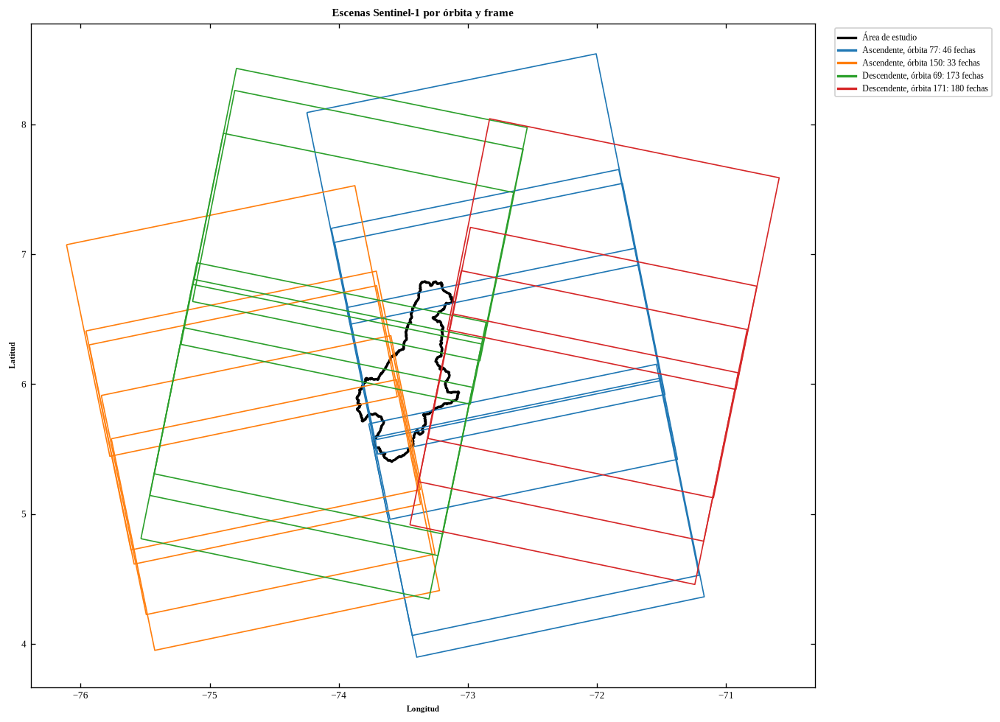

In [6]:
PLATAFORMA = asf.PLATFORM.SENTINEL1
MODO_HAZ = "IW"
NIVEL = "SLC"
TOLERANCIA_BUSQUEDA = 0.005  # grados
DIRECCIONES = {"ASCENDING": "Ascendente", "DESCENDING": "Descendente"}


# Convierte los resultados del catálogo en una tabla geográfica con una fila por escena
def tabla_escenas(resultados):
    filas = []
    for r in resultados:
        p = r.properties
        filas.append({
            "scene": p["sceneName"],
            "dir": p["flightDirection"],
            "path": p["pathNumber"],
            "frame": p["frameNumber"],
            "date": pd.to_datetime(p["startTime"]).tz_localize(None).normalize(),
            "geometry": shape(r.geometry),
        })
    tabla = gpd.GeoDataFrame(filas, crs=4326).drop_duplicates("scene")
    return tabla.sort_values(["dir", "path", "frame", "date"]).reset_index(drop=True)


# Búsqueda en el catálogo con el polígono del área simplificado
search_wkt = orient(geom_area.simplify(TOLERANCIA_BUSQUEDA)).wkt
res = asf.geo_search(
    intersectsWith=search_wkt,
    start=START,
    end=END,
    platform=PLATAFORMA,
    beamMode=MODO_HAZ,
    processingLevel=NIVEL,
)
res.raise_if_incomplete()
if len(res) == 0:
    raise RuntimeError("sin escenas")

scene_gdf = tabla_escenas(res)

# Resumen por dirección de vuelo y órbita
resumen_escenas = (
    scene_gdf.assign(sat=scene_gdf["scene"].str[:3])
    .groupby(["dir", "path"])
    .agg(
        escenas=("scene", "count"),
        fechas=("date", "nunique"),
        inicio=("date", "min"),
        fin=("date", "max"),
        satelites=("sat", lambda s: ", ".join(sorted(s.unique()))),
    )
    .reset_index()
    .sort_values("escenas", ascending=False)
    .reset_index(drop=True)
)

tabla = resumen_escenas.assign(
    dir=resumen_escenas["dir"].map(DIRECCIONES),
    inicio=resumen_escenas["inicio"].dt.date,
    fin=resumen_escenas["fin"].dt.date,
).rename(columns={
    "dir": "Dirección", "path": "Órbita", "escenas": "Escenas", "fechas": "Fechas", "inicio": "Inicio",
    "fin": "Fin", "satelites": "Satélites",
})

tabla_apa(tabla, "Escenas Sentinel-1 por órbita")

# Mapa: una huella por frame y un color por órbita
fig, ax = plt.subplots(figsize=(11, 9))
gdf_area.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=2)
leyenda = [Line2D([], [], color="black", lw=2, label="Área de estudio")]

orbitas = scene_gdf.groupby(["dir", "path"])
colores = plt.cm.tab10(np.arange(len(orbitas)) % 10)
for color, ((direccion, path), escenas) in zip(colores, orbitas):
    escenas.drop_duplicates("frame").boundary.plot(ax=ax, color=color, linewidth=1)
    etiqueta = f"{DIRECCIONES[direccion]}, órbita {path}: {escenas['date'].nunique()} fechas"
    leyenda.append(Line2D([], [], color=color, lw=2, label=etiqueta))

ax.legend(handles=leyenda, loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set(title="Escenas Sentinel-1 por órbita y frame", xlabel="Longitud", ylabel="Latitud")
fig.tight_layout()
plt.show()

## 6. Selección de stacks

Las escenas de cada órbita se agrupan en stacks por traslape de huellas, porque el número de frame cambia entre satélites. La cobertura de un stack es el área común a todas sus fechas. Por dirección de vuelo se conservan los stacks ya registrados en la tabla de pares; si no hay, se toma el de mayor cobertura y se agregan complementarios mientras aporten área nueva.

**Relleno.** Cuando satélites con cortes de escena distintos reducen el área común, queda una franja sin datos entre stacks vecinos. Un stack de relleno usa solo las escenas de los satélites de `RELLENOS`, cuya área común es mayor, sin imágenes nuevas.

| Parámetro | Valor | Qué define |
|---|---|---|
| `MIN_FECHAS` | 12 | Fechas mínimas de un stack |
| `MIN_COBERTURA_PCT` | 50 | Cobertura mínima del stack principal (%) |
| `TRASLAPE_MIN` | 0.75 | Traslape mínimo para que dos escenas sean del mismo stack |
| `MAX_DIAS_PUENTE` | 100 | Intervalo máximo entre fechas consecutivas (días) |
| `APORTE_MIN_PCT` | 1.0 | Área nueva mínima de un stack complementario (%) |
| `ATIPICAS_MAX_PCT` | 5 | Escenas con huella desplazada que se apartan de un stack (%) |
| `COBERTURA_META_PCT` | 99.5 | Cobertura con la que se dejan de agregar stacks (%) |

Stack,Criterio,Satélites,Fechas,Inicio,Fin,Intervalo máx. (días),Cobertura (%)
DESCENDING_R69_F572,ya procesado,"S1A, S1C, S1D",172,2022-03-14,2026-09-26,24,"82,8"
DESCENDING_R69_F567,ya procesado,"S1A, S1C, S1D",172,2022-03-14,2026-09-26,24,"15,0"
DESCENDING_R69_F572_S1A,relleno,S1A,125,2022-03-14,2026-06-21,24,"90,6"
ASCENDING_R77_F1199,ya procesado,"S1C, S1D",24,2025-05-03,2026-09-14,25,"95,3"


cobertura: Ascendente 95.3 % | Descendente 100.0 %


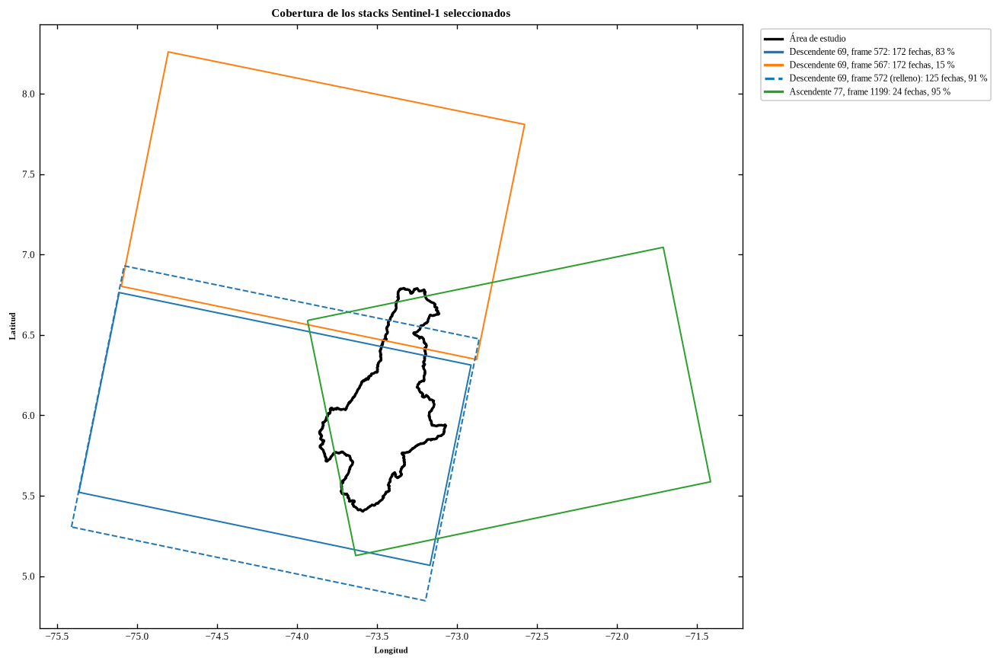

In [7]:
MIN_FECHAS = 12
MIN_COBERTURA_PCT = 50
TRASLAPE_MIN = 0.75
MAX_DIAS_PUENTE = 100  # días
APORTE_MIN_PCT = 1.0
ATIPICAS_MAX_PCT = 5
COBERTURA_META_PCT = 99.5
STACKS_FORZADOS = []
VER_TODOS = False

TITULOS = {
    "stack_id": "Stack",
    "criterio": "Criterio",
    "satelites": "Satélites",
    "n_fechas": "Fechas",
    "inicio": "Inicio",
    "fin": "Fin",
    "intervalo_max": "Intervalo máx. (días)",
    "cobertura_pct": "Cobertura (%)",
}

area_m2 = gdf_area.to_crs(EPSG_PROYECTO).area.iloc[0]


# Porcentaje del área de estudio cubierto por una geometría
def pct_area(g):
    if g is None or g.is_empty:
        return 0.0
    dentro = gpd.GeoSeries([g.intersection(geom_area)], crs=4326).to_crs(EPSG_PROYECTO)
    return 100 * dentro.area.iloc[0] / area_m2


# Une dos geometrías; la primera puede no existir todavía
def unir(a, b):
    return b if a is None else a.union(b)


# Indica si un stack está en la lista de excluidos
def excluido(stack_id):
    return any(x in stack_id for x in STACKS_EXCLUIDOS)


# Agrupa las escenas de una órbita por huella y devuelve el grupo de cada escena (F<frame>)
def agrupar_por_huella(escenas, frames_referencia):
    grupo = pd.Series(None, index=escenas.index, dtype=object)
    pendientes = list(frames_referencia)
    while grupo.isna().any():
        libres = escenas[grupo.isna()]
        conteo = libres["frame"].value_counts()
        frame = next((f for f in pendientes if f in conteo.index), conteo.index[0])
        if frame in pendientes:
            pendientes.remove(frame)
        del_frame = libres[libres["frame"] == frame]
        latitud = del_frame.geometry.apply(lambda g: g.centroid.y)
        tipica = del_frame.geometry.loc[(latitud - latitud.median()).abs().idxmin()]
        traslape = libres.geometry.apply(lambda g: g.intersection(tipica).area / max(g.area, tipica.area))
        nombre, k = f"F{frame}", 1
        while nombre in set(grupo.dropna()):
            k += 1
            nombre = f"F{frame}_{k}"
        grupo[traslape[traslape >= TRASLAPE_MIN].index] = nombre
    return grupo


# Área común a todas las huellas
def huella_comun(geometrias):
    geometrias = list(geometrias)
    comun = geometrias[0]
    for g in geometrias[1:]:
        comun = comun.intersection(g)
    return comun


# Una escena por fecha, del tramo más largo sin intervalos mayores que MAX_DIAS_PUENTE
def tramo_continuo(escenas):
    g = escenas.drop_duplicates("date").sort_values("date").reset_index(drop=True)
    tramo = (g["date"].diff().dt.days > MAX_DIAS_PUENTE).cumsum()
    return g[tramo == tramo.value_counts().idxmax()].reset_index(drop=True)


# Resume un stack: fechas del tramo continuo, huella común y cobertura
def resumir_stack(stack_id, escenas):
    tramo = tramo_continuo(escenas)
    huella = huella_comun(tramo.geometry)
    fechas = tramo["date"]
    fila = {
        "stack_id": stack_id,
        "dir": escenas["dir"].iloc[0],
        "path": int(escenas["path"].iloc[0]),
        "frame": int(re.search(r"_F(\d+)", stack_id).group(1)),
        "satelites": ", ".join(sorted(tramo["sat"].unique())),
        "n_fechas": len(tramo),
        "inicio": fechas.min(),
        "fin": fechas.max(),
        "intervalo_max": int(fechas.diff().dt.days.max()) if len(tramo) > 1 else 0,
        "cobertura_pct": pct_area(huella),
        "relleno_de": None,
        "geometry": huella,
    }
    return fila, tramo[["scene", "date"]].copy()


# Tabla de stacks con fechas sin hora, cobertura con un decimal y títulos legibles
def tabla_stacks(tabla):
    t = tabla[list(TITULOS)].copy()
    t["inicio"], t["fin"] = t["inicio"].dt.date, t["fin"].dt.date
    return t.round({"cobertura_pct": 1}).rename(columns=TITULOS).reset_index(drop=True)


# Stacks registrados en la tabla de pares: sus frames se usan primero para conservar los nombres
ids_registro = set()
if ARCHIVO_PARES.exists():
    ids_registro = set(pd.read_csv(ARCHIVO_PARES, usecols=["stack_id"])["stack_id"])

# 1. Agrupación de las escenas de cada órbita por huella
scene_gdf["sat"] = scene_gdf["scene"].str[:3]
scene_gdf["stack_id"] = None
for (direccion, path), escenas in scene_gdf.groupby(["dir", "path"]):
    prefijo = f"{direccion}_R{path}"
    frames_ref = [int(s.rsplit("_F", 1)[1]) for s in ids_registro if re.fullmatch(rf"{prefijo}_F\d+", s)]
    frames_ref.sort(key=lambda f: (excluido(f"{prefijo}_F{f}"), -(escenas["frame"] == f).sum()))
    grupos = agrupar_por_huella(escenas, frames_ref)
    scene_gdf.loc[grupos.index, "stack_id"] = [f"{prefijo}_{g}" for g in grupos]

# 2. Escenas con la huella desplazada: se apartan si son minoría y el stack gana cobertura sin ellas
for stack_id, escenas in list(scene_gdf.groupby("stack_id")):
    while True:
        cobertura = pct_area(huella_comun(escenas.geometry))
        conteo = escenas["frame"].value_counts()
        minoria = [f for f, n in conteo.items() if n <= len(escenas) * ATIPICAS_MAX_PCT / 100]
        ganancia = {
            f: pct_area(huella_comun(escenas.geometry[escenas["frame"] != f])) - cobertura for f in minoria
        }
        if not ganancia or max(ganancia.values()) < APORTE_MIN_PCT:
            break
        frame = max(ganancia, key=ganancia.get)
        fuera = escenas[escenas["frame"] == frame]
        scene_gdf.loc[fuera.index, "stack_id"] = f"{stack_id.rsplit('_F', 1)[0]}_F{frame}_aparte"
        print(f"{stack_id}: aparte frame {frame} ({len(fuera)} escenas, +{ganancia[frame]:.1f} %)")
        escenas = escenas[escenas["frame"] != frame]

# 3. Resumen de cada stack y de sus rellenos
filas, escenas_stack = [], {}
for stack_id, escenas in scene_gdf.groupby("stack_id"):
    fila, escenas_stack[stack_id] = resumir_stack(stack_id, escenas)
    filas.append(fila)
    en_tramo = escenas[escenas["scene"].isin(escenas_stack[stack_id]["scene"])]
    for sat in RELLENOS.get(stack_id, []):
        del_satelite = en_tramo[en_tramo["sat"] == sat]
        if len(del_satelite) >= MIN_FECHAS:
            fila, _ = resumir_stack(stack_id, del_satelite)
            filas.append({**fila, "stack_id": f"{stack_id}_{sat}", "relleno_de": stack_id})
stacks_gdf = gpd.GeoDataFrame(filas, crs=4326)

# 4. Selección por dirección de vuelo: stacks registrados, stack principal y complementarios
propios = stacks_gdf[stacks_gdf["relleno_de"].isna()]
candidatos = propios[(propios["n_fechas"] >= MIN_FECHAS) & ~propios["stack_id"].apply(excluido)]
seleccion, cubierto_dir = {}, {}
for direccion, cand in candidatos.groupby("dir"):
    registrados = cand[cand["stack_id"].isin(ids_registro)]
    cubierto = None
    for _, st in registrados.iterrows():
        seleccion[st["stack_id"]] = "ya procesado"
        cubierto = unir(cubierto, st["geometry"])
    if registrados.empty:
        orbitas = [cand.loc[cand["cobertura_pct"].idxmax(), "path"]]
    else:
        orbitas = sorted(set(registrados["path"]))
    for path in orbitas:
        while pct_area(cubierto) < COBERTURA_META_PCT:
            libres = cand[(cand["path"] == path) & ~cand["stack_id"].isin(list(seleccion))]
            if libres.empty:
                break
            aporte = libres.geometry.apply(
                lambda g: pct_area(g if cubierto is None else g.difference(cubierto))
            )
            libres = libres.assign(aporte=aporte.round(1))
            mejor = libres.sort_values(["aporte", "n_fechas"], ascending=False).iloc[0]
            if mejor["aporte"] < (MIN_COBERTURA_PCT if cubierto is None else APORTE_MIN_PCT):
                break
            seleccion[mejor["stack_id"]] = "principal" if cubierto is None else "complementario"
            cubierto = unir(cubierto, mejor["geometry"])
    cubierto_dir[direccion] = cubierto

for stack_id in STACKS_FORZADOS:
    forzado = propios[propios["stack_id"] == stack_id]
    if forzado.empty:
        print(f"{stack_id}: no existe")
    elif stack_id not in seleccion:
        st = forzado.iloc[0]
        seleccion[stack_id] = "forzado"
        cubierto_dir[st["dir"]] = unir(cubierto_dir.get(st["dir"]), st["geometry"])

# 5. Rellenos de los stacks seleccionados
for _, st in stacks_gdf[stacks_gdf["relleno_de"].isin(list(seleccion))].iterrows():
    seleccion[st["stack_id"]] = "relleno"
    cubierto_dir[st["dir"]] = unir(cubierto_dir.get(st["dir"]), st["geometry"])

stacks_gdf["criterio"] = stacks_gdf["stack_id"].map(seleccion).fillna("no seleccionado")
stacks_plan = (
    stacks_gdf[stacks_gdf["criterio"] != "no seleccionado"]
    .assign(es_relleno=lambda t: t["criterio"] == "relleno")
    .sort_values(["dir", "es_relleno", "cobertura_pct"], ascending=[False, True, False])
    .reset_index(drop=True)
)
stacks_sel = stacks_plan[~stacks_plan["es_relleno"]].reset_index(drop=True)

tabla_apa(tabla_stacks(stacks_plan), "Stacks seleccionados")
print("cobertura: "
      + " | ".join(f"{DIRECCIONES[d]} {pct_area(g):.1f} %" for d, g in cubierto_dir.items()))
if VER_TODOS:
    tabla_apa(tabla_stacks(stacks_gdf[stacks_gdf["n_fechas"] >= 2].sort_values("n_fechas", ascending=False)),
              "Todos los stacks encontrados")

# Mapa: huella común de cada stack seleccionado; los rellenos van en línea discontinua
fig, ax = plt.subplots(figsize=(11, 12))
gdf_area.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=2)
leyenda = [Line2D([], [], color="black", lw=2, label="Área de estudio")]
colores = dict(zip(stacks_sel["stack_id"], plt.cm.tab10(np.arange(len(stacks_sel)) % 10)))

for _, st in stacks_plan.iterrows():
    color = colores[st["relleno_de"] if st["es_relleno"] else st["stack_id"]]
    estilo = "--" if st["es_relleno"] else "-"
    huella = gpd.GeoSeries([st["geometry"]], crs=4326)
    huella.boundary.plot(ax=ax, color=color, linewidth=1.2, linestyle=estilo)
    etiqueta = (
        f"{DIRECCIONES[st['dir']]} {st['path']}, frame {st['frame']}"
        f"{' (relleno)' if st['es_relleno'] else ''}: {st['n_fechas']} fechas, {st['cobertura_pct']:.0f} %"
    )
    leyenda.append(Line2D([], [], color=color, lw=2, ls=estilo, label=etiqueta))

ax.legend(handles=leyenda, loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set(title="Cobertura de los stacks Sentinel-1 seleccionados", xlabel="Longitud", ylabel="Latitud")
fig.tight_layout()
plt.show()

## 7. Red de pares y envío

**Red de pares.** Se usa una red de pequeñas líneas base (SBAS), en la que cada fecha se combina con fechas cercanas para limitar la decorrelación temporal (Berardino et al., 2002). La red es de ancho de banda fijo: cada fecha se une con sus `BW` fechas siguientes, de modo que las conexiones 1 a `BW` quedan completas y forman triángulos para detectar errores de desenrollado. Además, cada fecha se une con la que está `NL` posiciones adelante.

**Pares de conexión `NL`.** En interferogramas multilook de banda C sobre vegetación y cultivos, los cambios de humedad del suelo y de la vegetación agregan una fase que no es consistente en el tiempo. Esa fase es mayor en los pares cortos y se desvanece al aumentar la línea base temporal, por lo que una red solo de pares cortos acumula un sesgo en la velocidad (De Zan et al., 2015; Ansari et al., 2021). El sesgo es mayor en cultivos y bosques que en zonas urbanas (Maghsoudi et al., 2022). Los pares de conexión `NL` no entran en la inversión: sirven para medir ese sesgo con la fase de cierre y restarlo (Zheng et al., 2022; sección 18). El método exige la red completa; por eso los pares fallidos se reenvían.

**Envío.** Un par se identifica por su stack y sus dos fechas, y no se envía si ya está en la tabla de pares, en el disco o en HyP3. Los pendientes salen del más reciente al más antiguo hasta donde alcancen los créditos; el resto se envía cuando se renueven. Cada par se procesa como un trabajo `INSAR_GAMMA` con el software GAMMA (Werner et al., 2000) y el modelo de elevación Copernicus GLO-30 (European Space Agency, 2022). Los stacks de relleno conservan su red: cada fecha con la siguiente y con la segunda si el intervalo no supera 60 días.

| Parámetro | Valor | Qué define |
|---|---|---|
| `COSTO_POR_PAR`, `CREDITOS_MES` | 10; 8000 | Créditos por par y cuota mensual |
| `N_VECINOS_RELLENO`, `MAX_DIAS_RELLENO` | 2; 60 | Red de los stacks de relleno |
| `STACKS_ENVIO`, `CREDITOS_MAX_ENVIO` | `None` | Limitan el envío a unos stacks o a un tope de créditos |
| `REINTENTAR_FALLIDOS` | `True` | Reenvía los pares que fallaron |
| `CONFIRMAR_ENVIO` | `True` | Pide confirmación antes de enviar |
| `looks` | `20x4` | Píxel de unos 80 m, que reduce el ruido y el volumen de datos |
| `include_dem`, `include_look_vectors` | `True` | Elevación y vector de mirada que necesita MintPy |
| `apply_water_mask` | `True` | Enmascara los cuerpos de agua |

In [8]:
COSTO_POR_PAR = 10  # créditos de HyP3 por interferograma
N_VECINOS_RELLENO = 2
MAX_DIAS_RELLENO = 60
CREDITOS_MES = 8000
STACKS_ENVIO = None
CREDITOS_MAX_ENVIO = None
REINTENTAR_FALLIDOS = True
CONFIRMAR_ENVIO = True
OPCIONES_HYP3 = {
    "looks": "20x4",
    "include_dem": True,
    "include_look_vectors": True,
    "apply_water_mask": True,
}

COLUMNAS_PARES = ["stack_id", "job_name", "ref", "sec", "fecha_ref", "fecha_sec", "dias"]
PATRON_PRODUCTO = re.compile(r"S1[A-D]{2}_(\d{8})T\d{6}_(\d{8})T\d{6}_")


# Fecha de adquisición a partir del nombre de la escena
def fecha_escena(nombre):
    return pd.Timestamp(nombre.split("_")[5][:8])


# Identificador de un par: stack y fechas, sin depender del nombre de las escenas
def clave_par(stack_id, fecha1, fecha2):
    f1, f2 = sorted([pd.Timestamp(fecha1), pd.Timestamp(fecha2)])
    return stack_id, f1.strftime("%Y%m%d"), f2.strftime("%Y%m%d")


# Identificadores de los pares de una tabla
def claves_de(tabla):
    return [clave_par(s, a, b) for s, a, b in zip(tabla["stack_id"], tabla["fecha_ref"], tabla["fecha_sec"])]


# Fila de un par para la tabla de pares, con su conexión cuando se conoce
def fila_par(stack_id, ref, sec, conexion=None):
    f1, f2 = fecha_escena(ref), fecha_escena(sec)
    return {
        "conexion": conexion,
        "stack_id": stack_id,
        "job_name": f"{RUN_ID}_{stack_id}",
        "ref": ref,
        "sec": sec,
        "fecha_ref": f1,
        "fecha_sec": f2,
        "dias": (f2 - f1).days,
    }


# Pares de la red de ancho de banda de un stack: conexiones 1 a BW y conexión NL, sin las fechas excluidas
def red_pares(escenas, stack_id):
    g = escenas[~escenas["date"].isin(excluidas_stack(stack_id))]
    escena = dict(zip(g["date"], g["scene"]))
    return [(escena[a], escena[b], c) for a, b, c in pares_banda(g["date"], BW, nl_stack(stack_id))]


# Pares de un stack de relleno: cada fecha con la siguiente y con las vecinas que no superen MAX_DIAS_RELLENO
def red_relleno(escenas):
    g = escenas.reset_index(drop=True)
    pares = []
    for i in range(len(g)):
        for j in range(i + 1, min(i + 1 + N_VECINOS_RELLENO, len(g))):
            dias = (g["date"].iloc[j] - g["date"].iloc[i]).days
            if j == i + 1 or dias <= MAX_DIAS_RELLENO:
                pares.append((g["scene"].iloc[i], g["scene"].iloc[j]))
    return pares


# Agrega pares a la tabla de pares, sin repetir stack y fechas
def agregar_pares(registro, nuevos):
    tablas = [t for t in (registro, nuevos) if not t.empty]
    union = pd.concat(tablas, ignore_index=True)[COLUMNAS_PARES]
    return union.drop_duplicates(["stack_id", "fecha_ref", "fecha_sec"], keep="last").reset_index(drop=True)


# Guarda la tabla de pares y deja una copia de respaldo de la versión anterior
def guardar_registro(tabla):
    if ARCHIVO_PARES.exists():
        sello = time.strftime("%Y%m%d_%H%M%S")
        shutil.copy(ARCHIVO_PARES, ARCHIVO_PARES.with_name(f"{ARCHIVO_PARES.stem}_respaldo_{sello}.csv"))
    ARCHIVO_PARES.parent.mkdir(parents=True, exist_ok=True)
    tabla[COLUMNAS_PARES].to_csv(ARCHIVO_PARES, index=False)


# Pares cuyos productos ya están en el disco, descomprimidos o recortados
def pares_en_disco(stack_ids):
    claves = set()
    for stack_id in stack_ids:
        for carpeta in (UNZIP_DIR, CLIP_DIR):
            carpeta_stack = carpeta / f"{RUN_ID}_{stack_id}"
            if not carpeta_stack.exists():
                continue
            for producto in carpeta_stack.iterdir():
                fechas = PATRON_PRODUCTO.match(producto.name)
                if producto.is_dir() and fechas:
                    claves.add(clave_par(stack_id, *fechas.groups()))
    return claves


# Trabajos de HyP3 de cada stack: los vigentes, con sus escenas, y los fallidos o vencidos sin descargar
def pares_en_hyp3(stack_ids):
    vigentes, fallidos = {}, set()
    for stack_id in stack_ids:
        nombre = f"{RUN_ID}_{stack_id}"
        for job in hyp3.find_jobs(name=nombre).jobs:
            escenas_job = (job.job_parameters or {}).get("granules") or []
            if len(escenas_job) != 2:
                continue
            clave = clave_par(stack_id, *map(fecha_escena, escenas_job))
            perdido = False
            if job.succeeded() and job.expired():
                producto = Path(job.files[0]["filename"]).stem
                perdido = not any((carpeta / nombre / producto).exists() for carpeta in (UNZIP_DIR, CLIP_DIR))
            if job.failed() or perdido:
                fallidos.add(clave)
            else:
                vigentes[clave] = sorted(escenas_job, key=fecha_escena)
    return vigentes, fallidos - set(vigentes)


# Pide confirmación; solo "s" o "sí" autorizan el envío
def confirmar(pregunta):
    try:
        respuesta = input(pregunta)
    except (EOFError, RuntimeError):
        return False
    return respuesta.strip().lower() in ("s", "si", "sí")


# Envía los pares a HyP3 y devuelve los que se enviaron y los que se rechazaron
def enviar_pares(pares):
    enviados, rechazados, seguidos = [], [], 0
    try:
        for p in barra(pares.itertuples(), "Enviando a HyP3"):
            try:
                hyp3.submit_insar_job(p.ref, p.sec, name=p.job_name, **OPCIONES_HYP3)
                enviados.append(p.Index)
                seguidos = 0
            except Exception as error:
                rechazados.append((p.ref, p.sec, str(error)[:200]))
                seguidos += 1
                if seguidos >= 3:
                    print("detenido: 3 errores seguidos")
                    break
    except KeyboardInterrupt:
        print("interrumpido")
    return enviados, rechazados


# 1. Red de cada stack seleccionado y de sus rellenos
filas = []
for stack_id in stacks_sel["stack_id"]:
    escenas = escenas_stack[stack_id]
    filas += [fila_par(stack_id, ref, sec, c) for ref, sec, c in red_pares(escenas, stack_id)]
    for sat in RELLENOS.get(stack_id, []):
        relleno = escenas[escenas["scene"].str[:3] == sat]
        filas += [fila_par(stack_id, ref, sec) for ref, sec in red_relleno(relleno)]
pares_calculados = pd.DataFrame(filas, columns=COLUMNAS_PARES + ["conexion"])
pares_calculados = pares_calculados.drop_duplicates(["stack_id", "ref", "sec"]).reset_index(drop=True)

# 2. Tabla de pares ya enviados
if ARCHIVO_PARES.exists():
    registro = pd.read_csv(ARCHIVO_PARES, parse_dates=["fecha_ref", "fecha_sec"])
    registro = registro.reindex(columns=COLUMNAS_PARES)
else:
    registro = pd.DataFrame(columns=COLUMNAS_PARES)
stack_ids = sorted(set(pares_calculados["stack_id"]) | set(registro["stack_id"]))

# 3. Pares que ya están en el disco o en HyP3; los de HyP3 que falten en la tabla se agregan
en_disco = pares_en_disco(stack_ids)
hay_sesion = "hyp3" in globals()
en_hyp3, fallidos = pares_en_hyp3(stack_ids) if hay_sesion else ({}, set())
fallidos -= en_disco
if not hay_sesion:
    print("sin sesión de HyP3 (sección 4)")

claves_registro = set(claves_de(registro))
sin_registrar = [
    fila_par(clave[0], *escenas) for clave, escenas in en_hyp3.items() if clave not in claves_registro
]
if sin_registrar:
    registro = agregar_pares(registro, pd.DataFrame(sin_registrar))
    claves_registro = set(claves_de(registro))
    guardar_registro(registro)
    print(f"+{len(sin_registrar)} pares de HyP3 a la tabla")

# 4. Pares pendientes, del más reciente al más antiguo
ya_estan = claves_registro | en_disco
falta = [REINTENTAR_FALLIDOS if c in fallidos else c not in ya_estan for c in claves_de(pares_calculados)]
pendientes = pares_calculados.loc[np.array(falta, dtype=bool)]
if STACKS_ENVIO is not None:
    pendientes = pendientes[pendientes["stack_id"].isin(STACKS_ENVIO)]
pendientes = pendientes.sort_values(["fecha_sec", "fecha_ref"], ascending=False).reset_index(drop=True)

# 5. Pares de este envío, según los créditos
creditos = hyp3.check_credits() if hay_sesion else None
limites = [x for x in (creditos, CREDITOS_MAX_ENVIO) if x is not None]
n_envio = min(len(pendientes), int(min(limites) // COSTO_POR_PAR)) if limites else len(pendientes)
pares_envio = pendientes.head(n_envio)
costo = len(pares_envio) * COSTO_POR_PAR

conexion_nl = pd.to_numeric(pendientes["conexion"], errors="coerce") > BW
tabla_envio = pd.DataFrame({
    "Pendientes": pendientes.groupby("stack_id").size(),
    "De conexión NL": pendientes[conexion_nl].groupby("stack_id").size(),
    "Por enviar": pares_envio.groupby("stack_id").size(),
}).fillna(0).astype(int)
tabla_envio["Créditos"] = tabla_envio["Por enviar"] * COSTO_POR_PAR
tabla_envio["Periodo por enviar"] = "-"
for stack_id, g in pares_envio.groupby("stack_id"):
    periodo = f"{g['fecha_ref'].min():%Y-%m} a {g['fecha_sec'].max():%Y-%m}"
    tabla_envio.loc[stack_id, "Periodo por enviar"] = periodo
if not pendientes.empty:
    pass

costo_total = len(pendientes) * COSTO_POR_PAR
resumen = [
    f"pendientes: {len(pendientes)} ({costo_total} créditos, {int(np.ceil(costo_total / CREDITOS_MES))} mes)",
    f"ahora: {len(pares_envio)} ({costo})",
    f"disponibles: {'?' if creditos is None else f'{creditos:.0f}'}",
]
if len(pendientes) > len(pares_envio):
    resumen.append(f"quedan {len(pendientes) - len(pares_envio)}")
if fallidos and not REINTENTAR_FALLIDOS:
    resumen.append(f"fallidos: {len(fallidos)}")
print(" | ".join(resumen))

# 6. Envío a HyP3, con confirmación
pregunta = f"¿enviar {len(pares_envio)} pares ({costo} créditos)? s/n: "
if pares_envio.empty:
    print("nada por enviar" if pendientes.empty else "sin créditos")
elif not hay_sesion:
    print("sin sesión de HyP3")
elif CONFIRMAR_ENVIO and not confirmar(pregunta):
    print("cancelado")
else:
    enviados, rechazados = enviar_pares(pares_envio)
    if enviados:
        registro = agregar_pares(registro, pares_envio.loc[enviados])
        guardar_registro(registro)
    for ref, sec, error in rechazados:
        print(f"error {ref[17:25]}-{sec[17:25]}: {error}")
    restantes = hyp3.check_credits()
    print(f"enviados: {len(enviados)}/{len(pares_envio)} | créditos: {restantes if restantes is not None else '?'}")

pendientes: 0 (0 créditos, 0 mes) | ahora: 0 (0) | disponibles: 7780
nada por enviar


## 8. Tabla de pares

Lee la tabla de pares enviados a HyP3 y define `JOBS_TODOS` (todos los stacks) y `JOBS` (los que entran al análisis, sin `STACKS_EXCLUIDOS`). `SUFIJOS` lista las capas de cada producto que usa MintPy: fase desenrollada, coherencia, elevación, vector de mirada y máscara de agua.

In [9]:
SUFIJOS = ["unw_phase", "corr", "dem", "lv_theta", "lv_phi", "water_mask"]

if not ARCHIVO_PARES.exists():
    raise FileNotFoundError(f"no existe {ARCHIVO_PARES}")

pares = pd.read_csv(ARCHIVO_PARES, parse_dates=["fecha_ref", "fecha_sec"])
JOBS_TODOS = list(pares["job_name"].unique())
JOBS = [j for j in JOBS_TODOS if not any(x in j for x in STACKS_EXCLUIDOS)]

resumen_pares = (
    pares.groupby(["stack_id", "job_name"])
    .agg(pares=("ref", "size"), inicio=("fecha_ref", "min"), fin=("fecha_sec", "max"))
    .reset_index()
)
tabla = pd.DataFrame({
    "Stack": resumen_pares["stack_id"],
    "Pares": resumen_pares["pares"],
    "Inicio": resumen_pares["inicio"].dt.date,
    "Fin": resumen_pares["fin"].dt.date,
    "Entra al análisis": resumen_pares["job_name"].isin(JOBS).map({True: "sí", False: "no"}),
})

tabla_apa(tabla, "Pares interferométricos enviados a HyP3 por stack")

Stack,Pares,Inicio,Fin,Entra al análisis
ASCENDING_R77_F1199,59,2025-05-03,2026-09-14,sí
ASCENDING_R77_F1200,33,2025-05-15,2026-09-02,no
DESCENDING_R69_F567,493,2022-03-14,2026-09-26,sí
DESCENDING_R69_F572,536,2022-03-14,2026-09-26,sí


## 9. Descarga

Consulta el estado de los trabajos de cada stack (ASF, s.f.-c), descarga los listos y extrae solo las capas de `SUFIJOS` y los metadatos, que es lo que lee MintPy (Yunjun et al., 2019). Cada producto se extrae en una carpeta temporal y se mueve al terminar, para no dejar productos a medias.

| Parámetro | Valor | Qué define |
|---|---|---|
| `CONSERVAR_ZIP` | `False` | Conserva el `.zip` después de extraerlo |
| `EXTRAER_TODO` | `False` | Extrae el producto completo |
| `DISCO_MIN_GB` | 20 | Espacio libre mínimo para seguir descargando (GB) |

In [10]:
CONSERVAR_ZIP = False
EXTRAER_TODO = False
DISCO_MIN_GB = 20


# Espacio libre en el disco del proyecto, en GB
def disco_libre_gb():
    return shutil.disk_usage(BASE_DIR).free / 1e9


# Indica si un archivo del producto se extrae: capas que usa MintPy y metadatos
def se_extrae(nombre):
    return EXTRAER_TODO or nombre.endswith(".txt") or any(nombre.endswith(f"_{s}.tif") for s in SUFIJOS)


# Extrae un producto en una carpeta temporal y lo mueve al final, para no dejar productos a medias
def extraer_producto(archivo_zip, destino):
    temporal = destino / "_extrayendo"
    shutil.rmtree(temporal, ignore_errors=True)
    with zipfile.ZipFile(archivo_zip) as zf:
        zf.extractall(temporal, members=[m for m in zf.namelist() if se_extrae(m)])
    for carpeta in temporal.iterdir():
        final = destino / carpeta.name
        shutil.rmtree(final, ignore_errors=True)
        carpeta.rename(final)
    temporal.rmdir()


# Descarga los productos listos de un stack que no estén en el disco y resume el estado de sus trabajos
def descargar_stack(job_name):
    trabajos = hyp3.find_jobs(name=job_name).jobs
    listos = [job for job in trabajos if job.succeeded()]
    fallidos = sum(job.failed() for job in trabajos)
    fila = {
        "stack": job_name,
        "total": len(trabajos),
        "exitosos": len(listos),
        "pendientes": len(trabajos) - len(listos) - fallidos,
        "fallidos": fallidos,
        "descargados": 0,
        "en_disco": 0,
        "vencidos": 0,
        "sin_espacio": False,
    }
    destino_zip, destino = DOWNLOAD_DIR / job_name, UNZIP_DIR / job_name
    destino_zip.mkdir(parents=True, exist_ok=True)
    destino.mkdir(parents=True, exist_ok=True)

    por_descargar = []
    for job in listos:
        producto = Path(job.files[0]["filename"]).stem
        if (destino / producto).exists() or (CLIP_DIR / job_name / producto).exists():
            fila["en_disco"] += 1
        elif job.expired():
            fila["vencidos"] += 1
        else:
            por_descargar.append(job)

    nombre = job_name.replace(f"{RUN_ID}_", "")
    for job in barra(por_descargar, nombre):
        if disco_libre_gb() < DISCO_MIN_GB:
            fila["sin_espacio"] = True
            break
        with contextlib.redirect_stderr(io.StringIO()):
            archivos = job.download_files(destino_zip)
        for archivo_zip in archivos:
            extraer_producto(archivo_zip, destino)
            if not CONSERVAR_ZIP:
                Path(archivo_zip).unlink()
        fila["descargados"] += 1
    return fila


filas = []
for job_name in JOBS_TODOS:
    filas.append(descargar_stack(job_name))
    if filas[-1]["sin_espacio"]:
        break
estado_hyp3 = pd.DataFrame(filas)

tabla = pd.DataFrame({
    "Stack": estado_hyp3["stack"].str.replace(f"{RUN_ID}_", "", regex=False),
    "Listos": estado_hyp3["exitosos"],
    "En proceso": estado_hyp3["pendientes"],
    "Fallidos": estado_hyp3["fallidos"],
    "Descargados": estado_hyp3["en_disco"] + estado_hyp3["descargados"],
})
print(f"descargados: {estado_hyp3['descargados'].sum()} | en proceso: {estado_hyp3['pendientes'].sum()} | "
      f"disco: {disco_libre_gb():.0f} GB")
if estado_hyp3["sin_espacio"].any():
    print(f"detenido: menos de {DISCO_MIN_GB} GB")
if estado_hyp3["vencidos"].sum():
    print(f"vencidos: {estado_hyp3['vencidos'].sum()} (reenviar en la sección 7)")

descargados: 0 | en proceso: 0 | disco: 105 GB


## 10. Recorte

MintPy requiere que todas las capas de un stack compartan la grilla. Para cada stack se calcula el rectángulo común como la intersección de los modelos de elevación de los pares, limitado a la extensión de los mapas más `MARGEN_RECORTE_M`, y se recortan las capas por ventanas, leyendo solo la porción necesaria (Gillies et al., 2013). Se copian los metadatos `.txt`, de los que MintPy toma fechas, líneas base y geometría. Si el rectángulo cambia, se recorta de nuevo todo el stack; si un stack cambia, su carpeta de MintPy se borra para cargarlo otra vez. El procedimiento reproduce la función `clip_hyp3_products_to_common_overlap` del tutorial de ASF (s.f.-b).

| Parámetro | Valor | Qué define |
|---|---|---|
| `RECORTAR_A_EXTENSION` | `True` | Limita el recorte a la extensión de los mapas |
| `MARGEN_RECORTE_M` | 1000 | Margen alrededor de la extensión (m) |
| `CONSERVAR_ANTERIORES` | `False` | Guarda la carpeta anterior de MintPy y los resultados de los stacks que cambian |

In [11]:
RECORTAR_A_EXTENSION = True
MARGEN_RECORTE_M = 1000
CONSERVAR_ANTERIORES = False

sello = time.strftime("%Y%m%d_%H%M")


# Indica si la carpeta de un par recortado tiene todas las capas y su archivo de metadatos
def recorte_completo(carpeta):
    if not carpeta.is_dir() or not (carpeta / f"{carpeta.name}.txt").exists():
        return False
    return all(any(carpeta.glob(f"*_{s}_clip.tif")) for s in SUFIJOS)


# Límites de un ráster: xmin, ymin, xmax, ymax
def limites_raster(archivo):
    with rasterio.open(archivo) as src:
        return src.bounds.left, src.bounds.bottom, src.bounds.right, src.bounds.top


# Rectángulo común a los productos de un stack y tamaño de píxel: intersección de los límites
# de los DEM, limitada a la extensión de los mapas y ajustada a la grilla de los productos
def rectangulo_comun(carpetas):
    limites, crs, pixel = [], None, None
    for carpeta in carpetas:
        dem = next(carpeta.glob("*_dem.tif"), None)
        if dem is not None:
            with rasterio.open(dem) as src:
                limites.append(src.bounds)
                crs, pixel = src.crs, src.res[0]
    if not limites:
        return None, None
    xmin, xmax = max(b.left for b in limites), min(b.right for b in limites)
    ymin, ymax = max(b.bottom for b in limites), min(b.top for b in limites)
    if RECORTAR_A_EXTENSION:
        x0, y0 = limites[0].left, limites[0].top
        ex0, ey0, ex1, ey1 = gdf_extension.to_crs(crs.to_wkt()).total_bounds
        xmin = max(xmin, x0 + np.floor((ex0 - MARGEN_RECORTE_M - x0) / pixel) * pixel)
        xmax = min(xmax, x0 + np.ceil((ex1 + MARGEN_RECORTE_M - x0) / pixel) * pixel)
        ymin = max(ymin, y0 + np.floor((ey0 - MARGEN_RECORTE_M - y0) / pixel) * pixel)
        ymax = min(ymax, y0 + np.ceil((ey1 + MARGEN_RECORTE_M - y0) / pixel) * pixel)
    return (xmin, ymin, xmax, ymax), pixel


# Recorta una capa al rectángulo leyendo solo la ventana necesaria
def recortar_capa(archivo, salida, rect):
    with rasterio.open(archivo) as src:
        ventana = from_bounds(*rect, transform=src.transform).round_offsets().round_lengths()
        ventana = ventana.intersection(Window(0, 0, src.width, src.height))
        datos = src.read(window=ventana)
        perfil = src.profile.copy()
        perfil.update(height=datos.shape[1], width=datos.shape[2], transform=src.window_transform(ventana))
    temporal = salida.with_name(salida.name + ".tmp")
    with rasterio.open(temporal, "w", **perfil) as dst:
        dst.write(datos)
    temporal.rename(salida)


# Recorta las capas de un par y copia sus metadatos; devuelve el número de capas escritas
def recortar_par(carpeta, salida_par, rect):
    salida_par.mkdir(exist_ok=True)
    escritas = 0
    for sufijo in SUFIJOS:
        archivo = next(carpeta.glob(f"*_{sufijo}.tif"), None)
        if archivo is None:
            continue
        salida = salida_par / f"{archivo.stem}_clip.tif"
        if not salida.exists():
            recortar_capa(archivo, salida, rect)
            escritas += 1
    for txt in carpeta.glob("*.txt"):
        if not (salida_par / txt.name).exists():
            shutil.copy(txt, salida_par / txt.name)
    return escritas


# Indica si MintPy cargó el stack antes de que se escribiera el recorte más reciente
def mintpy_desactualizado(job_name):
    cargado = MINTPY_ROOT / job_name / "inputs" / "ifgramStack.h5"
    recortes = [p.stat().st_mtime for p in (CLIP_DIR / job_name).glob("*/*_unw_phase_clip.tif")]
    return cargado.exists() and bool(recortes) and cargado.stat().st_mtime < max(recortes)


# Mueve la carpeta de MintPy del stack al respaldo, o la borra, para que el stack se cargue de nuevo
def apartar_mintpy(job_name):
    carpeta_mintpy = MINTPY_ROOT / job_name
    if not CONSERVAR_ANTERIORES:
        shutil.rmtree(carpeta_mintpy)
        return
    RESPALDO_MINTPY_DIR.mkdir(exist_ok=True)
    respaldo, k = RESPALDO_MINTPY_DIR / f"{job_name}_{sello}", 1
    while respaldo.exists():
        k += 1
        respaldo = RESPALDO_MINTPY_DIR / f"{job_name}_{sello}_{k}"
    carpeta_mintpy.rename(respaldo)


# Respalda los resultados anteriores, que se sobrescriben al repetir el análisis
def respaldar_resultados():
    prefijo = f"{RESULTADOS_DIR.name}_respaldo_"
    fechas = [p.stat().st_mtime for p in RESULTADOS_DIR.rglob("*") if p.is_file()]
    copias = []
    for p in BASE_DIR.glob(f"{prefijo}*"):
        try:
            copias.append(time.mktime(time.strptime(p.name[-13:], "%Y%m%d_%H%M")))
        except ValueError:
            pass
    if fechas and max(copias, default=0) < max(fechas) - 60:
        shutil.copytree(RESULTADOS_DIR, BASE_DIR / f"{prefijo}{sello}")


# Recorta un stack si tiene productos nuevos o si cambió su rectángulo de recorte;
# devuelve su fila del resumen y si MintPy debe cargarlo de nuevo
def recortar_stack(job_name, en_proceso):
    origen, destino = UNZIP_DIR / job_name, CLIP_DIR / job_name
    carpetas = []
    if origen.exists():
        carpetas = sorted(c for c in origen.iterdir() if c.is_dir() and not c.name.startswith("_"))
    listos = {c.name for c in destino.iterdir() if recorte_completo(c)} if destino.exists() else set()
    nuevos = [c for c in carpetas if c.name not in listos]
    nombre = job_name.replace(f"{RUN_ID}_", "")
    fila = {"Stack": nombre, "Recortados": len(listos), "Nuevos": 0, "Resultado": "sin cambios"}
    if not carpetas and not listos:
        fila["Resultado"] = "sin productos"
        return fila, False

    # Rectángulo de recorte y comparación con el de los pares ya recortados
    rect, rehacer = None, False
    if carpetas:
        rect, pixel = rectangulo_comun(carpetas)
        if rect is None:
            fila["Resultado"] = "sin DEM"
            return fila, False
        if rect[0] >= rect[2] or rect[1] >= rect[3]:
            raise ValueError(f"{job_name}: sin área común")
        if listos:
            actual = limites_raster(next((destino / sorted(listos)[0]).glob("*_dem_clip.tif")))
            rehacer = any(abs(a - b) > pixel / 2 for a, b in zip(actual, rect))
    if (nuevos or rehacer) and en_proceso:
        fila["Resultado"] = f"espera ({en_proceso} en HyP3)"
        return fila, False

    escritas = 0
    if nuevos or rehacer:
        # Si el rectángulo cambió se recortan de nuevo todos los pares; el recorte anterior
        # se aparta y se borra cuando el nuevo queda completo
        if rehacer:
            sin_original = listos - {c.name for c in carpetas}
            if sin_original:
                fila["Resultado"] = (
                    f"sin cambios ({len(sin_original)} sin descomprimir)"
                )
                return fila, False
            CLIP_ANTERIOR_DIR.mkdir(exist_ok=True)
            destino.rename(CLIP_ANTERIOR_DIR / f"{job_name}_{time.strftime('%Y%m%d_%H%M%S')}")
        destino.mkdir(parents=True, exist_ok=True)

        for carpeta in barra(carpetas, nombre):
            if not recorte_completo(destino / carpeta.name):
                escritas += recortar_par(carpeta, destino / carpeta.name, rect)
        for anterior in CLIP_ANTERIOR_DIR.glob(f"{job_name}_*"):
            shutil.rmtree(anterior)

    desactualizado = mintpy_desactualizado(job_name)
    if desactualizado:
        apartar_mintpy(job_name)
    if escritas:
        fila["Recortados"] = sum(1 for c in destino.iterdir() if recorte_completo(c))
        fila["Nuevos"] = len(nuevos)
        fila["Resultado"] = "recortado de nuevo" if rehacer else "recortado"
    elif nuevos:
        fila["Resultado"] = f"sin cambios ({len(nuevos)} incompletos)"
    return fila, desactualizado or bool(escritas)


# Un stack con trabajos en proceso en HyP3 no se recorta hasta que terminen
en_proceso = {}
if "estado_hyp3" in globals():
    en_proceso = dict(zip(estado_hyp3["stack"], estado_hyp3["pendientes"]))

filas, modificados = [], []
for job_name in JOBS_TODOS:
    fila, cambio = recortar_stack(job_name, en_proceso.get(job_name, 0))
    filas.append(fila)
    if cambio:
        modificados.append(job_name)

if modificados and CONSERVAR_ANTERIORES:
    respaldar_resultados()

print("a MintPy de nuevo:", ", ".join(j.replace(f"{RUN_ID}_", "") for j in modificados) or "-")

a MintPy de nuevo: -


## 11. Verificación de los insumos

Revisa, para cada par de `JOBS`, que existan todas las capas recortadas y el archivo `.txt`, que la grilla sea la misma en todo el stack, y lee las fechas y la línea base perpendicular. Los productos de HyP3 nombran las fechas de referencia y secundaria en el segundo y el tercer campo (ASF, s.f.-d). El resultado queda en `insumos` para las secciones 13 y 15; los stacks sin productos recortados se retiran de `JOBS`.

In [12]:
# Fechas de referencia y secundaria a partir del nombre del producto
def fechas_desde_producto(nombre):
    partes = nombre.split("_")
    return pd.Timestamp(partes[1][:8]), pd.Timestamp(partes[2][:8])


# Línea base perpendicular, en metros, del archivo de metadatos; NaN si no se puede leer
def leer_baseline(txt):
    try:
        for linea in Path(txt).read_text().splitlines():
            if linea.strip().lower().startswith("baseline"):
                return float(linea.split(":")[1])
    except (OSError, ValueError, IndexError):
        pass
    return np.nan


# Forma, transformación geográfica y sistema de referencia de un ráster
def grilla_de(archivo):
    with rasterio.open(archivo) as src:
        return src.shape, tuple(round(v, 3) for v in src.transform[:6]), src.crs.to_epsg()


# Revisa las capas, los metadatos y la grilla de cada par de un stack
def verificar_stack(job_name):
    filas, grilla_ref = [], None
    for carpeta in sorted(c for c in (CLIP_DIR / job_name).iterdir() if c.is_dir()):
        f1, f2 = fechas_desde_producto(carpeta.name)
        fila = {"producto": carpeta.name, "fecha1": f1, "fecha2": f2, "dias": (f2 - f1).days}
        fila["misma_grilla"] = True
        for sufijo in SUFIJOS:
            archivo = next(carpeta.glob(f"*_{sufijo}_clip.tif"), None)
            fila[sufijo] = archivo is not None
            if archivo is not None:
                grilla = grilla_de(archivo)
                grilla_ref = grilla_ref or grilla
                fila["misma_grilla"] &= grilla == grilla_ref
        txt = carpeta / f"{carpeta.name}.txt"
        fila["txt"] = txt.exists()
        fila["bperp_m"] = leer_baseline(txt)
        filas.append(fila)
    tabla = pd.DataFrame(filas)
    tabla.attrs["grilla"] = grilla_ref
    return tabla


REVISION = SUFIJOS + ["txt", "misma_grilla"]
JOBS = [j for j in JOBS_TODOS if not any(x in j for x in STACKS_EXCLUIDOS)]
insumos, filas, sin_insumos = {}, [], []
for job_name in JOBS:
    carpeta_stack = CLIP_DIR / job_name
    tabla = verificar_stack(job_name) if carpeta_stack.exists() else pd.DataFrame()
    if tabla.empty or tabla.attrs["grilla"] is None:
        sin_insumos.append(job_name)
        continue
    insumos[job_name] = tabla
    incompletos = tabla[~tabla[REVISION].all(axis=1)]
    forma, _, epsg = tabla.attrs["grilla"]
    filas.append({
        "Stack": job_name.replace(f"{RUN_ID}_", ""),
        "Pares recortados": len(tabla),
        "Faltan": max(int((pares["job_name"] == job_name).sum()) - len(tabla), 0),
        "Fechas": pd.concat([tabla["fecha1"], tabla["fecha2"]]).nunique(),
        "Grilla (filas × columnas)": f"{forma[0]} × {forma[1]}",
        "Incompletos": len(incompletos),
    })
    if not incompletos.empty:
        tabla_apa(incompletos[["producto"] + REVISION], f"Pares incompletos de {nombre_stack(job_name)}")

JOBS = [j for j in JOBS if j in insumos]
resumen_insumos = pd.DataFrame(filas)
if filas:
    pass
if sin_insumos:
    print("sin recortes:",
          ", ".join(j.replace(f"{RUN_ID}_", "") for j in sin_insumos))

# Análisis de series temporales con MintPy

MintPy estima la serie temporal de desplazamiento en la línea de vista del satélite (LOS) a partir de un stack de interferogramas desenrollados, invirtiendo la red de pequeñas líneas base y corrigiendo las principales fuentes de ruido (Yunjun et al., 2019). Su programa `smallbaselineApp.py` ejecuta en orden:

`load_data → modify_network → reference_point → quick_overview → correct_unwrap_error → invert_network → correct_LOD → correct_SET → correct_ionosphere → correct_troposphere → deramp → correct_topography → residual_RMS → reference_date → velocity → geocode → google_earth → hdfeos5`

Entre `invert_network` y `correct_LOD` se resta el sesgo de cierre de fase, estimado con `closure_phase_bias.py` (Zheng et al., 2022; secciones 18 y 19). El procesamiento va por bloques, para revisar la red antes de invertirla (EarthScope Consortium, 2026). Los productos de HyP3 ya están en coordenadas UTM, por lo que `geocode` no los modifica.

## 12. Entorno de MintPy

MintPy se instala en un entorno conda propio, para evitar conflictos de GDAL y PROJ con el núcleo del notebook, junto con PyAPS3 (retardo troposférico; Jolivet et al., 2011), PySolid (mareas terrestres; Yunjun et al., 2022) e ISCE2, que aporta SNAPHU para desenrollar las fases de cierre (Chen y Zebker, 2001; Rosen et al., 2018).

`ejecutar_mintpy` corre cada herramienta como proceso externo en la carpeta del stack y guarda la salida en un registro (`log_mintpy.txt`). Mientras corre, muestra un panel con el paso de MintPy, el avance del paso, el tiempo y el último mensaje; el panel desaparece al terminar. Si hay un error, muestra las últimas líneas del registro. Al final se imprimen las versiones de MintPy, PyAPS3, PySolid e ISCE2, que se reportan en la metodología.

In [13]:
MINTPY_ENV = Path.home() / ".conda" / "envs" / "mintpy"
MINTPY_PYTHON = MINTPY_ENV / "bin" / "python"
PAQUETES_MINTPY = ["python=3.11", "mintpy>=1.6.1", "pyaps3>=0.3.6", "pysolid", "isce2", "gdal", "h5py"]
LINEAS_ERROR = 25


# Crea el entorno conda de MintPy
def crear_entorno():
    gestor = shutil.which("mamba") or shutil.which("conda")
    if gestor is None:
        raise RuntimeError("falta conda")
    orden = [gestor, "create", "-y", "-p", str(MINTPY_ENV), "-c", "conda-forge", *PAQUETES_MINTPY]
    subprocess.run(orden, check=True)


# Instala paquetes en el entorno de MintPy ya creado
def instalar_en_entorno(paquetes):
    gestor = shutil.which("mamba") or shutil.which("conda")
    if gestor is None:
        raise RuntimeError("falta conda")
    orden = [gestor, "install", "-y", "-p", str(MINTPY_ENV), "-c", "conda-forge", *paquetes]
    subprocess.run(orden, check=True)


# Variables de entorno del proceso: rutas de PROJ y GDAL del entorno y modo gráfico sin pantalla
def entorno_mintpy():
    env = os.environ.copy()
    env["PATH"] = f"{MINTPY_ENV / 'bin'}{os.pathsep}{env.get('PATH', '')}"
    env["PROJ_DATA"] = env["PROJ_LIB"] = str(MINTPY_ENV / "share" / "proj")
    env["GDAL_DATA"] = str(MINTPY_ENV / "share" / "gdal")
    env["MPLBACKEND"] = "Agg"
    return env


PASOS_SMALLBASELINE = [
    "load_data", "modify_network", "reference_point", "quick_overview", "correct_unwrap_error", "invert_network",
    "correct_LOD", "correct_SET", "correct_ionosphere", "correct_troposphere", "deramp", "correct_topography",
    "residual_RMS", "reference_date", "velocity", "geocode", "google_earth", "hdfeos5",
]
PATRON_PASO = re.compile(r"step - (\w+)")
PATRON_AVANCE = re.compile(r"(\d{1,3})%\s*\]\s*(.*)")


# Pasos de smallbaselineApp que cubre una orden, según --start y --end
def pasos_de_orden(args):
    args = [str(a) for a in args]
    primero = args[args.index("--start") + 1] if "--start" in args else PASOS_SMALLBASELINE[0]
    ultimo = args[args.index("--end") + 1] if "--end" in args else PASOS_SMALLBASELINE[-1]
    return PASOS_SMALLBASELINE[PASOS_SMALLBASELINE.index(primero):PASOS_SMALLBASELINE.index(ultimo) + 1]


# Panel del avance de una herramienta de MintPy: paso, avance del paso, tiempo y último mensaje
def panel_mintpy(titulo, pasos, paso, avance, detalle, mensaje, segundos):
    partes = [f'<div style="font-size:13px;font-weight:600;margin-top:4px">{html.escape(titulo)} · {duracion(segundos)}</div>']
    if pasos:
        k = pasos.index(paso) if paso in pasos else 0
        partes.append(html_barra(f"Paso {k + 1} de {len(pasos)}: {pasos[k]}", (k + (avance or 0) / 100) / len(pasos)))
    partes.append(html_barra("Avance del paso" if pasos else "Avance", None if avance is None else avance / 100, detalle))
    partes.append(f'<div style="font-family:monospace;font-size:11.5px;opacity:0.7;margin:2px 0 6px">'
                  f'{html.escape(mensaje)}</div>')
    return HTML("".join(partes))


# Ejecuta una herramienta de MintPy en la carpeta del stack: guarda la salida en el registro y muestra el avance
def ejecutar_mintpy(modulo, args, cwd, log_nombre="log_mintpy.txt", check=True):
    cwd = Path(cwd)
    orden = [str(MINTPY_PYTHON), "-m", f"mintpy.cli.{modulo}", *map(str, args)]
    log = cwd / log_nombre
    titulo = f"{modulo} · {cwd.name.replace(f'{RUN_ID}_', '')}"
    pasos = pasos_de_orden(args) if modulo == "smallbaselineApp" else []
    paso, avance, detalle, mensaje = (pasos[0] if pasos else ""), None, "", "iniciando"
    salida = display(HTML(""), display_id=True)
    inicio = ultimo = time.time()
    with open(log, "a", encoding="utf-8") as f:
        f.write(f"\n\n===== {time.strftime('%Y-%m-%d %H:%M:%S')} :: {' '.join(orden[2:])}\n")
        f.flush()
        proceso = subprocess.Popen(orden, cwd=cwd, env=entorno_mintpy(), stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT)
        resto = ""
        while True:
            bloque = proceso.stdout.read1(65536)
            if not bloque:
                break
            texto = bloque.decode("utf-8", errors="ignore")
            f.write(texto)
            lineas = re.split(r"[\r\n]", resto + texto)
            resto = lineas.pop()
            for linea in (l.strip() for l in lineas):
                if not linea:
                    continue
                nuevo_paso = PATRON_PASO.search(linea)
                avance_mintpy = PATRON_AVANCE.search(linea) if linea.startswith("[") else None
                if nuevo_paso:
                    paso, avance, detalle = nuevo_paso.group(1), None, ""
                elif avance_mintpy:
                    avance, detalle = int(avance_mintpy.group(1)), avance_mintpy.group(2)[:70]
                else:
                    mensaje = linea[:160]
            if time.time() - ultimo > 0.5:
                salida.update(panel_mintpy(titulo, pasos, paso, avance, detalle, mensaje, time.time() - inicio))
                ultimo = time.time()
        proceso.wait()
    salida.update(HTML(""))
    if proceso.returncode != 0:
        cola = log.read_text(encoding="utf-8", errors="ignore").splitlines()[-LINEAS_ERROR:]
        print(f"error en {modulo} ({cwd.name}, código {proceso.returncode}):")
        print("\n".join(cola))
        if check:
            raise RuntimeError(f"{modulo} falló")
    return proceso.returncode


if not MINTPY_PYTHON.exists():
    crear_entorno()
prueba_isce = subprocess.run([str(MINTPY_PYTHON), "-c", "import isce"], capture_output=True, env=entorno_mintpy())
if prueba_isce.returncode != 0:
    instalar_en_entorno(["isce2"])

consulta = (
    "import mintpy, pyaps3, pysolid, isce; "
    "print(f'MintPy {mintpy.__version__} | PyAPS3 {pyaps3.__version__} | PySolid {pysolid.__version__} "
    "| ISCE2 {getattr(isce, \"__version__\", \"instalado\")}')"
)
versiones = subprocess.run(
    [str(MINTPY_PYTHON), "-c", consulta], capture_output=True, text=True, env=entorno_mintpy()
)
print((versiones.stdout.strip().splitlines() or [versiones.stderr.strip()[-400:]])[-1])

MintPy 1.6.4 | PyAPS3 0.3.7 | PySolid 0.3.4 | ISCE2 2.6.5


## 12b. Ayuda de MintPy de la versión instalada

**Qué hace esta celda.** Guarda y muestra el texto de ayuda oficial de la versión de MintPy instalada: la plantilla de opciones de `smallbaselineApp.py` (`-H`) y la ayuda de `closure_phase_bias.py` (`-h`). Sirve para comprobar, contra la propia documentación de la versión usada, el significado y el valor por defecto de cada opción que el notebook escribe en el archivo de configuración (`reference.*`, `networkInversion.*`, `unwrapError.*`, `troposphericDelay.*`, `deramp`, `topographicResidual.*`, `timeFunc.*`) y de `--bw`, `--nl`, `--numsigma` y `--epi`. Los textos quedan en `03_resultados/tablas/mintpy_plantilla_opciones.txt` y `mintpy_closure_phase_bias_ayuda.txt`.

In [14]:
# Texto de ayuda de MintPy en la version instalada, para documentar cada opcion usada
def texto_ayuda(modulo, bandera):
    resultado = subprocess.run([str(MINTPY_PYTHON), "-m", f"mintpy.cli.{modulo}", bandera], env=entorno_mintpy(),
                               capture_output=True, text=True)
    return resultado.stdout + resultado.stderr


plantilla = texto_ayuda("smallbaselineApp", "-H")
ayuda_sesgo = texto_ayuda("closure_phase_bias", "-h")
(TABLAS_DIR / "mintpy_plantilla_opciones.txt").write_text(plantilla, encoding="utf-8")
(TABLAS_DIR / "mintpy_closure_phase_bias_ayuda.txt").write_text(ayuda_sesgo, encoding="utf-8")
print("===== closure_phase_bias.py -h =====")
print(ayuda_sesgo)
print("===== smallbaselineApp.py -H (plantilla de opciones) =====")
print(plantilla)


===== closure_phase_bias.py -h =====
usage: closure_phase_bias.py [-h] [-i STACK_FILE] [--wm WATER_MASK_FILE]
                             [--nl NL] [--bw BW]
                             [-a {mask,quick_estimate,estimate}]
                             [--num-sigma NUM_SIGMA] [--eps EPSILON]
                             [-c {lsf,pbs,slurm,local}]
                             [--num-worker NUMWORKER] [--config CONFIG]
                             [--ram MAXMEMORY] [-o OUTDIR]

Phase non-closure related biases correction

options:
  -h, --help            show this help message and exit
  -i STACK_FILE, --ifgramstack STACK_FILE
                        interferogram stack file that contains the unwrapped phases
  --wm WATER_MASK_FILE, --water-mask WATER_MASK_FILE
                        Water mask to skip pixels on water body.
                        Default: waterMask.h5 if exists, otherwise None.
  --nl NL, --conn-level NL
                        connection level that we are correcting t

## 13. Red de interferogramas

Para cada stack se revisa:

- **Conectividad:** las fechas deben formar una sola red; si se divide, la inversión no determina el desplazamiento entre las partes (Berardino et al., 2002).
- **Triángulos:** ciclos de tres pares cuya fase debe sumar cerca de cero; permiten detectar errores de desenrollado (Yunjun et al., 2019).
- **Red completa:** deben estar todos los pares de las conexiones 1 a `BW` y de la conexión `NL`; la estimación del sesgo de cierre no se puede hacer si falta uno (Zheng, 2022).
- **Línea base perpendicular** de cada fecha, estimada por mínimos cuadrados.

La figura dibuja la red en el espacio tiempo-Bperp: en azul las conexiones 1 a `BW`, que entran en la inversión; en naranja la conexión `NL`, que solo mide la fase de cierre; y en gris los pares del stack de relleno que no entran en la inversión. Si la red no está completa, se listan los pares que faltan; se completa con la sección 7 o, si un par vuelve a fallar, agregando una de sus fechas a `FECHAS_EXCLUIDAS`.

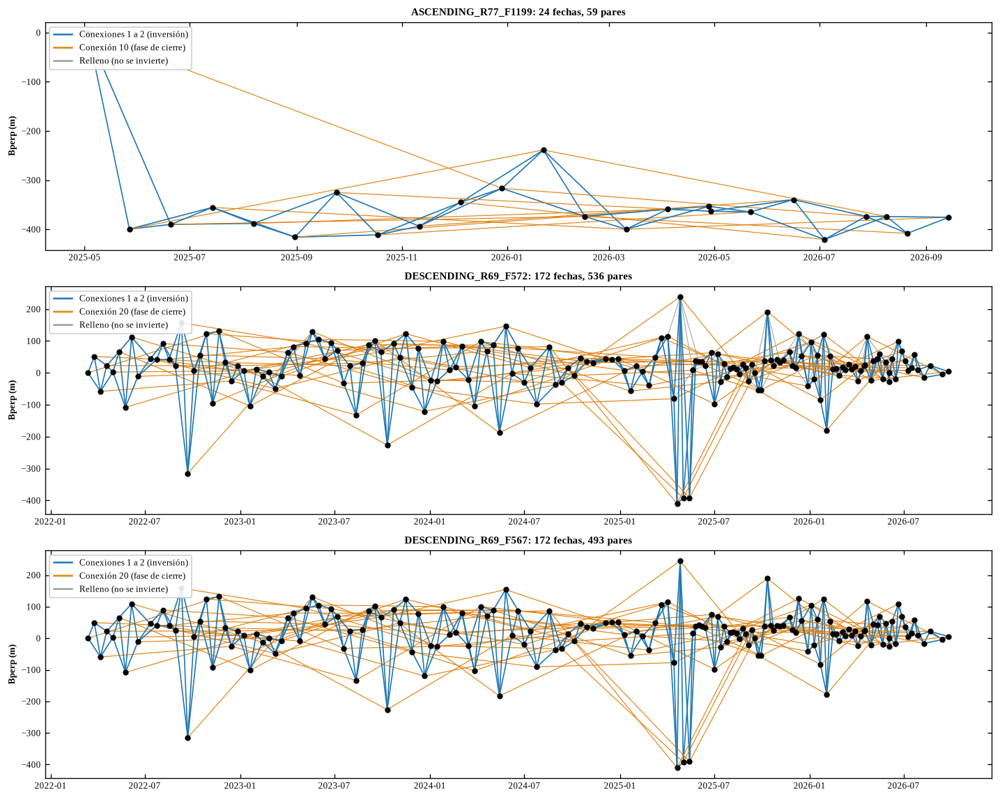

Stack,Fechas,Pares,Componentes,Triángulos,Conexiones 1 a 2,NL,Pares NL,Duración NL (días),Completa
ASCENDING_R77_F1199,24,59,1,22,45 de 45,10,14 de 14,187 a 240,sí
DESCENDING_R69_F572,172,536,1,230,341 de 341,20,152 de 152,108 a 264,sí
DESCENDING_R69_F567,172,493,1,170,341 de 341,20,152 de 152,108 a 264,sí


In [15]:
# Número de componentes conectadas de la red, por conjuntos disjuntos
def contar_componentes(n_fechas, aristas):
    padre = list(range(n_fechas))

    def raiz(i):
        while padre[i] != i:
            padre[i] = padre[padre[i]]
            i = padre[i]
        return i

    for a, b in aristas:
        padre[raiz(a)] = raiz(b)
    return len({raiz(i) for i in range(n_fechas)})


# Número de triángulos de la red: ciclos de tres pares entre tres fechas
def contar_triangulos(aristas):
    aristas = set(aristas)
    return sum(1 for i, j in aristas for j2, k in aristas if j2 == j and (i, k) in aristas)


# Línea base perpendicular de cada fecha respecto de la primera, por mínimos cuadrados
def bperp_por_fecha(aristas, bperp_pares, n_fechas):
    if n_fechas < 2:
        return np.zeros(n_fechas)
    A = np.zeros((len(aristas), n_fechas))
    for fila, (a, b) in enumerate(aristas):
        A[fila, a], A[fila, b] = -1, 1
    solucion = np.linalg.lstsq(A[:, 1:], bperp_pares, rcond=None)[0]
    return np.r_[0, solucion]


# Analiza la red de un stack: fechas, componentes, triángulos y Bperp de cada fecha
def analizar_red(tabla):
    fechas = sorted(set(tabla["fecha1"]) | set(tabla["fecha2"]))
    idx = {f: i for i, f in enumerate(fechas)}
    aristas = [(idx[a], idx[b]) for a, b in zip(tabla["fecha1"], tabla["fecha2"])]
    bperp = bperp_por_fecha(aristas, tabla["bperp_m"].fillna(0).to_numpy(), len(fechas))
    return fechas, contar_componentes(len(fechas), aristas), contar_triangulos(aristas), bperp


if not JOBS:
    raise RuntimeError("sin stacks recortados (secciones 9 a 11)")

info_red = []
fig, axes = plt.subplots(len(JOBS), 1, figsize=(12, 3.2 * len(JOBS)), squeeze=False)
for ax, job_name in zip(axes[:, 0], JOBS):
    tabla = insumos[job_name]
    fechas, n_componentes, n_triangulos, bperp = analizar_red(tabla)
    nombre = job_name.replace(f"{RUN_ID}_", "")
    info_red.append({
        "Stack": nombre,
        "Fechas": len(fechas),
        "Pares": len(tabla),
        "Componentes": n_componentes,
        "Triángulos": n_triangulos,
    })

    posicion = dict(zip(fechas, bperp))
    orden = {f: i for i, f in enumerate(fechas)}
    nl = nl_stack(nombre)
    estilos = {"banda": ("#1f77b4", 1.0), "nl": ("#e08214", 0.7), "otro": ("#9e9e9e", 0.6)}
    for a, b in zip(tabla["fecha1"], tabla["fecha2"]):
        conexion = orden[b] - orden[a]
        tipo = "banda" if conexion <= BW else "nl" if conexion == nl else "otro"
        ax.plot([a, b], [posicion[a], posicion[b]], "-", color=estilos[tipo][0], lw=estilos[tipo][1])
    ax.plot(fechas, bperp, "o", color="k", ms=4)
    leyenda = [Line2D([], [], color=estilos["banda"][0], lw=1.5, label=f"Conexiones 1 a {BW} (inversión)"),
               Line2D([], [], color=estilos["nl"][0], lw=1.5, label=f"Conexión {nl} (fase de cierre)"),
               Line2D([], [], color=estilos["otro"][0], lw=1.5, label="Relleno (no se invierte)")]
    ax.legend(handles=leyenda, loc="upper left", fontsize=8)
    ax.set(title=f"{nombre}: {len(fechas)} fechas, {len(tabla)} pares", ylabel="Bperp (m)")

fig.tight_layout()
plt.show()

info_red = pd.DataFrame(info_red)
for fila in info_red[info_red["Componentes"] > 1].itertuples():
    print(f"{fila.Stack}: red dividida en {fila.Componentes}")


# Pares esperados de la red de ancho de banda de un stack y si están en él
def completitud_red(nombre, tabla):
    fechas = sorted((set(tabla["fecha1"]) | set(tabla["fecha2"])) - excluidas_stack(nombre))
    presentes = set(zip(tabla["fecha1"], tabla["fecha2"]))
    esperados = pares_banda(fechas, BW, nl_stack(nombre))
    return pd.DataFrame([{"conexion": c, "fecha1": a, "fecha2": b, "presente": (a, b) in presentes}
                         for a, b, c in esperados])


red_completa, filas = {}, []
for job_name in JOBS:
    nombre = job_name.replace(f"{RUN_ID}_", "")
    nl = nl_stack(nombre)
    t = completitud_red(nombre, insumos[job_name])
    faltan = t[~t["presente"]]
    red_completa[job_name] = faltan.empty
    banda, largos = t[t["conexion"] <= BW], t[t["conexion"] == nl]
    dias = (largos["fecha2"] - largos["fecha1"]).dt.days
    filas.append({
        "Stack": nombre,
        f"Conexiones 1 a {BW}": f"{int(banda['presente'].sum())} de {len(banda)}",
        "NL": nl,
        "Pares NL": f"{int(largos['presente'].sum())} de {len(largos)}",
        "Duración NL (días)": f"{dias.min()} a {dias.max()}" if len(dias) else "-",
        "Completa": "sí" if faltan.empty else "no",
    })
    if not faltan.empty:
        lista = ", ".join(f"{a:%Y%m%d}_{b:%Y%m%d}" for a, b in zip(faltan["fecha1"], faltan["fecha2"]))
        print(f"{nombre}: faltan {len(faltan)}: {lista}")

tabla_apa(info_red.merge(pd.DataFrame(filas), on="Stack"), "Red de interferogramas por stack")
if not all(red_completa.values()):
    print("red incompleta: sección 7, o FECHAS_EXCLUIDAS si el par vuelve a fallar")

## 14. Acceso a ERA5

El retardo troposférico estratificado, ligado a la altura del terreno, se corrige con el reanálisis ERA5 (Hersbach et al., 2020) mediante PyAPS (Jolivet et al., 2011). La descarga requiere una cuenta del Copernicus Climate Data Store y el archivo `~/.cdsapirc` con el token, que se pide con `getpass` y no queda en el notebook. Sin token, `METODO_TROPO` pasa al método empírico `height_correlation` (Doin et al., 2009).

In [16]:
CDSRC = Path.home() / ".cdsapirc"
CDS_URL = "https://cds.climate.copernicus.eu/api"


# Revisa que el archivo de credenciales exista y tenga el formato vigente del CDS
def revisar_cds():
    if not CDSRC.exists():
        return False, "sin ~/.cdsapirc"
    partes = CDSRC.read_text().split()
    if partes[:2] != ["url:", CDS_URL]:
        return False, "URL vieja"
    if len(partes) < 4 or partes[2] != "key:" or len(partes[3]) < 20:
        return False, "sin token"
    return True, "ok"


# Pide el token personal y crea el archivo de credenciales; sin token no crea nada
def crear_cdsapirc():
    try:
        token = getpass.getpass("token CDS (Enter para omitir): ").strip()
    except (EOFError, RuntimeError):
        return
    if token.lower().startswith("key:"):
        token = token.split(":", 1)[1].strip()
    if token:
        CDSRC.write_text(f"url: {CDS_URL}\nkey: {token}\n")
        CDSRC.chmod(0o600)


cds_ok, cds_msg = revisar_cds()
if not cds_ok:
    crear_cdsapirc()
    cds_ok, cds_msg = revisar_cds()

METODO_TROPO = "pyaps" if cds_ok else "height_correlation"
print(f"CDS: {cds_msg} | troposfera: {METODO_TROPO}")

CDS: ok | troposfera: pyaps


## 15. Configuración de MintPy

Escribe para cada stack el archivo `02_mintpy/<stack>/config.txt`, cuyas opciones reemplazan las de la plantilla `smallbaselineApp.cfg` (Yunjun et al., 2019).

| Opción | Valor | Justificación |
|---|---|---|
| `load.processor` | `hyp3` | Productos de HyP3; MintPy obtiene incidencia y azimut del vector de mirada |
| `network.coherenceBased` | `no` | La estimación del sesgo exige la red completa (Zheng et al., 2022); los pares de baja coherencia pesan poco en la inversión ponderada y los píxeles ruidosos se retiran con la máscara de la sección 20 |
| `network.excludeDate12`, `excludeDate` | pares fuera de la red, `FECHAS_EXCLUIDAS` | Retira de la inversión los pares de conexión mayor que `BW`; siguen en `ifgramStack.h5` para la fase de cierre |
| `reference.lalo`, `minCoherence` | `REF_LALO`; 0.5 | Punto de referencia estable y coherente; el valor por defecto (0.85) casi no se alcanza en vegetación |
| `unwrapError.method` | `no` | Los métodos de MintPy requieren componentes conectadas, que HyP3 no entrega; los errores se controlan con los triángulos (sección 20) |
| `networkInversion.weightFunc` | `var` | Mínimos cuadrados ponderados por la varianza de la fase |
| `networkInversion.minTempCoh` | 0.7 | Coherencia temporal mínima de la máscara |
| `solidEarthTides` | `yes` | Mareas terrestres con PySolid (Yunjun et al., 2022) |
| `troposphericDelay.method` | `METODO_TROPO` | ERA5 o correlación con la altura (sección 14) |
| `deramp` | `linear` | Remueve por fecha un plano de residuos orbitales y atmosféricos sin alterar los movimientos locales |
| `topographicResidual` | `yes` | Error residual del modelo de elevación (Fattahi y Amelung, 2013) |
| `timeFunc.polynomial`, `periodic` | 1; `1.0,0.5` | Tendencia lineal y componentes anual y semestral de las lluvias bimodales (Hetland et al., 2012); no se ajustan en stacks de menos de `ANIOS_MIN_ESTACIONAL` años |
| `timeFunc.endDate` | `FECHA_FIN_VELOCIDAD` (20251231) | Fin del ajuste de la velocidad en los stacks descendentes, para que coincida con el periodo de las series GNSS y excluya el descenso de 2026 que aparece en todas las estaciones; la serie temporal conserva todas las fechas. El stack ascendente, de solo 24 fechas, se ajusta completo |
| `compute.cluster`, `maxMemory` | `none`; 8 | Procesamiento en serie, estable como proceso externo |

En un stack que no contiene `REF_LALO`, MintPy elige el píxel de mayor coherencia y su velocidad se lleva a una referencia común en las secciones 21 y 22.

In [17]:
REF_LALO_STACK = {}
COH_REF_MIN = 0.5
COH_TEMPORAL_MIN = 0.7
PERIODOS = "1.0,0.5"  # años
ANIOS_MIN_ESTACIONAL = 2
FECHA_FIN_VELOCIDAD = "20251231"  # fin del ajuste de la velocidad en los stacks con componentes estacionales
DERAMP = "linear"  # "no", "linear" o "quadratic"
MEMORIA_GB = 8


# Indica si un punto (latitud, longitud) cae sobre un píxel con datos del stack
def punto_con_datos(job_name, punto):
    archivos = sorted((CLIP_DIR / job_name).glob("*/*_corr_clip.tif"))
    if not archivos:
        return True
    with rasterio.open(archivos[0]) as src:
        a_stack = Transformer.from_crs(4326, src.crs.to_wkt(), always_xy=True)
        x, y = a_stack.transform(punto[1], punto[0])
        fila, columna = src.index(x, y)
        if not (0 <= fila < src.height and 0 <= columna < src.width):
            return False
        valor = src.read(1, window=Window(columna, fila, 1, 1))[0, 0]
    return bool(np.isfinite(valor) and valor > 0)


# Punto de referencia del stack: el propio o el común, si tienen datos; None deja la selección a MintPy
def referencia_stack(job_name):
    nombre = job_name.replace(f"{RUN_ID}_", "")
    for punto in (REF_LALO_STACK.get(nombre), REF_LALO):
        if punto is not None and punto_con_datos(job_name, punto):
            return punto
    return None


# Componentes estacionales del stack; "no" si su periodo es más corto que ANIOS_MIN_ESTACIONAL
def periodos_stack(job_name):
    tabla = insumos[job_name]
    anios = (tabla["fecha2"].max() - tabla["fecha1"].min()).days / 365.25
    return PERIODOS if anios >= ANIOS_MIN_ESTACIONAL else "no"


# Pares cargados que quedan fuera de la red de ancho de banda: conexión mayor que BW o fechas excluidas
def pares_fuera_de_red(job_name):
    nombre = job_name.replace(f"{RUN_ID}_", "")
    tabla = insumos[job_name]
    fechas = sorted((set(tabla["fecha1"]) | set(tabla["fecha2"])) - excluidas_stack(nombre))
    banda = {(a, b) for a, b, _ in pares_banda(fechas, BW, BW)}
    return [f"{a:%Y%m%d}_{b:%Y%m%d}" for a, b in zip(tabla["fecha1"], tabla["fecha2"]) if (a, b) not in banda]


# Escribe el archivo de configuración de MintPy del stack
def construir_config(job_name, referencia, periodos, fuera, fechas_fuera):
    recortes = CLIP_DIR / job_name
    carpeta = MINTPY_ROOT / job_name
    carpeta.mkdir(parents=True, exist_ok=True)
    opciones = {
        "compute.cluster": "none",
        "compute.maxMemory": MEMORIA_GB,
        "load.processor": "hyp3",
        "load.unwFile": f"{recortes}/*/*_unw_phase_clip.tif",
        "load.corFile": f"{recortes}/*/*_corr_clip.tif",
        "load.demFile": f"{recortes}/*/*_dem_clip.tif",
        "load.incAngleFile": f"{recortes}/*/*_lv_theta_clip.tif",
        "load.azAngleFile": f"{recortes}/*/*_lv_phi_clip.tif",
        "load.waterMaskFile": f"{recortes}/*/*_water_mask_clip.tif",
        "subset.lalo": "auto",
        "network.coherenceBased": "no",
        "network.excludeDate12": ",".join(fuera) or "no",
        "network.excludeDate": ",".join(fechas_fuera) or "no",
        "reference.lalo": f"{referencia[0]},{referencia[1]}" if referencia else "auto",
        "reference.minCoherence": COH_REF_MIN,
        "unwrapError.method": "no",
        "networkInversion.weightFunc": "var",
        "networkInversion.minTempCoh": COH_TEMPORAL_MIN,
        "solidEarthTides": "yes",
        "troposphericDelay.method": METODO_TROPO,
        "troposphericDelay.weatherModel": "ERA5",
        "troposphericDelay.weatherDir": WEATHER_DIR,
        "deramp": DERAMP,
        "topographicResidual": "yes",
        "timeFunc.polynomial": 1,
        "timeFunc.periodic": periodos,
        "timeFunc.endDate": FECHA_FIN_VELOCIDAD if periodos != "no" else "no",
        "save.kmz": "yes",
        "plot": "yes",
    }
    lineas = [f"# Configuración de MintPy: {job_name}"]
    lineas += [f"{'mintpy.' + clave:<42} = {valor}" for clave, valor in opciones.items()]
    ruta = carpeta / "config.txt"
    ruta.write_text("\n".join(lineas) + "\n", encoding="utf-8")
    return ruta


ESTACIONALIDAD = {"no": "ninguna", "1.0": "anual", "1.0,0.5": "anual y semestral"}


filas, sin_referencia = [], []
for job_name in JOBS:
    nombre = job_name.replace(f"{RUN_ID}_", "")
    referencia, periodos = referencia_stack(job_name), periodos_stack(job_name)
    fuera = pares_fuera_de_red(job_name)
    construir_config(job_name, referencia, periodos, fuera, FECHAS_EXCLUIDAS.get(nombre, []))
    if referencia is None:
        tipo = "automática"
        sin_referencia.append(nombre)
    else:
        tipo = "común" if referencia == REF_LALO else "propia del stack"
    filas.append({
        "Stack": nombre,
        "Referencia": {"común": "OAMU", "automática": "automática"}.get(tipo, "propia"),
        "Pares fuera de la inversión": len(fuera),
        "Componentes estacionales": ESTACIONALIDAD.get(periodos, periodos),
    })


## 16. MintPy, primera parte

Ejecuta `smallbaselineApp.py config.txt --start load_data --end quick_overview`:

| Paso | Resultado |
|---|---|
| `load_data` | `inputs/ifgramStack.h5` (fase, coherencia, fechas y líneas base) e `inputs/geometryGeo.h5` (elevación, incidencia, azimut y agua) |
| `modify_network` | Marca fuera de la inversión los pares fuera de la red de ancho de banda; los de conexión `NL` quedan para la fase de cierre |
| `reference_point` | Punto de referencia espacial |
| `quick_overview` | Coherencia espacial promedio y número de triángulos con error de desenrollado por píxel |

Si la carga anterior tiene otra grilla, se borra para repetirla. El bloque se reintenta una vez, por un error conocido de MintPy al graficar `quick_overview` cuando no hay errores de desenrollado.

In [18]:
PASOS_A = ["config.txt", "--start", "load_data", "--end", "quick_overview"]


# Indica si MintPy cargó el stack con la misma grilla de los productos recortados
def carga_vigente(job_name):
    cargado = MINTPY_ROOT / job_name / "inputs" / "ifgramStack.h5"
    if not cargado.exists():
        return True
    with h5py.File(cargado, "r") as f:
        forma = int(f.attrs["LENGTH"]), int(f.attrs["WIDTH"])
    return forma == tuple(insumos[job_name].attrs["grilla"][0])


estado_mintpy = {}
for job_name in barra(JOBS, "MintPy, bloque A"):
    carpeta = MINTPY_ROOT / job_name
    if not carga_vigente(job_name):
        for archivo in ("ifgramStack.h5", "geometryGeo.h5"):
            (carpeta / "inputs" / archivo).unlink(missing_ok=True)

    # El primer intento puede fallar al graficar en quick_overview; el segundo omite lo ya calculado
    with contextlib.redirect_stdout(io.StringIO()):
        codigo = ejecutar_mintpy("smallbaselineApp", PASOS_A, cwd=carpeta, check=False)
    if codigo != 0:
        codigo = ejecutar_mintpy("smallbaselineApp", PASOS_A, cwd=carpeta, check=False)
    estado_mintpy[job_name] = "A_ok" if codigo == 0 else "A_error"

errores_a = [j.replace(f"{RUN_ID}_", "") for j, e in estado_mintpy.items() if e == "A_error"]
print("bloque A con error:", ", ".join(errores_a) if errores_a else "ninguno")

bloque A con error: ninguno


## 17. Revisión de la coherencia

Para cada stack se grafican la coherencia media de cada par frente a su línea base temporal (usados en la inversión y fuera de ella), la coherencia espacial promedio y el número de triángulos con error de desenrollado (Yunjun et al., 2019). En los mapas, la línea negra es el área de estudio y el cuadro amarillo el punto de referencia. La celda define además las funciones de lectura y de mapas que usan las secciones siguientes.

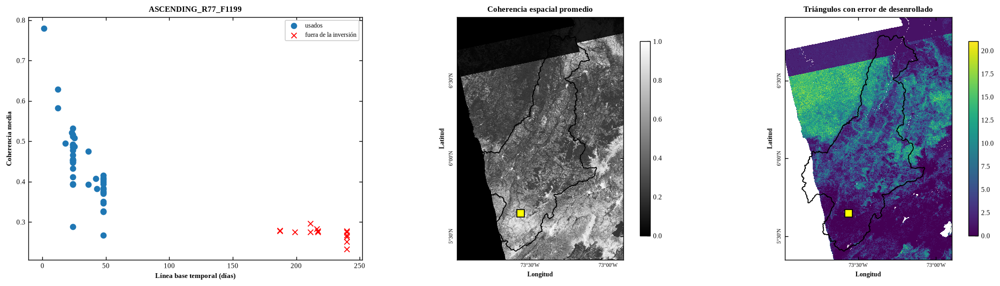

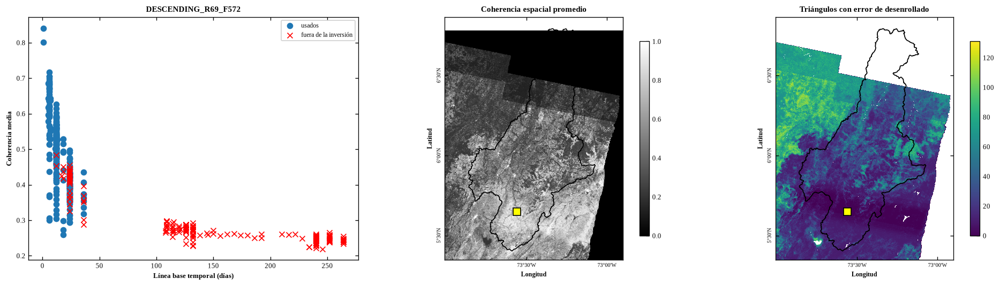

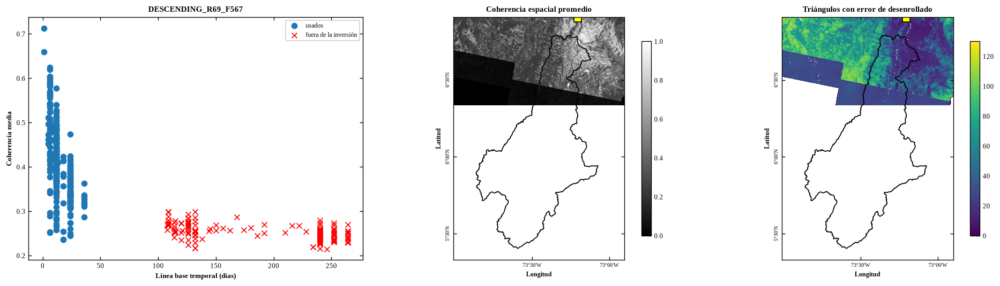

Stack,Pares cargados,En la inversión,Fuera de la inversión,"Referencia (lat, lon)"
ASCENDING_R77_F1199,59,45,14,"5.6472, -73.5582"
DESCENDING_R69_F572,536,341,195,"5.6472, -73.5582"
DESCENDING_R69_F567,493,341,152,"6.8997, -73.1972"


In [19]:
PANELES = {
    "avgSpatialCoh.h5": ("Coherencia espacial promedio", "gray", 1),
    "numTriNonzeroIntAmbiguity.h5": ("Triángulos con error de desenrollado", "viridis", None),
}


# Límite simétrico de la escala de colores: percentil p (98 por defecto) del valor absoluto
def lim_simetrico(arr, p=98):
    v = np.nanpercentile(np.abs(arr), p)
    return float(v) if np.isfinite(v) and v > 0 else 1.0


# Porcentaje de los píxeles del área de estudio que cumplen una máscara
def pct_del_area(mascara, dentro):
    return round(100 * (mascara & dentro).sum() / dentro.sum(), 1) if dentro.any() else np.nan


# Lee un conjunto de datos de un archivo HDF5 de MintPy y sus atributos
def leer_h5(archivo, dataset=None, indice=None):
    with h5py.File(archivo, "r") as f:
        dataset = dataset or list(f.keys())[0]
        d = f[dataset]
        datos = d[indice] if indice is not None else d[()]
        attrs = {k: (v.decode() if isinstance(v, bytes) else str(v)) for k, v in f.attrs.items()}
    return datos, attrs


# Convierte las fechas guardadas en HDF5 a texto
def fechas_h5(arreglo):
    return [str(x.decode() if isinstance(x, bytes) else x) for x in arreglo]


# Transformación geográfica y código EPSG a partir de los atributos de MintPy
def georef(attrs):
    transform = from_origin(
        float(attrs["X_FIRST"]), float(attrs["Y_FIRST"]), float(attrs["X_STEP"]), -float(attrs["Y_STEP"])
    )
    if attrs.get("EPSG") not in (None, "None", ""):
        return transform, int(attrs["EPSG"])
    if "UTM_ZONE" in attrs:
        zona = attrs["UTM_ZONE"]
        base = 32600 if zona[-1].upper() == "N" else 32700
        return transform, base + int(re.sub(r"\D", "", zona))
    return transform, 4326


# Extensión de un mapa para graficarlo en coordenadas: izquierda, derecha, abajo, arriba
def extent(attrs):
    t, _ = georef(attrs)
    filas, columnas = int(attrs["LENGTH"]), int(attrs["WIDTH"])
    return [t.c, t.c + columnas * t.a, t.f + filas * t.e, t.f]


# Punto de referencia: x, y en el sistema del producto y latitud, longitud; None si no existe
def punto_referencia(attrs, epsg):
    if not attrs or "REF_LAT" not in attrs:
        return None
    a, b = float(attrs["REF_LON"]), float(attrs["REF_LAT"])
    if abs(a) <= 180 and abs(b) <= 90:
        lon, lat = a, b
        x, y = lon, lat
        if epsg != 4326:
            x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    else:
        x, y = a, b
        lon, lat = Transformer.from_crs(epsg, 4326, always_xy=True).transform(x, y)
    return x, y, lat, lon


# Dibuja sobre un mapa el área de estudio y el punto de referencia
def dibujar_contexto(ax, epsg, attrs=None):
    gdf_area.to_crs(epsg).boundary.plot(ax=ax, color="k", lw=1)
    referencia = punto_referencia(attrs, epsg)
    if referencia is not None:
        ax.plot(referencia[0], referencia[1], "ks", ms=8, mfc="yellow")
    coordenadas_geograficas(ax, epsg, 0.5, 0.5)
    ax.set_xlabel("Longitud", fontsize=7)
    ax.set_ylabel("Latitud", fontsize=7)
    ax.tick_params(labelsize=6)


# Grafica la calidad de un stack antes de la inversión y devuelve su fila del resumen
def revisar_stack(job_name):
    carpeta = MINTPY_ROOT / job_name
    archivo_stack = carpeta / "inputs" / "ifgramStack.h5"
    nombre = job_name.replace(f"{RUN_ID}_", "")
    if not archivo_stack.exists():
        return {"Stack": nombre, "Pares cargados": 0, "En la inversión": 0, "Fuera de la inversión": 0}

    with h5py.File(archivo_stack, "r") as f:
        pares = [fechas_h5(par) for par in f["date"][()]]
        usados = f["dropIfgram"][()].astype(bool)
        coherencia = np.empty(len(pares))
        for i in range(len(pares)):
            capa = f["coherence"][i]
            coherencia[i] = np.nanmean(np.where(capa > 0, capa, np.nan))
    dias = np.array([(pd.Timestamp(b) - pd.Timestamp(a)).days for a, b in pares])
    attrs_stack = leer_h5(archivo_stack, "dropIfgram")[1]

    mapas = [p for p in PANELES if (carpeta / p).exists()]
    fig, axes = plt.subplots(1, 1 + len(mapas), figsize=(6 + 5 * len(mapas), 4.5))
    axes = np.atleast_1d(axes)
    axes[0].scatter(dias[usados], coherencia[usados], c="C0", label="usados")
    axes[0].scatter(dias[~usados], coherencia[~usados], c="r", marker="x", label="fuera de la inversión")
    axes[0].set(xlabel="Línea base temporal (días)", ylabel="Coherencia media", title=nombre)
    axes[0].legend()
    for ax, archivo in zip(axes[1:], mapas):
        titulo, colores, vmax = PANELES[archivo]
        datos, attrs = leer_h5(carpeta / archivo)
        imagen = ax.imshow(
            datos, extent=extent(attrs), cmap=colores, vmin=0, vmax=vmax, interpolation="nearest"
        )
        dibujar_contexto(ax, georef(attrs)[1], attrs_stack)
        ax.set_title(titulo)
        fig.colorbar(imagen, ax=ax, shrink=0.8)
    fig.tight_layout()
    plt.show()

    referencia = punto_referencia(attrs_stack, georef(attrs_stack)[1])
    return {
        "Stack": nombre,
        "Pares cargados": len(usados),
        "En la inversión": int(usados.sum()),
        "Fuera de la inversión": int((~usados).sum()),
        "Referencia (lat, lon)": f"{referencia[2]:.4f}, {referencia[3]:.4f}" if referencia else "-",
    }


resumen_red = pd.DataFrame([revisar_stack(job_name) for job_name in JOBS])
tabla_apa(resumen_red, "Pares cargados en MintPy y punto de referencia")
sin_carga = resumen_red.loc[resumen_red["Pares cargados"] == 0, "Stack"]
if not sin_carga.empty:
    print("sin bloque A:", ", ".join(sin_carga))

## 18. Sesgo de cierre de fase

**Qué es.** En un interferograma multilook, la fase de cada píxel promedia muchos dispersores. Los cambios de humedad del suelo y de vegetación agregan una fase que no es consistente en el tiempo: la suma de las fases de una secuencia de pares no coincide con la del par que une sus extremos (De Zan et al., 2015). La diferencia es la fase de cierre,

$$\Phi^{n}_{i} = \phi_{i,i+1} + \phi_{i+1,i+2} + \dots + \phi_{i+n-1,i+n} - \phi_{i,i+n}.$$

Este aporte es mayor en los pares cortos y produce un sesgo en la velocidad (Ansari et al., 2021), mayor en cultivos y bosques que en zonas urbanas (Maghsoudi et al., 2022), del orden de centímetros por año (Zheng et al., 2022).

**Método.** `closure_phase_bias.py` de MintPy supone que los pares de conexión `NL` no tienen sesgo y, con las fases de cierre de las conexiones 2 a `BW` y `NL`, estima la serie del sesgo de la serie invertida con la red de ancho de banda `BW` (Zheng et al., 2022). La serie se resta en la sección 19, como en el tutorial de MintPy (Zheng, 2022). Requiere la red completa (sección 13), un punto de referencia estable y SNAPHU (sección 12).

| Acción | Archivos | Uso |
|---|---|---|
| `mask` | `avgCpxClosurePhase.h5`, `maskClosurePhase.h5` | Promedio complejo τ de las fases de cierre de conexión `NL`; un píxel es susceptible si la amplitud de τ supera `EPSILON` y su fase supera `NUM_SIGMA` desviaciones |
| `quick_estimate` | `wratio.h5`, `timeseriesBiasApprox.h5` | Estimación aproximada; `wratio-n` indica cuánto sesgo de la conexión 1 queda en la conexión n |
| `estimate` | `timeseriesBias.h5` | Estimación completa, la que se resta |

| Parámetro | Valor | Qué define |
|---|---|---|
| `METODO_SESGO` | `estimate` | Estimación que se resta |
| `NUM_SIGMA`, `EPSILON` | 3; 0.3 | Umbrales de la máscara (valores por defecto de MintPy) |
| `NUCLEOS` | núcleos del equipo menos uno | Procesos en paralelo |

La figura muestra la amplitud y la fase de τ, los píxeles susceptibles y la velocidad del sesgo, que es el mismo modelo temporal de la velocidad ajustado a la serie del sesgo. La tabla resume el porcentaje susceptible, la velocidad del sesgo y `wratio`.

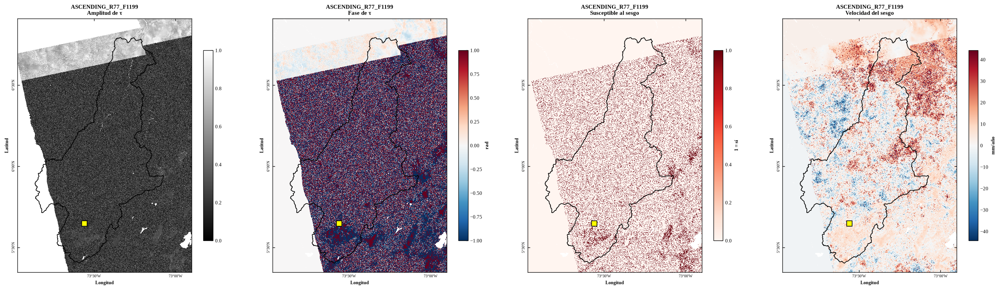

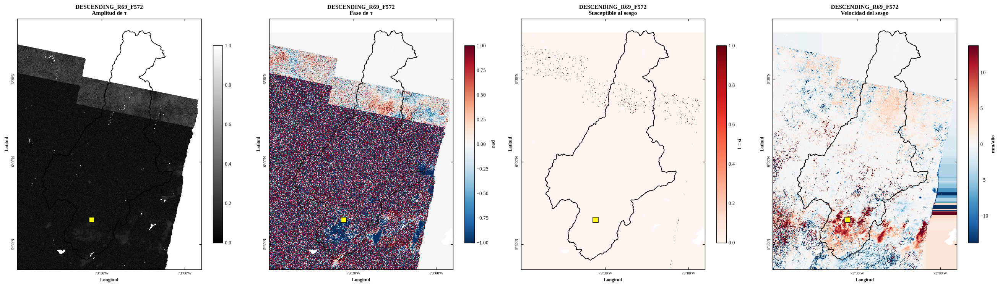

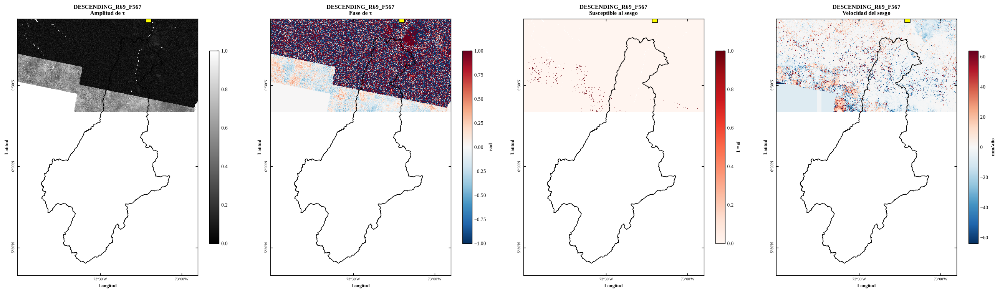

Stack,Conexión NL,Estado,Susceptible al sesgo (%),"Velocidad del sesgo, mediana (mm/año)",P2 (mm/año),P98 (mm/año),wratio-2 mediana
ASCENDING_R77_F1199,10,listo,"15,5","1,2","-23,8","37,9","0,92"
DESCENDING_R69_F572,20,listo,"0,2","-0,0","-6,0","10,3","0,56"
DESCENDING_R69_F567,20,listo,"0,1","-0,7","-44,5","32,5","0,04"


In [20]:
import hashlib

SESGO_DIR = "sesgo_cierre"
METODO_SESGO = "estimate"  # "estimate" (Zheng et al., 2022) o "quick_estimate" (aproximación)
NUM_SIGMA = 3
TAMANO_MIN_BYTES = 1_000_000  # un archivo más pequeño se considera vacío
EPSILON = 0.3
NUCLEOS = max(1, (os.cpu_count() or 2) - 1)
ARCHIVOS_SESGO = {"estimate": "timeseriesBias.h5", "quick_estimate": "timeseriesBiasApprox.h5"}


# Firma de la red cargada: pares, pares usados, punto de referencia, BW y NL
def firma_red(job_name):
    nombre = job_name.replace(f"{RUN_ID}_", "")
    with h5py.File(MINTPY_ROOT / job_name / "inputs" / "ifgramStack.h5", "r") as f:
        contenido = f["date"][()].tobytes() + f["dropIfgram"][()].tobytes()
        referencia = f"{f.attrs.get('REF_Y')}_{f.attrs.get('REF_X')}"
    return f"{hashlib.md5(contenido).hexdigest()} ref={referencia} BW={BW} NL={nl_stack(nombre)}"


# Serie temporal del sesgo de un stack según el método
def archivo_sesgo(job_name, metodo=None):
    return MINTPY_ROOT / job_name / SESGO_DIR / ARCHIVOS_SESGO[metodo or METODO_SESGO]


# Ejecuta closure_phase_bias.py en un stack: máscara, estimación rápida y estimación completa
def estimar_sesgo(job_name):
    carpeta = MINTPY_ROOT / job_name
    salida = carpeta / SESGO_DIR
    nombre = job_name.replace(f"{RUN_ID}_", "")
    firma = firma_red(job_name)
    marca = salida / "firma_red.txt"
    if salida.exists() and (not marca.exists() or marca.read_text() != firma):
        shutil.rmtree(salida)
    salida.mkdir(exist_ok=True)
    marca.write_text(firma)

    comunes = ["-i", carpeta / "inputs" / "ifgramStack.h5", "--nl", nl_stack(nombre), "--bw", BW,
               "-o", salida, "--ram", MEMORIA_GB]
    acciones = [
        ("mask", "maskClosurePhase.h5", ["--num-sigma", NUM_SIGMA, "--eps", EPSILON]),
        ("quick_estimate", "timeseriesBiasApprox.h5", ["--num-worker", NUCLEOS]),
    ]
    if METODO_SESGO == "estimate":
        acciones.append(("estimate", "timeseriesBias.h5", ["--num-worker", NUCLEOS, "-c", "local"]))
    for accion, archivo, extra in acciones:
        if (salida / archivo).exists() and (salida / archivo).stat().st_size > TAMANO_MIN_BYTES:
            continue
        (salida / archivo).unlink(missing_ok=True)
        codigo = ejecutar_mintpy("closure_phase_bias", comunes + ["-a", accion] + extra,
                                 cwd=carpeta, log_nombre="log_sesgo.txt", check=False)
        if codigo != 0 or not (salida / archivo).exists() or (salida / archivo).stat().st_size <= TAMANO_MIN_BYTES:
            return f"falló {accion}"
    return "listo"


# Velocidad del sesgo con el mismo modelo temporal y las mismas fechas excluidas que la velocidad de MintPy
def velocidad_del_sesgo(job_name):
    carpeta = MINTPY_ROOT / job_name
    sesgo = archivo_sesgo(job_name)
    if not sesgo.exists():
        return None
    salida = carpeta / SESGO_DIR / "velocidad_sesgo.h5"
    excluidas = carpeta / "exclude_date.txt"
    fuentes = [sesgo, carpeta / "config.txt"] + ([excluidas] if excluidas.exists() else [])
    if not salida.exists() or salida.stat().st_mtime < max(p.stat().st_mtime for p in fuentes):
        argumentos = [sesgo, "-t", carpeta / "config.txt", "-o", salida]
        if excluidas.exists():
            argumentos += ["--ex", excluidas]
        ejecutar_mintpy("timeseries2velocity", argumentos, cwd=carpeta, log_nombre="log_sesgo.txt")
    return salida


# Mapas del diagnóstico del sesgo de un stack: amplitud y fase de tau, máscara y velocidad del sesgo
def figura_sesgo(job_name):
    carpeta = MINTPY_ROOT / job_name / SESGO_DIR
    nombre = job_name.replace(f"{RUN_ID}_", "")
    amplitud, attrs = leer_h5(carpeta / "avgCpxClosurePhase.h5", "amplitude")
    fase = leer_h5(carpeta / "avgCpxClosurePhase.h5", "phase")[0]
    mascara = leer_h5(carpeta / "maskClosurePhase.h5")[0].astype(bool)
    try:
        archivo_vel = velocidad_del_sesgo(job_name)
    except RuntimeError:
        archivo_vel = None
    vel_sesgo = leer_h5(archivo_vel, "velocity")[0] * 1000 if archivo_vel else np.full(amplitud.shape, np.nan)
    with h5py.File(MINTPY_ROOT / job_name / "inputs" / "geometryGeo.h5", "r") as f:
        tierra = f["waterMask"][()].astype(bool) if "waterMask" in f else np.ones(amplitud.shape, bool)
    valido = tierra & (amplitud > 0)
    transform, epsg = georef(attrs)
    dentro = ~geometry_mask(gdf_area.to_crs(epsg).geometry, out_shape=amplitud.shape, transform=transform)

    paneles = [
        (np.where(valido, amplitud, np.nan), "Amplitud de τ", dict(cmap="gray", vmin=0, vmax=1), ""),
        (np.where(valido, fase, np.nan), "Fase de τ", dict(cmap="RdBu_r", vmin=-1, vmax=1), "rad"),
        (np.where(valido, (~mascara).astype(float), np.nan), "Susceptible al sesgo",
         dict(cmap="Reds", vmin=0, vmax=1), "1 = sí"),
        (np.where(valido, vel_sesgo, np.nan), "Velocidad del sesgo",
         dict(cmap="RdBu_r", vmin=-lim_simetrico(vel_sesgo[valido & dentro]),
              vmax=lim_simetrico(vel_sesgo[valido & dentro])), "mm/año"),
    ]
    fig, axes = plt.subplots(1, 4, figsize=(22, 6))
    for ax, (datos, titulo, opciones, etiqueta) in zip(axes, paneles):
        imagen = ax.imshow(datos, extent=extent(attrs), interpolation="nearest", **opciones)
        dibujar_contexto(ax, epsg, attrs)
        ax.set_title(f"{nombre}\n{titulo}")
        fig.colorbar(imagen, ax=ax, shrink=0.75, label=etiqueta)
    fig.tight_layout()
    plt.show()

    fila = {"Susceptible al sesgo (%)": pct_del_area(~mascara & valido, dentro & valido)}
    if np.isfinite(vel_sesgo[valido & dentro]).any():
        p2, mediana, p98 = np.nanpercentile(vel_sesgo[valido & dentro], [2, 50, 98])
        fila.update({"Velocidad del sesgo, mediana (mm/año)": round(mediana, 1),
                     "P2 (mm/año)": round(p2, 1), "P98 (mm/año)": round(p98, 1)})
    if (carpeta / "wratio.h5").exists():
        with h5py.File(carpeta / "wratio.h5", "r") as f:
            for n in range(1, f["wratio"].shape[0]):
                capa = f["wratio"][n][valido & dentro]
                fila[f"wratio-{n + 1} mediana"] = round(float(np.nanmedian(capa)), 2)
    return fila


filas = []
for job_name in barra(JOBS, "Sesgo de cierre"):
    nombre = job_name.replace(f"{RUN_ID}_", "")
    if estado_mintpy.get(job_name) == "A_error":
        estado = "sin bloque A"
    elif not red_completa.get(job_name, False):
        estado = "red incompleta"
    else:
        estado = estimar_sesgo(job_name)
    filas.append({"Stack": nombre, "Conexión NL": nl_stack(nombre), "Estado": estado})

for fila in filas:
    job_name = f"{RUN_ID}_{fila['Stack']}"
    if fila["Estado"] == "listo":
        fila.update(figura_sesgo(job_name))
tabla_apa(pd.DataFrame(filas), "Sesgo de cierre de fase por stack")
for fila in filas:
    if fila["Estado"].startswith("falló"):
        print(f"{fila['Stack']}: {fila['Estado']} (ver log_sesgo.txt)")

## 19. MintPy, segunda parte

Cada stack se procesa en tres partes:

1. `smallbaselineApp.py --start correct_unwrap_error --end invert_network`: serie temporal (`timeseries.h5`) y coherencia temporal, que mide la consistencia de cada píxel con la red (Pepe y Lanari, 2006).
2. Resta del sesgo de cierre: la serie invertida se guarda en `serie_original/timeseries.h5` y se reemplaza por la serie menos el sesgo (`diff.py`). La marca `SESGO_CIERRE` en los atributos evita restarlo dos veces.
3. `smallbaselineApp.py --start correct_LOD`: mareas terrestres (`_SET`), troposfera (`_ERA5`), rampa (`_ramp`), error de elevación (`_demErr`), fechas ruidosas, fecha de referencia y velocidad (`velocity.h5`).

El sesgo se resta antes de las demás correcciones porque corresponde a la serie que sale de la inversión (Zheng et al., 2022). Un stack ya procesado cuya red y corrección no cambiaron se repite desde `PASO_REPETICION`, lo que permite cambiar la rampa o el modelo temporal en minutos.

| Parámetro | Valor | Qué define |
|---|---|---|
| `PASO_COMPLETO`, `PASO_DESPUES_SESGO` | `correct_unwrap_error`; `correct_LOD` | Inicio de las partes 1 y 3 |
| `PASO_REPETICION` | `deramp` | Paso desde el que se repite un stack ya procesado |
| `CORREGIR_SESGO` | `True` | Con `False` se restaura la serie original, para comparar |

In [21]:
PASO_COMPLETO = "correct_unwrap_error"
PASO_DESPUES_SESGO = "correct_LOD"
PASO_REPETICION = "deramp"  # paso desde el que se repite un stack que ya tiene velocidad
CORREGIR_SESGO = True
ESTADOS = {
    "A_ok": "falta el bloque B",
    "A_error": "falló el bloque A",
    "B_ok": "completo",
    "B_error": "con error",
}


# Paso inicial del bloque B: completo en un stack nuevo o si la red cambió después de la última inversión
def paso_inicial(job_name):
    d = MINTPY_ROOT / job_name
    red, serie = d / "inputs" / "ifgramStack.h5", d / "timeseries.h5"
    al_dia = red.exists() and serie.exists() and serie.stat().st_mtime >= red.stat().st_mtime
    return PASO_REPETICION if al_dia and (d / "velocity.h5").exists() else PASO_COMPLETO


# Marca de corrección del sesgo guardada en los atributos de timeseries.h5; vacía si no está corregida
def marca_sesgo(serie):
    with h5py.File(serie, "r") as f:
        marca = f.attrs.get("SESGO_CIERRE", "")
    return marca.decode() if isinstance(marca, bytes) else str(marca)


# Resta el sesgo de cierre de la serie invertida, o restaura la original; devuelve el estado y si la serie cambió
def aplicar_sesgo(job_name):
    d = MINTPY_ROOT / job_name
    serie, original = d / "timeseries.h5", d / "serie_original" / "timeseries.h5"
    if not serie.exists():
        return "sin serie invertida", False
    marca = marca_sesgo(serie)
    if not CORREGIR_SESGO:
        if marca and original.exists():
            shutil.move(original, serie)
            return "original restaurada", True
        return "sin corrección", False

    sesgo = archivo_sesgo(job_name)
    if not sesgo.exists():
        return "sin sesgo estimado", False
    firma = f"{sesgo.name} {sesgo.stat().st_mtime:.0f}"
    if marca == firma:
        return "corregida", False
    if not marca:
        original.parent.mkdir(exist_ok=True)
        shutil.move(serie, original)
    elif original.exists():
        serie.unlink()
    else:
        return "sin serie original", False

    codigo = ejecutar_mintpy("diff", [original, sesgo, "-o", serie], cwd=d, check=False)
    if codigo != 0:
        shutil.copy(original, serie)
        return "falló la resta", True
    nombre = job_name.replace(f"{RUN_ID}_", "")
    with h5py.File(serie, "a") as f:
        f.attrs["SESGO_CIERRE"] = firma
        f.attrs["SESGO_BW"] = str(BW)
        f.attrs["SESGO_NL"] = str(nl_stack(nombre))
    return "corregida", True


pendientes_b = [j for j in JOBS if estado_mintpy.get(j) != "A_error"]
recorrido, estado_sesgo = {}, {}
for job_name in barra(pendientes_b, "MintPy, bloque B"):
    carpeta = MINTPY_ROOT / job_name
    completo = paso_inicial(job_name) == PASO_COMPLETO
    codigo, pasos_hechos = 0, []
    if completo:
        pasos = ["config.txt", "--start", PASO_COMPLETO, "--end", "invert_network"]
        codigo = ejecutar_mintpy("smallbaselineApp", pasos, cwd=carpeta, check=False)
        pasos_hechos.append(f"{PASO_COMPLETO} a invert_network")
    if codigo == 0:
        estado_sesgo[job_name], cambio = aplicar_sesgo(job_name)
        inicio = PASO_DESPUES_SESGO if completo or cambio else PASO_REPETICION
        pasos_hechos.append(f"{inicio} al final")
        codigo = ejecutar_mintpy("smallbaselineApp", ["config.txt", "--start", inicio], cwd=carpeta, check=False)
    recorrido[job_name] = "; ".join(pasos_hechos)
    estado_mintpy[job_name] = "B_ok" if codigo == 0 else "B_error"


# Resultados

**Convención de signos.** Como en MintPy, los valores positivos indican que el terreno se acerca al satélite y los negativos que se aleja, en la línea de vista (LOS). Un alejamiento puede corresponder a hundimiento o a movimiento ladera abajo (Yunjun et al., 2019).

**Referencia.** Las velocidades están en mm/año y corregidas del sesgo de cierre. En los mapas y en las series se refieren a la estación OAMU o, si el stack no la cubre, en los mapas a la mediana del área de estudio (sección 21).

**Áreas sin dato.** Corresponden a píxeles de baja coherencia (vegetación densa y cambios de cobertura), distorsiones por relieve, errores de desenrollado y cuerpos de agua, o a sectores que el stack no cubre.

**Figuras del documento.** Las figuras que van en el documento se generan en la sección donde se calculan, con el diseño común (Times New Roman, sin título dentro, coordenadas, norte, escala y barras de colores). El número y el título van encima de cada una.

In [22]:
# Velocidad, incertidumbre, extensión y EPSG de una geometría: su mosaico o su único stack (sección 22)
def capas_geometria(geometria):
    if geometria in mosaicos:
        m = mosaicos[geometria]
        vel, std, tr, epsg = m["velocidad"], m["desviacion"], m["transform"], m["epsg"]
    else:
        vel, std, attrs = velocidad_confiable(grupos[geometria][0])
        tr, epsg = georef(attrs)
    filas, columnas = vel.shape
    return vel, std, [tr.c, tr.c + columnas * tr.a, tr.f + filas * tr.e, tr.f], epsg


## 20. Máscara de confiabilidad

`serie_final` toma la serie con todas las correcciones (la de sufijos más largos); todas parten de `timeseries.h5`, que ya tiene restado el sesgo. Un píxel es confiable si cumple los cuatro criterios:

| Criterio | Umbral | Justificación |
|---|---|---|
| Coherencia temporal | ≥ 0.7 (`maskTempCoh.h5`) | Consistencia de la serie con los interferogramas (Pepe y Lanari, 2006) |
| Coherencia espacial promedio | ≥ `COH_ESPACIAL_MIN` (0.3) | Calidad de fase en la mayoría de los pares |
| Triángulos con error de desenrollado | ≤ `T_INT_PCT_DEFECTO` (20 %) de los triángulos de la red | Reemplaza la corrección automática, que no aplica a HyP3 (Yunjun et al., 2019) |
| Máscara de agua | tierra firme | La fase del agua no es deformación |

El criterio de triángulos se expresa en porcentaje porque los productos de HyP3 se desenrollan por separado, y solo se aplica si la red tiene al menos `T_INT_MIN_TRIANGULOS` (20) triángulos. La primera tabla da el porcentaje del área que cumple cada criterio; la segunda, la cobertura que resultaría con otros umbrales de triángulos (`PRUEBA_T_INT`).

In [23]:
COH_ESPACIAL_MIN = 0.3
T_INT_MIN_TRIANGULOS = 20
T_INT_PCT_MAX = {}
T_INT_PCT_DEFECTO = 20
PRUEBA_T_INT = [0, 5, 10, 20, 30, 50]


# Serie temporal con la cadena de correcciones más larga, sin los archivos de residuos
def serie_final(mintpy_dir):
    candidatos = [p for p in Path(mintpy_dir).glob("timeseries*.h5") if "Residual" not in p.name]
    if not candidatos:
        raise FileNotFoundError(f"sin timeseries en {mintpy_dir}")
    return max(candidatos, key=lambda p: len(p.stem))


# Número de triángulos de la red de interferogramas usados
def n_triangulos_red(mintpy_dir):
    with h5py.File(Path(mintpy_dir) / "inputs" / "ifgramStack.h5", "r") as f:
        pares = [fechas_h5(p) for p in f["date"][()]]
        usados = f["dropIfgram"][()]
    return contar_triangulos(tuple(p) for p, u in zip(pares, usados) if u)


# Porcentaje de triángulos con error de desenrollado por píxel; None si la red tiene pocos triángulos
def pct_triangulos_error(mintpy_dir):
    archivo = Path(mintpy_dir) / "numTriNonzeroIntAmbiguity.h5"
    if not archivo.exists():
        return None
    n_triangulos = n_triangulos_red(mintpy_dir)
    if n_triangulos < T_INT_MIN_TRIANGULOS:
        return None
    return 100 * leer_h5(archivo)[0].astype(float) / n_triangulos


# Umbral de triángulos con error del stack, en porcentaje; None si el criterio no se aplica
def umbral_t_int(mintpy_dir):
    nombre = Path(mintpy_dir).name.replace(f"{RUN_ID}_", "")
    return T_INT_PCT_MAX.get(nombre, T_INT_PCT_DEFECTO)


# Criterios de confiabilidad de un stack, cada uno como máscara booleana
def criterios_confiabilidad(mintpy_dir, t_int_pct="stack"):
    d = Path(mintpy_dir)
    umbral = umbral_t_int(d) if t_int_pct == "stack" else t_int_pct
    criterios = {"Coherencia temporal": leer_h5(d / "maskTempCoh.h5")[0].astype(bool)}
    if (d / "avgSpatialCoh.h5").exists():
        criterios["Coherencia espacial"] = leer_h5(d / "avgSpatialCoh.h5")[0] >= COH_ESPACIAL_MIN
    pct = pct_triangulos_error(d)
    if umbral is not None and pct is not None:
        criterios["Triángulos"] = pct <= umbral
    with h5py.File(d / "inputs" / "geometryGeo.h5", "r") as f:
        if "waterMask" in f:
            criterios["Tierra firme"] = f["waterMask"][()].astype(bool)
    return criterios


# Máscara de píxeles confiables: los que cumplen todos los criterios
def mascara_confiable(mintpy_dir, t_int_pct="stack"):
    return np.logical_and.reduce(list(criterios_confiabilidad(mintpy_dir, t_int_pct).values()))


resumen, sensibilidad, sin_velocidad, series_usadas = [], [], [], set()
for job_name in JOBS:
    d = MINTPY_ROOT / job_name
    nombre = job_name.replace(f"{RUN_ID}_", "")
    if not (d / "velocity.h5").exists():
        sin_velocidad.append(nombre)
        continue

    velocidad, attrs = leer_h5(d / "velocity.h5", "velocity")
    transform, epsg = georef(attrs)
    dentro = ~geometry_mask(gdf_area.to_crs(epsg).geometry, out_shape=velocidad.shape, transform=transform)
    criterios = criterios_confiabilidad(d)
    confiable = np.logical_and.reduce(list(criterios.values()))

    series_usadas.add(serie_final(d).name)
    fila = {"Stack": nombre, "Triángulos de la red": n_triangulos_red(d)}
    fila.update({f"{nombre_criterio} (%)": pct_del_area(m, dentro) for nombre_criterio, m in criterios.items()})
    fila["Confiables (%)"] = pct_del_area(confiable, dentro)
    resumen.append(fila)

    # Cobertura que resultaría con otros umbrales de triángulos con error
    pct = pct_triangulos_error(d)
    if pct is None:
        continue
    otros = np.logical_and.reduce([m for k, m in criterios.items() if k != "Triángulos"])
    en_area = pct[dentro & criterios["Coherencia temporal"] & np.isfinite(pct)]
    fila = {"Stack": nombre}
    if en_area.size:
        p25, mediana, p75 = np.percentile(en_area, [25, 50, 75])
        fila.update({"P25 (%)": round(p25, 1), "Mediana (%)": round(mediana, 1), "P75 (%)": round(p75, 1)})
    for umbral in PRUEBA_T_INT:
        fila[f"≤ {umbral} %"] = pct_del_area(otros & (pct <= umbral), dentro)
    fila["Sin criterio"] = pct_del_area(otros, dentro)
    sensibilidad.append(fila)

tabla_apa(pd.DataFrame(resumen), "Píxeles del área de estudio que cumplen cada criterio de confiabilidad")
tabla_apa(pd.DataFrame(sensibilidad), "Cobertura confiable según el umbral de triángulos con error")
if sin_velocidad:
    print("sin velocity.h5:", ", ".join(sin_velocidad))

Stack,Triángulos de la red,Coherencia temporal (%),Coherencia espacial (%),Triángulos (%),Tierra firme (%),Confiables (%)
ASCENDING_R77_F1199,22,"40,9","69,0","57,0","99,8","39,2"
DESCENDING_R69_F572,170,"45,0","70,6","62,5","99,8","45,0"
DESCENDING_R69_F567,170,"23,7","54,6","63,9","99,6","23,6"


Stack,P25 (%),Mediana (%),P75 (%),≤ 0 %,≤ 5 %,≤ 10 %,≤ 20 %,≤ 30 %,≤ 50 %,Sin criterio
ASCENDING_R77_F1199,"0,0","4,5","9,1","13,8","25,5","32,9","39,2","40,2","40,3","40,3"
DESCENDING_R69_F572,"4,7","7,1","9,4","2,2","12,7","36,1","45,0","45,0","45,0","45,0"
DESCENDING_R69_F567,"8,2","9,4","11,2","0,0","0,0","15,0","23,6","23,7","23,7","23,7"


## 21. Mapas de velocidad

Para cada stack se grafican la velocidad LOS, pendiente de la tendencia lineal de cada píxel, y su desviación estándar, estimada de los residuos del ajuste (Yunjun et al., 2019). La incertidumbre crece con la distancia al punto de referencia, porque el ruido atmosférico residual está correlacionado en el espacio, y no incluye ese ruido de forma explícita.

**Referencia de la velocidad.** Cada stack se refiere a la mediana de sus píxeles confiables en una ventana de `VENTANA_REF_PX` píxeles de lado alrededor de la estación GNSS `REF_ESTACION` (OAMU, dentro de la cuenca y el mismo punto de referencia espacial de MintPy), de modo que esa ventana queda en cero. Un stack que no cubre la estación, o que tiene menos de `MIN_PX_REF` píxeles confiables en la ventana, se refiere a la mediana de sus píxeles confiables dentro del área. El valor restado queda en `ajuste_referencia`.

| Parámetro | Valor | Qué define |
|---|---|---|
| `PERCENTIL_ESCALA` | 98 | Límite de la escala de colores, para que unos pocos extremos no saturen el mapa |
| `REF_ESTACION` | OAMU | Estación GNSS de referencia (nombre, latitud y longitud) |
| `VENTANA_REF_PX` | 9 | Lado de la ventana de referencia, en píxeles |
| `MIN_PX_REF` | 10 | Mínimo de píxeles confiables en la ventana |


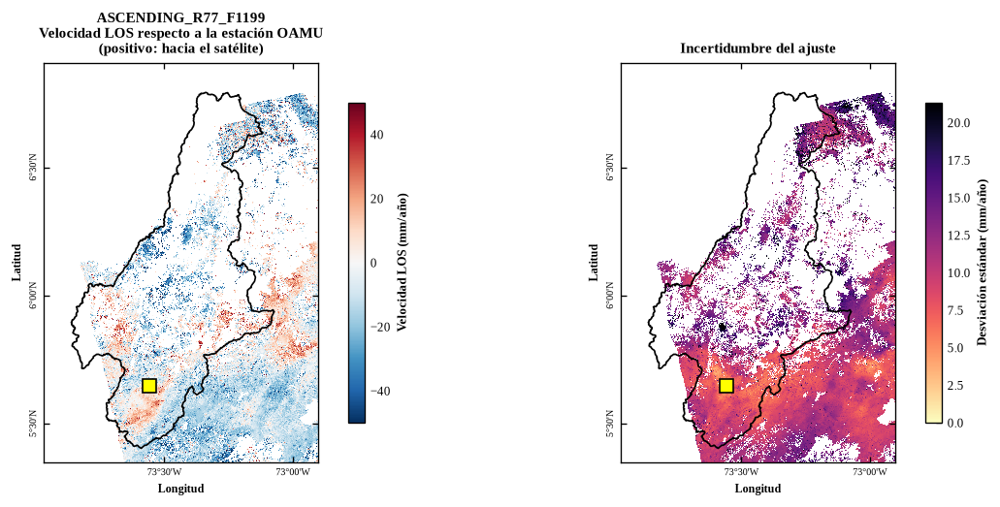

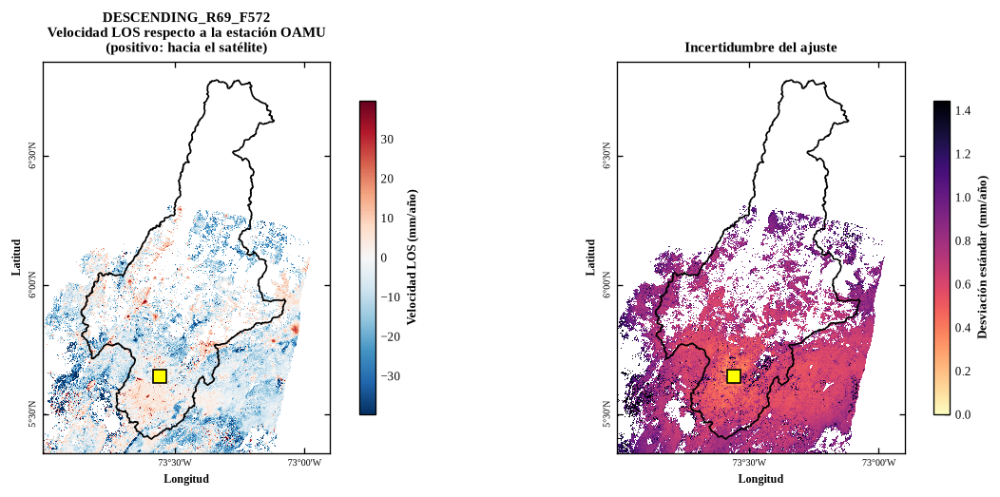

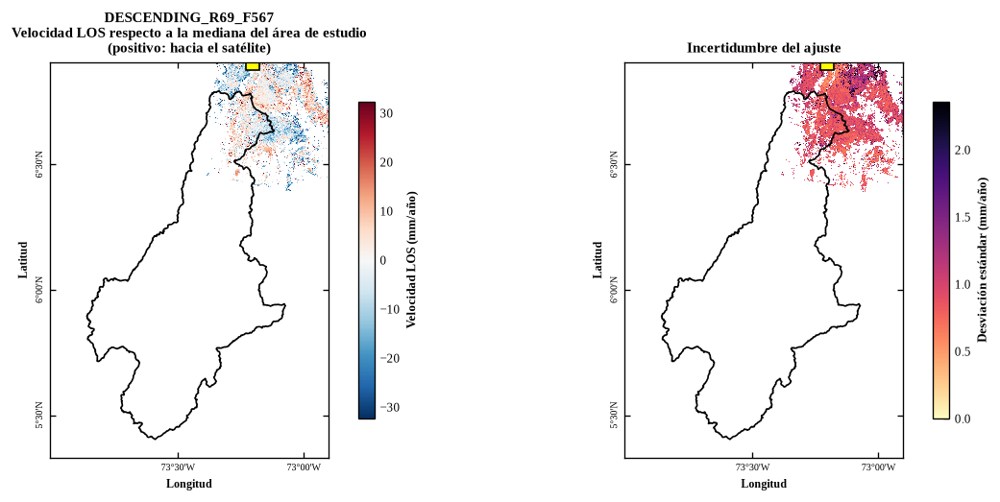

Stack,P2 (mm/año),P98 (mm/año),Incertidumbre mediana (mm/año),Ajuste de referencia (mm/año)
Ascendente R77 F1199,"-46,5","28,7","10,5","-9,3"
Descendente R69 F572,"-37,2","16,5","0,7","-2,7"
Descendente R69 F567,"-27,3","22,4","0,9","-0,7"


In [24]:
PERCENTIL_ESCALA = 98
REF_ESTACION = ("OAMU", 5.647208907, -73.55802943)  # nombre, latitud, longitud
VENTANA_REF_PX = 9  # lado de la ventana de referencia, en píxeles
MIN_PX_REF = 10  # mínimo de píxeles confiables en la ventana

ajuste_referencia, referencia_usada = {}, {}


# Píxeles confiables en una ventana alrededor de la estación de referencia; None si el stack no la cubre
def ventana_estacion(attrs, confiable):
    transform, epsg = georef(attrs)
    x, y = rasterio.warp.transform("EPSG:4326", f"EPSG:{epsg}", [REF_ESTACION[2]], [REF_ESTACION[1]])
    col, fila = ~transform * (x[0], y[0])
    fila, col = int(fila), int(col)
    if not (0 <= fila < confiable.shape[0] and 0 <= col < confiable.shape[1]):
        return None
    mitad = VENTANA_REF_PX // 2
    ventana = np.zeros(confiable.shape, dtype=bool)
    ventana[max(fila - mitad, 0):fila + mitad + 1, max(col - mitad, 0):col + mitad + 1] = True
    ventana &= confiable
    return ventana if ventana.sum() >= MIN_PX_REF else None


# Velocidad e incertidumbre de un stack en mm/año, solo en los píxeles confiables, y sus atributos.
# La velocidad se refiere a la ventana de la estación de referencia o, si el stack no la cubre, a la mediana
# del área; el valor restado queda en ajuste_referencia y la referencia usada en referencia_usada
def velocidad_confiable(job_name):
    d = MINTPY_ROOT / job_name
    velocidad, attrs = leer_h5(d / "velocity.h5", "velocity")
    desviacion, _ = leer_h5(d / "velocity.h5", "velocityStd")
    confiable = mascara_confiable(d)
    referencia = ventana_estacion(attrs, confiable)
    nombre_referencia = f"la estación {REF_ESTACION[0]}"
    if referencia is None:
        transform, epsg = georef(attrs)
        dentro = ~geometry_mask(gdf_area.to_crs(epsg).geometry, out_shape=velocidad.shape, transform=transform)
        referencia = confiable & dentro
        nombre_referencia = "la mediana del área de estudio"
    ajuste = float(np.nanmedian(velocidad[referencia])) * 1000 if referencia.any() else 0.0
    ajuste_referencia[job_name] = ajuste
    referencia_usada[job_name] = nombre_referencia
    velocidad = np.where(confiable, velocidad * 1000 - ajuste, np.nan)
    return velocidad, np.where(confiable, desviacion * 1000, np.nan), attrs


filas = []
for job_name in JOBS:
    if not (MINTPY_ROOT / job_name / "velocity.h5").exists():
        continue
    nombre = job_name.replace(f"{RUN_ID}_", "")
    velocidad, desviacion, attrs = velocidad_confiable(job_name)
    epsg = georef(attrs)[1]
    limite = lim_simetrico(velocidad)
    limite_desviacion = np.nanpercentile(desviacion, PERCENTIL_ESCALA)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_ANCHO * 1.6, 4.4))
    mapa_velocidad = axes[0].imshow(
        velocidad, extent=extent(attrs), cmap="RdBu_r", vmin=-limite, vmax=limite, interpolation="nearest"
    )
    mapa_desviacion = axes[1].imshow(
        desviacion, extent=extent(attrs), cmap="magma_r", vmin=0, vmax=limite_desviacion,
        interpolation="nearest",
    )
    for ax in axes:
        dibujar_contexto(ax, epsg, attrs)
    fig.colorbar(mapa_velocidad, ax=axes[0], shrink=0.8, label="Velocidad LOS (mm/año)")
    fig.colorbar(mapa_desviacion, ax=axes[1], shrink=0.8, label="Desviación estándar (mm/año)")
    axes[0].set_title(f"{nombre}\nVelocidad LOS respecto a {referencia_usada[job_name]}\n(positivo: hacia el satélite)")
    axes[1].set_title("Incertidumbre del ajuste")
    fig.tight_layout()
    plt.show()

    p2, mediana, p98 = np.nanpercentile(velocidad, [2, 50, 98])
    filas.append({
        "Stack": nombre_stack(job_name),
        "P2 (mm/año)": round(p2, 1),
        "P98 (mm/año)": round(p98, 1),
        "Incertidumbre mediana (mm/año)": round(np.nanmedian(desviacion), 1),
        "Ajuste de referencia (mm/año)": round(ajuste_referencia[job_name], 1),
    })

tabla_apa(pd.DataFrame(filas), "Estadísticos de la velocidad en la línea de vista por stack", numero=6)

## 22. Mosaico y velocidad local

**Mosaico.** Los stacks de una misma geometría se llevan a una grilla común y se ajustan a la referencia del de mayor cobertura con la mediana de las diferencias en sus píxeles comunes; los stacks se ajustan en orden de traslape, para que un relleno sirva de puente. Con menos de `N_MIN_TRASLAPE` píxeles comunes, el desfase se estima con medianas de bloques vecinos de `BLOQUE_PX` píxeles. Cada píxel toma el stack de mayor prioridad con dato: principal, complementarios y, solo fuera de la huella de estos, relleno. La dispersión de las diferencias después del ajuste mide la consistencia entre stacks.

**Velocidad local.** La velocidad conserva variaciones de decenas de kilómetros, atmosféricas y de cobertura, que no son movimientos de ladera. Se separa en una componente regional, mediana de bloques de `LADO_REGIONAL_PX` píxeles interpolada a cada píxel, y una local, que es la diferencia (Bekaert et al., 2020). Un movimiento más ancho que el bloque queda atenuado.

**Umbral de estabilidad.** La dispersión de la velocidad local, 1.4826 veces la desviación absoluta mediana (Leys et al., 2013), estima el ruido del mapa; el doble separa los píxeles estables de los que presentan movimiento (Barra et al., 2017).

| Parámetro | Valor | Qué define |
|---|---|---|
| `N_MIN_TRASLAPE` | 200 | Píxeles comunes mínimos para estimar el desfase entre stacks |
| `BLOQUE_PX`, `MIN_PX_BLOQUE` | 25 (2 km); 20 | Bloques del método alterno |
| `LADO_REGIONAL_PX`, `MIN_PX_REGIONAL` | 50 (4 km); 50 | Bloques de la componente regional |
| `SUFIJO_AREA` | `_area` | Sufijo de los GeoTIFF recortados al área |

Resultados en `03_resultados/geotiff/mosaicos/`: velocidad, desviación estándar y velocidad local por geometría, completas y recortadas al área, y las tablas `<RUN_ID>_mosaico_stacks.csv` y `<RUN_ID>_velocidad_local.csv`.

Debajo se generan las Figuras 10, 12 y 13 del documento, con el estilo de la celda "Estilo de las figuras del documento".

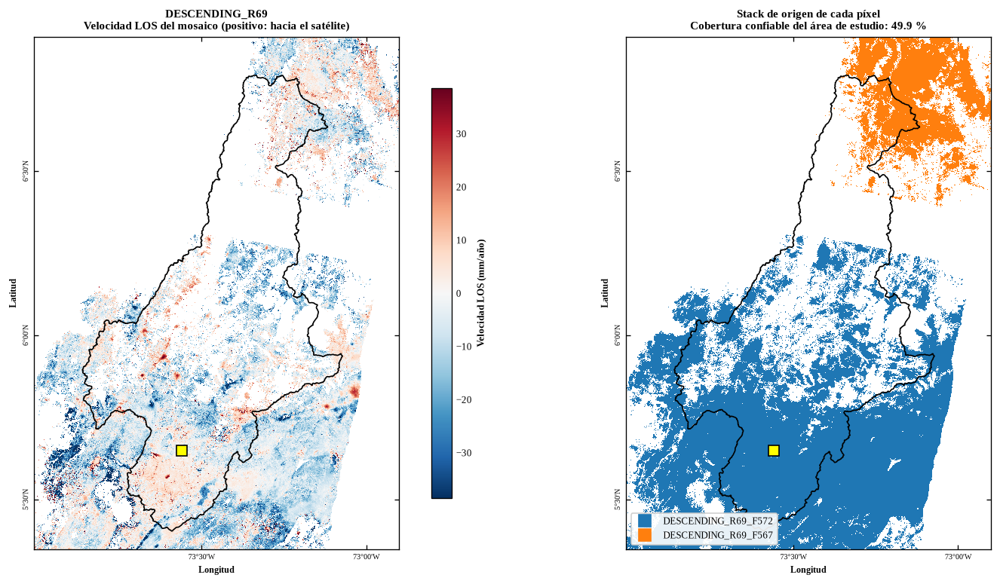

un stack queda con su propia referencia
sin mosaico: ASCENDING_R77


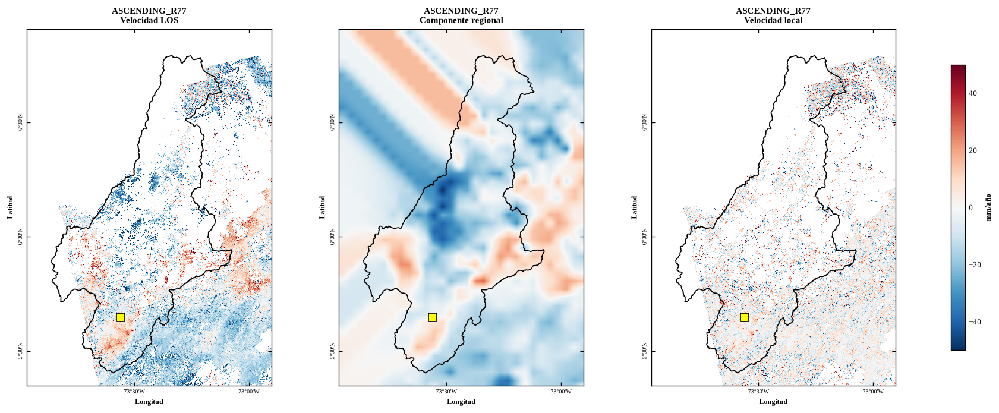

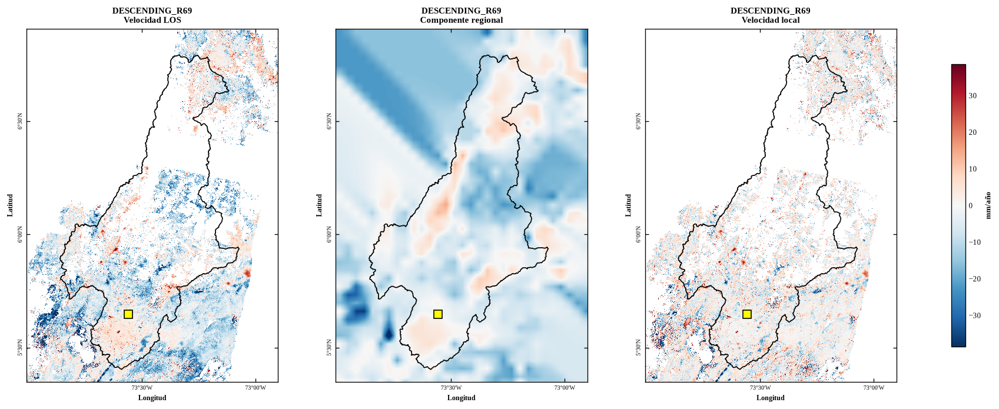

Geometría,Dispersión de la velocidad LOS (mm/año),"Dispersión de la velocidad local, σ (mm/año)",Umbral 2σ (mm/año),Píxeles fuera de ±2σ (%)
Ascendente,"16,9","10,4","20,7","11,6"
Descendente,"9,5","6,9","13,8","10,8"


In [25]:
N_MIN_TRASLAPE = 200
BLOQUE_PX = 25
MIN_PX_BLOQUE = 20
LADO_REGIONAL_PX = 50
MIN_PX_REGIONAL = 50
SUFIJO_AREA = "_area"


# Geometría de adquisición del stack: dirección de vuelo y órbita relativa
def geometria_stack(job_name):
    m = re.search(r"(ASCENDING|DESCENDING)_R(\d+)", job_name)
    return f"{m.group(1)}_R{m.group(2)}" if m else job_name


# Indica si un stack es de relleno
def es_relleno(job_name):
    nombre = job_name.replace(f"{RUN_ID}_", "")
    return any(nombre == f"{stack}_{sat}" for stack, satelites in RELLENOS.items() for sat in satelites)


# Grilla que contiene a todos los stacks de una geometría, alineada con la del primero
def grilla_comun(lista_attrs):
    t0, epsg = georef(lista_attrs[0])
    pixel = t0.a
    limites = []
    for attrs in lista_attrs:
        x0, x1, y0, y1 = extent(attrs)
        epsg_stack = georef(attrs)[1]
        if epsg_stack != epsg:
            x0, y0, x1, y1 = transform_bounds(f"EPSG:{epsg_stack}", f"EPSG:{epsg}", x0, y0, x1, y1)
        limites.append((x0, y0, x1, y1))
    xmin = t0.c + np.floor((min(b[0] for b in limites) - t0.c) / pixel) * pixel
    ymax = t0.f + np.ceil((max(b[3] for b in limites) - t0.f) / pixel) * pixel
    filas = int(np.ceil((ymax - min(b[1] for b in limites)) / pixel))
    columnas = int(np.ceil((max(b[2] for b in limites) - xmin) / pixel))
    return from_origin(xmin, ymax, pixel, pixel), epsg, (filas, columnas)


# Lleva un arreglo de MintPy a otra grilla por vecino más cercano
def a_grilla(arr, attrs, transform, epsg, forma):
    t_origen, epsg_origen = georef(attrs)
    salida = np.full(forma, np.nan, dtype="float32")
    reproject(
        arr.astype("float32"), salida,
        src_transform=t_origen, src_crs=f"EPSG:{epsg_origen}", src_nodata=np.nan,
        dst_transform=transform, dst_crs=f"EPSG:{epsg}", dst_nodata=np.nan,
        resampling=Resampling.nearest,
    )
    return salida


# Mediana de cada bloque de BLOQUE_PX píxeles de lado; NaN si el bloque tiene pocos datos
def mediana_bloques(arr):
    h, w = arr.shape[0] // BLOQUE_PX, arr.shape[1] // BLOQUE_PX
    bloques = arr[:h * BLOQUE_PX, :w * BLOQUE_PX].reshape(h, BLOQUE_PX, w, BLOQUE_PX)
    bloques = bloques.swapaxes(1, 2).reshape(h, w, -1)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        mediana = np.nanmedian(bloques, axis=2)
    mediana[np.isfinite(bloques).sum(axis=2) < MIN_PX_BLOQUE] = np.nan
    return mediana


# Desfase (a - b) entre dos mapas de la misma grilla, número de datos, dispersión y método.
# Con pocos píxeles comunes se comparan las medianas de bloques separados hasta dos bloques
def desfase_entre(a, b):
    comun = np.isfinite(a) & np.isfinite(b)
    if comun.sum() >= N_MIN_TRASLAPE:
        diferencias, metodo = a[comun] - b[comun], "píxeles comunes"
    else:
        ma, mb = mediana_bloques(a), mediana_bloques(b)
        h, w = ma.shape
        diferencias = []
        for dy in range(-2, 3):
            for dx in range(-2, 3):
                d = (ma[max(dy, 0):h + min(dy, 0), max(dx, 0):w + min(dx, 0)]
                     - mb[max(-dy, 0):h + min(-dy, 0), max(-dx, 0):w + min(-dx, 0)])
                diferencias.append(d[np.isfinite(d)])
        diferencias, metodo = np.concatenate(diferencias), "bloques vecinos"
        if diferencias.size < 10:
            return None, int(diferencias.size), np.nan, "sin datos cercanos"
    desfase = float(np.median(diferencias))
    dispersion = float(1.4826 * np.median(np.abs(diferencias - desfase)))
    return desfase, int(diferencias.size), dispersion, metodo


# Guarda un arreglo como GeoTIFF
def guardar_geotiff(ruta, arr, transform, epsg):
    perfil = dict(
        driver="GTiff", height=arr.shape[0], width=arr.shape[1], count=1, dtype="float32",
        crs=f"EPSG:{epsg}", transform=transform, nodata=np.nan, compress="deflate",
    )
    with rasterio.open(ruta, "w", **perfil) as dst:
        dst.write(arr.astype("float32"), 1)


# Une los stacks de una geometría en un mapa de velocidad referido al stack principal
def unir_stacks(jobs):
    capas = {}
    for job_name in jobs:
        velocidad, desviacion, attrs = velocidad_confiable(job_name)
        with h5py.File(serie_final(MINTPY_ROOT / job_name), "r") as f:
            fechas = fechas_h5(f["date"][()])
        sin_mascara = leer_h5(MINTPY_ROOT / job_name / "velocity.h5", "velocity")[0]
        capas[job_name] = {
            "attrs": attrs, "inicio": fechas[0], "fin": fechas[-1], "velocidad": velocidad,
            "desviacion": desviacion, "huella": np.isfinite(sin_mascara) & (sin_mascara != 0),
        }

    transform, epsg, forma = grilla_comun([c["attrs"] for c in capas.values()])
    dentro = ~geometry_mask(gdf_area.to_crs(epsg).geometry, out_shape=forma, transform=transform)
    for c in capas.values():
        c["velocidad"] = a_grilla(c["velocidad"], c["attrs"], transform, epsg, forma)
        c["desviacion"] = a_grilla(c["desviacion"], c["attrs"], transform, epsg, forma)
        c["huella"] = a_grilla(c["huella"], c["attrs"], transform, epsg, forma) > 0
        c["cobertura"] = pct_del_area(np.isfinite(c["velocidad"]), dentro)

    # Prioridad: los stacks propios de mayor a menor cobertura y, al final, los de relleno
    prioridad = sorted(jobs, key=lambda j: (es_relleno(j), -capas[j]["cobertura"]))
    principal = prioridad[0]

    # Cada stack se lleva a la referencia del principal; se ajusta primero el que más se traslapa
    # con los ya ajustados, para que un relleno sirva de puente entre dos stacks sin píxeles comunes
    ajustado = capas[principal]["velocidad"].copy()
    pendientes = prioridad[1:]
    while pendientes:
        comunes = [(np.isfinite(ajustado) & np.isfinite(capas[j]["velocidad"])).sum() for j in pendientes]
        c = capas[pendientes.pop(int(np.argmax(comunes)))]
        c["desfase"], c["datos"], c["dispersion"], c["metodo"] = desfase_entre(ajustado, c["velocidad"])
        c["velocidad"] = c["velocidad"] + (c["desfase"] or 0.0)
        ajustado = np.where(np.isfinite(ajustado), ajustado, c["velocidad"])

    # Cada píxel del mosaico toma el valor del stack de mayor prioridad que tenga dato;
    # un relleno solo aporta fuera de la huella de los stacks propios
    huella_propia = np.any([capas[j]["huella"] for j in jobs if not es_relleno(j)], axis=0)
    velocidad = np.full(forma, np.nan, dtype="float32")
    desviacion = np.full(forma, np.nan, dtype="float32")
    origen = np.full(forma, np.nan)
    for k, job_name in enumerate(prioridad):
        c = capas[job_name]
        llenar = ~np.isfinite(velocidad) & np.isfinite(c["velocidad"])
        if es_relleno(job_name):
            llenar &= ~huella_propia
        velocidad[llenar] = c["velocidad"][llenar]
        desviacion[llenar] = c["desviacion"][llenar]
        origen[llenar] = k

    filas = []
    for k, job_name in enumerate(prioridad):
        c = capas[job_name]
        papel = "principal" if k == 0 else ("relleno" if es_relleno(job_name) else "complementario")
        desfase = c.get("desfase")
        filas.append({
            "Geometría": geometria_stack(job_name),
            "Stack": job_name.replace(f"{RUN_ID}_", ""),
            "Papel": papel,
            "Inicio": c["inicio"],
            "Fin": c["fin"],
            "Cobertura (%)": c["cobertura"],
            "Aporte al mosaico (%)": pct_del_area(origen == k, dentro),
            "Método del desfase": c.get("metodo", "-"),
            "Datos": c.get("datos", np.nan),
            "Desfase (mm/año)": np.nan if desfase is None else round(desfase, 2),
            "Dispersión (mm/año)": round(c.get("dispersion", np.nan), 2),
        })
    return {
        "velocidad": velocidad, "desviacion": desviacion, "origen": origen, "dentro": dentro,
        "transform": transform, "epsg": epsg, "stacks": prioridad, "attrs": capas[principal]["attrs"],
        "cobertura": pct_del_area(np.isfinite(velocidad), dentro), "filas": filas,
    }


# Figura del mosaico: velocidad y stack del que proviene cada píxel
def figura_mosaico(geometria, m):
    filas, columnas = m["velocidad"].shape
    t = m["transform"]
    limites = [t.c, t.c + columnas * t.a, t.f + filas * t.e, t.f]
    limite = lim_simetrico(m["velocidad"])
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
    mapa = axes[0].imshow(
        m["velocidad"], extent=limites, cmap="RdBu_r", vmin=-limite, vmax=limite, interpolation="nearest"
    )
    axes[1].imshow(m["origen"], extent=limites, cmap="tab10", vmin=-0.5, vmax=9.5, interpolation="nearest")
    for ax in axes:
        dibujar_contexto(ax, m["epsg"], m["attrs"])
    fig.colorbar(mapa, ax=axes[0], shrink=0.8, label="Velocidad LOS (mm/año)")
    leyenda = [
        Line2D([], [], marker="s", ls="None", ms=10, color=plt.cm.tab10(k), label=j.replace(f"{RUN_ID}_", ""))
        for k, j in enumerate(m["stacks"])
    ]
    axes[1].legend(handles=leyenda, loc="lower left", fontsize=8)
    axes[0].set_title(f"{geometria}\nVelocidad LOS del mosaico (positivo: hacia el satélite)")
    axes[1].set_title(
        f"Stack de origen de cada píxel\nCobertura confiable del área de estudio: {m['cobertura']:.1f} %"
    )
    fig.tight_layout()
    plt.show()


# Componente regional de un mapa: mediana por bloques, interpolada a cada píxel
def componente_regional(arr, lado=LADO_REGIONAL_PX, minimo=MIN_PX_REGIONAL):
    filas, columnas = arr.shape
    h, w = -(-filas // lado), -(-columnas // lado)
    lleno = np.full((h * lado, w * lado), np.nan, dtype="float32")
    lleno[:filas, :columnas] = arr
    bloques = lleno.reshape(h, lado, w, lado).swapaxes(1, 2).reshape(h, w, -1)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        mediana = np.nanmedian(bloques, axis=2)
    mediana[np.isfinite(bloques).sum(axis=2) < minimo] = np.nan
    if not np.isfinite(mediana).any():
        return np.full(arr.shape, np.nan, dtype="float32")

    # Los bloques sin dato toman el promedio de sus vecinos, hasta llenar los huecos
    while np.isnan(mediana).any():
        borde = np.pad(mediana, 1, constant_values=np.nan)
        vecinos = [borde[1 + dy:1 + dy + h, 1 + dx:1 + dx + w] for dy in (-1, 0, 1) for dx in (-1, 0, 1)]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            promedio = np.nanmean(vecinos, axis=0)
        mediana = np.where(np.isnan(mediana), promedio, mediana)

    # Interpolación bilineal desde los centros de los bloques
    y = (np.arange(filas) + 0.5) / lado - 0.5
    x = (np.arange(columnas) + 0.5) / lado - 0.5
    por_fila = np.stack([np.interp(x, np.arange(w), fila) for fila in mediana])
    regional = np.stack([np.interp(y, np.arange(h), por_fila[:, j]) for j in range(columnas)], axis=1)
    return regional.astype("float32")


# Dispersión robusta de un mapa dentro de una máscara: 1.4826 veces la desviación absoluta mediana
def dispersion_robusta(arr, mascara):
    valores = arr[mascara & np.isfinite(arr)]
    if valores.size == 0:
        return np.nan
    return float(1.4826 * np.median(np.abs(valores - np.median(valores))))


# Figura de la velocidad de una geometría separada en su componente regional y su componente local
def figura_local(geometria, velocidad, regional, local, transform, epsg, attrs):
    filas, columnas = velocidad.shape
    limites = [transform.c, transform.c + columnas * transform.a, transform.f + filas * transform.e, transform.f]
    limite = lim_simetrico(velocidad)
    fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
    paneles = [(velocidad, "Velocidad LOS"), (regional, "Componente regional"), (local, "Velocidad local")]
    for ax, (arr, titulo) in zip(axes, paneles):
        mapa = ax.imshow(arr, extent=limites, cmap="RdBu_r", vmin=-limite, vmax=limite, interpolation="nearest")
        dibujar_contexto(ax, epsg, attrs)
        ax.set_title(f"{geometria}\n{titulo}")
    fig.colorbar(mapa, ax=axes, shrink=0.8, label="mm/año")
    plt.show()


# Stacks con resultados, agrupados por geometría de adquisición
grupos = {}
for job_name in JOBS:
    if (MINTPY_ROOT / job_name / "velocity.h5").exists():
        grupos.setdefault(geometria_stack(job_name), []).append(job_name)

mosaicos, filas_mosaico = {}, []
for geometria, jobs in grupos.items():
    if len(jobs) < 2:
        continue
    m = mosaicos[geometria] = unir_stacks(jobs)
    filas_mosaico += m["filas"]
    capas_salida = {"velocidad_mm_anio": m["velocidad"], "velocidad_std_mm_anio": m["desviacion"]}
    for nombre_capa, arr in capas_salida.items():
        ruta = MOSAICO_DIR / f"{nombre_capa}_{geometria}.tif"
        guardar_geotiff(ruta, arr, m["transform"], m["epsg"])
        en_area = np.where(m["dentro"], arr, np.nan)
        guardar_geotiff(ruta.with_name(f"{ruta.stem}{SUFIJO_AREA}.tif"), en_area, m["transform"], m["epsg"])
    figura_mosaico(geometria, m)

sin_mosaico = [g for g, jobs in grupos.items() if len(jobs) < 2]
if filas_mosaico:
    tabla_mosaico = pd.DataFrame(filas_mosaico)
    if tabla_mosaico.groupby("Geometría")[["Inicio", "Fin"]].nunique().gt(1).any(axis=None):
        print("ojo: stacks con periodos distintos")
    if tabla_mosaico["Método del desfase"].eq("sin datos cercanos").any():
        print("un stack queda con su propia referencia")
if sin_mosaico:
    print("sin mosaico:", ", ".join(sin_mosaico))

# Velocidad local de cada geometría: el mosaico, o el único stack, menos su componente regional
velocidad_local, filas_local = {}, []
for geometria, jobs in grupos.items():
    if geometria in mosaicos:
        m = mosaicos[geometria]
        velocidad, transform, epsg, attrs, dentro = m["velocidad"], m["transform"], m["epsg"], m["attrs"], m["dentro"]
    else:
        velocidad, _, attrs = velocidad_confiable(jobs[0])
        transform, epsg = georef(attrs)
        dentro = ~geometry_mask(gdf_area.to_crs(epsg).geometry, out_shape=velocidad.shape, transform=transform)
    regional = componente_regional(velocidad)
    local = velocidad_local[geometria] = velocidad - regional
    ruta = MOSAICO_DIR / f"velocidad_local_mm_anio_{geometria}.tif"
    guardar_geotiff(ruta, local, transform, epsg)
    guardar_geotiff(ruta.with_name(f"{ruta.stem}{SUFIJO_AREA}.tif"), np.where(dentro, local, np.nan), transform, epsg)
    figura_local(geometria, velocidad, regional, local, transform, epsg, attrs)

    sigma = dispersion_robusta(local, dentro)
    sobre_umbral = np.abs(local[dentro & np.isfinite(local)]) > 2 * sigma
    filas_local.append({
        "Geometría": GEOMETRIAS_DOC.get(geometria, geometria) if "GEOMETRIAS_DOC" in globals() else geometria,
        "Dispersión de la velocidad LOS (mm/año)": round(dispersion_robusta(velocidad, dentro), 1),
        "Dispersión de la velocidad local, σ (mm/año)": round(sigma, 1),
        "Umbral 2σ (mm/año)": round(2 * sigma, 1),
        "Píxeles fuera de ±2σ (%)": round(100 * sobre_umbral.mean(), 1) if sobre_umbral.size else np.nan,
    })

if filas_local:
    tabla_local = pd.DataFrame(filas_local)
    tabla_apa(tabla_local, "Dispersión de la velocidad y umbral de estabilidad por geometría", numero=7)

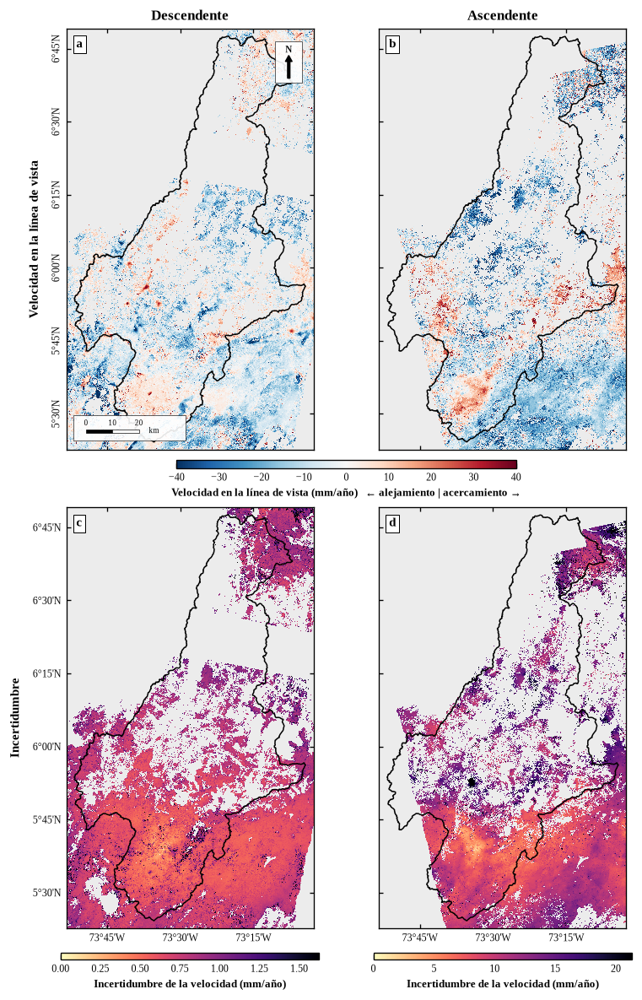

In [26]:
LIM_VEL = 40               # límite de la escala de velocidad, mm/año
PERCENTIL_STD = 98         # percentil que define el máximo de la escala de incertidumbre
PASO_GRADOS = 0.25         # separación de las coordenadas geográficas (0.25 = 15')

disponibles = [(g, nombre) for g, nombre in GEOMETRIAS_DOC.items() if g in grupos]
n = len(disponibles)
fig, ejes = plt.subplots(2, n, figsize=(FIG_ANCHO, FIG_ANCHO * 1.5), constrained_layout=True,
                         sharex=True, sharey=True, squeeze=False)
for col, (geometria, nombre) in enumerate(disponibles):
    vel, std, ext, epsg = capas_geometria(geometria)
    im_v = panel(ejes[0, col], vel, ext, epsg, "RdBu_r", -LIM_VEL, LIM_VEL, "abcd"[col])
    im_s = panel(ejes[1, col], std, ext, epsg, "magma_r", 0, float(np.nanpercentile(std, PERCENTIL_STD)), "abcd"[n + col])
    ejes[0, col].set_title(nombre, fontsize=10, fontweight="bold", pad=6)
    barra_colores(fig, im_s, ejes[1, col], "Incertidumbre de la velocidad (mm/año)", encoger=0.85)
limitar_al_area(ejes[0, 0], epsg)
coordenadas_geograficas(ejes[0, 0], epsg, PASO_GRADOS, PASO_GRADOS)
norte_y_escala(ejes[0, 0])
for fila, rotulo in enumerate(("Velocidad en la línea de vista", "Incertidumbre")):
    ejes[fila, 0].set_ylabel(rotulo, fontsize=9, fontweight="bold", labelpad=8)
barra_colores(fig, im_v, ejes[0, :], "Velocidad en la línea de vista (mm/año)   ← alejamiento | acercamiento →", LIM_VEL, encoger=0.55)
titulo_figura("Velocidad en la línea de vista e incertidumbre del ajuste por geometría", 10)
plt.show()

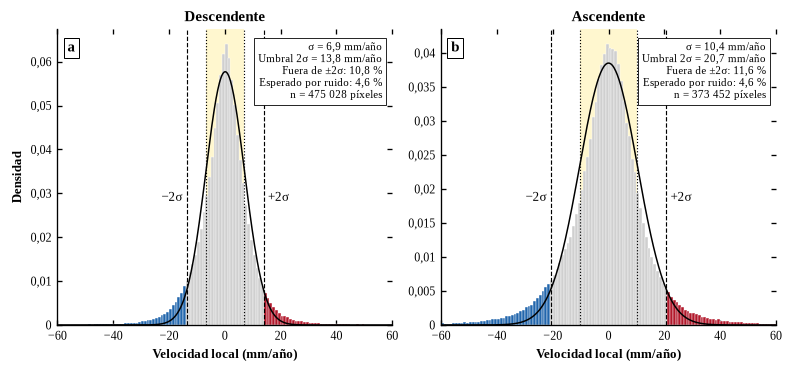

In [27]:
ALTO_FIG3 = 3.0            # pulgadas
RANGO_UMBRAL = 60          # límite del eje x, mm/año
BINS_UMBRAL = 120
COLOR_ALEJA, COLOR_ACERCA, COLOR_RUIDO, COLOR_1SIGMA = "#2166ac", "#b2182b", "#cfcfcf", "#fff3b0"
GEOMETRIAS_FIG3 = [("DESCENDING_R69", "Descendente"), ("ASCENDING_R77", "Ascendente")]


# Velocidad local de una geometría dentro del área de estudio, desde el GeoTIFF exportado en la sección 22
def velocidad_local_area(geometria):
    with rasterio.open(MOSAICO_DIR / f"velocidad_local_mm_anio_{geometria}{SUFIJO_AREA}.tif") as src:
        v = src.read(1).astype(float)
    return v[np.isfinite(v)]


# Histograma de la velocidad local con la curva normal de la dispersión robusta y los umbrales de 1 y 2 sigma
def panel_umbral(eje, v, letra, titulo):
    mediana = np.median(v)
    sigma = 1.4826 * np.median(np.abs(v - mediana))
    fuera = 100 * np.mean(np.abs(v - mediana) > 2 * sigma)
    eje.axvspan(mediana - sigma, mediana + sigma, color=COLOR_1SIGMA, alpha=0.6, zorder=0, lw=0)
    _, bordes, barras = eje.hist(v, bins=BINS_UMBRAL, range=(-RANGO_UMBRAL, RANGO_UMBRAL), density=True,
                                 color=COLOR_RUIDO, edgecolor="white", lw=0.25, zorder=1)
    ancho = bordes[1] - bordes[0]
    for barra, x in zip(barras, bordes[:-1]):
        if x + ancho <= mediana - 2 * sigma:
            barra.set_facecolor(COLOR_ALEJA)
        elif x >= mediana + 2 * sigma:
            barra.set_facecolor(COLOR_ACERCA)
    x = np.linspace(-RANGO_UMBRAL, RANGO_UMBRAL, 400)
    eje.plot(x, np.exp(-0.5 * ((x - mediana) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi)), color="black", lw=0.9, zorder=3)
    for k, estilo in ((1, ":"), (2, "--")):
        for signo in (-1, 1):
            eje.axvline(mediana + signo * k * sigma, color="black", lw=0.7, ls=estilo, zorder=2)
    alto = eje.get_ylim()[1]
    eje.text(mediana + 2 * sigma + 1.5, alto * 0.42, "+2σ", fontsize=7.5)
    eje.text(mediana - 2 * sigma - 1.5, alto * 0.42, "−2σ", fontsize=7.5, ha="right")
    n_txt = f"{v.size:,}".replace(",", " ")
    eje.text(0.97, 0.96, f"σ = {coma(sigma)} mm/año\nUmbral 2σ = {coma(2 * sigma)} mm/año\n"
             f"Fuera de ±2σ: {coma(fuera)} %\nEsperado por ruido: 4,6 %\nn = {n_txt} píxeles",
             transform=eje.transAxes, va="top", ha="right", fontsize=6.5,
             bbox=dict(boxstyle="square,pad=0.35", fc="white", ec="black", lw=0.5))
    eje.text(0.03, 0.96, letra, transform=eje.transAxes, ha="left", va="top", fontsize=9, fontweight="bold",
             bbox=dict(boxstyle="square,pad=0.25", fc="white", ec="black", lw=0.6))
    eje.set_title(titulo, fontsize=9, fontweight="bold", pad=5)
    eje.set_xlabel("Velocidad local (mm/año)", fontsize=8)
    eje.set_xlim(-RANGO_UMBRAL, RANGO_UMBRAL)
    eje.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.3f}".rstrip("0").rstrip(".").replace(".", ",")))
    eje.tick_params(labelsize=7, direction="in", length=3)
    for borde in ("top", "right"):
        eje.spines[borde].set_visible(False)
    return {"Geometría": titulo, "σ (mm/año)": round(sigma, 1), "Umbral 2σ (mm/año)": round(2 * sigma, 1),
            "Fuera de ±2σ (%)": round(fuera, 1)}


fig, ejes = plt.subplots(1, 2, figsize=(FIG_ANCHO, ALTO_FIG3), constrained_layout=True)
for i, (eje, (g, t)) in enumerate(zip(ejes, GEOMETRIAS_FIG3)):
    panel_umbral(eje, velocidad_local_area(g), "ab"[i], t)
ejes[0].set_ylabel("Densidad", fontsize=8)
titulo_figura("Distribución de la velocidad local y umbral de estabilidad por geometría", 13)
plt.show()

## 23. Series en las estaciones GNSS

En cada punto se promedia el desplazamiento LOS de los píxeles confiables de una ventana de `VENTANA_PX` píxeles a cada lado (3 × 3, unos 240 m), en mm respecto de la primera fecha y referido a la misma referencia de los mapas de velocidad (mediana de la ventana de la estación OAMU o, si el stack no la cubre, del área de estudio), de modo que la serie en OAMU queda cerca de cero. La figura muestra, por stack, los puntos de cada fecha, la mediana móvil de `VENTANA_SUAVIZADO` fechas, que deja ver aceleraciones, pausas y ciclos, y la tendencia lineal discontinua con su velocidad y su error estándar. Ese error supone ruido independiente entre fechas y por eso subestima la incertidumbre real (Yunjun et al., 2019). La descendente va en azul y la ascendente en rojo, igual que en el notebook 3.

Además de `PUNTOS`, la serie InSAR se extrae en los sitios de las 12 estaciones GNSS (`SITIOS_GNSS`); son series InSAR, no GNSS, y no se comparan aquí con las series GNSS: la comparación se hace en el notebook 3. Para agregar sitios se usa `PUNTOS = {"nombre": (latitud, longitud)}`.


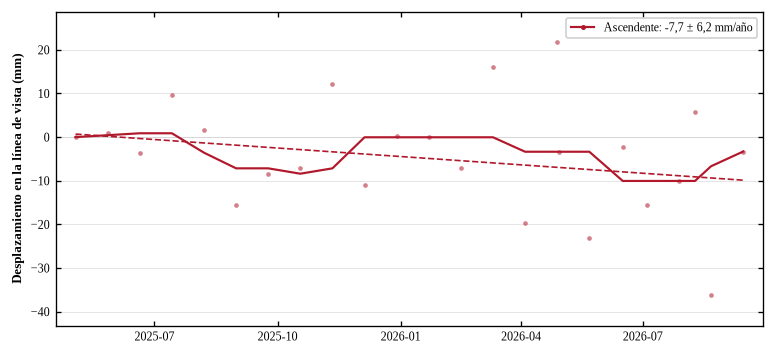

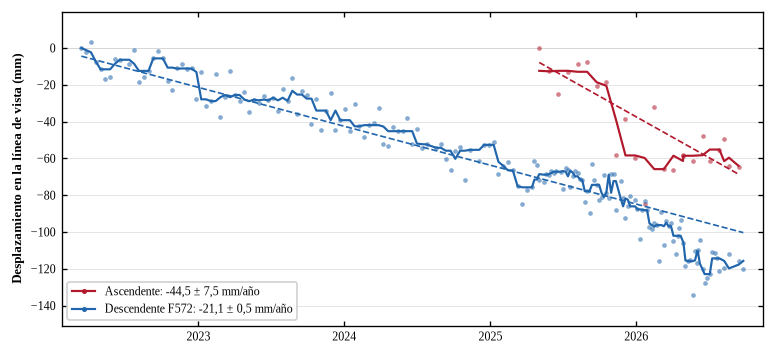

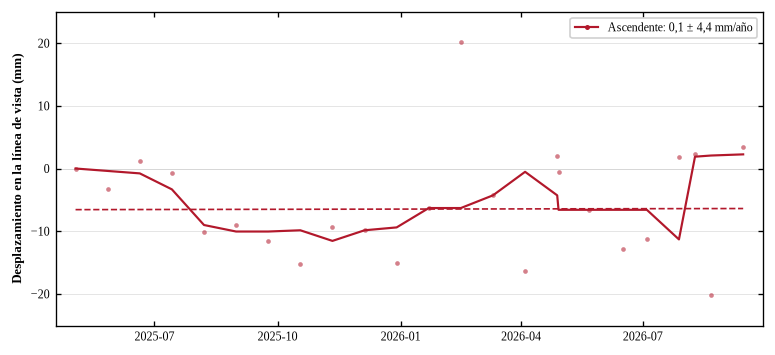

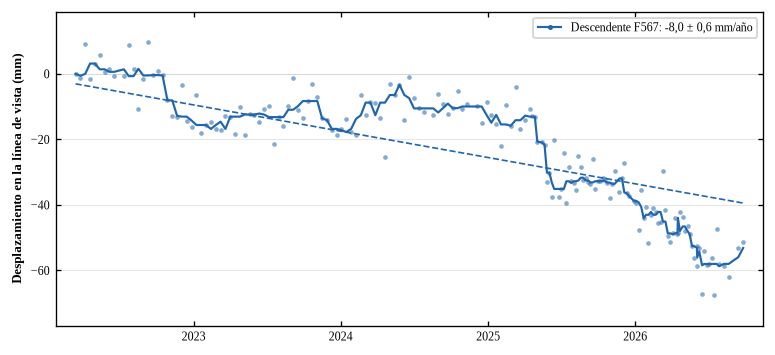

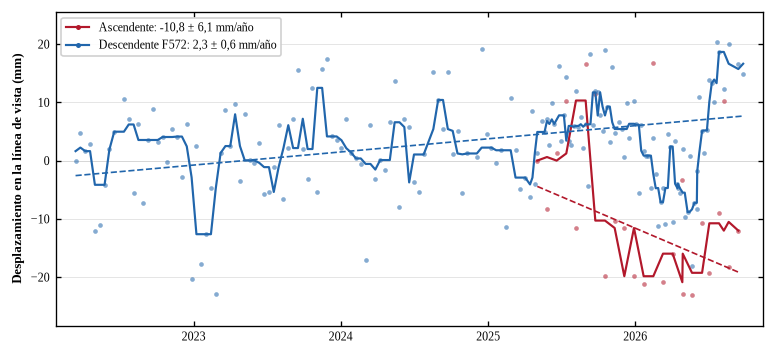

...

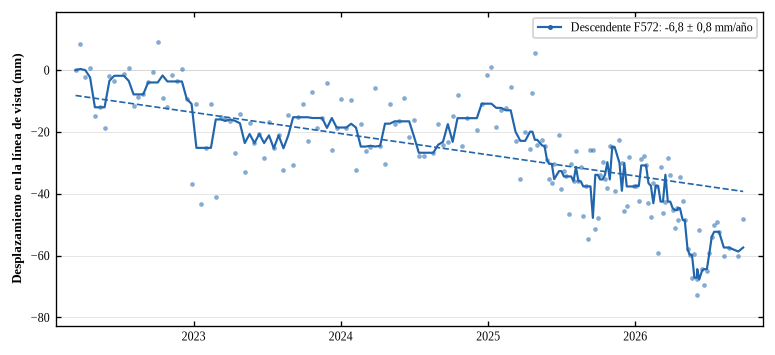

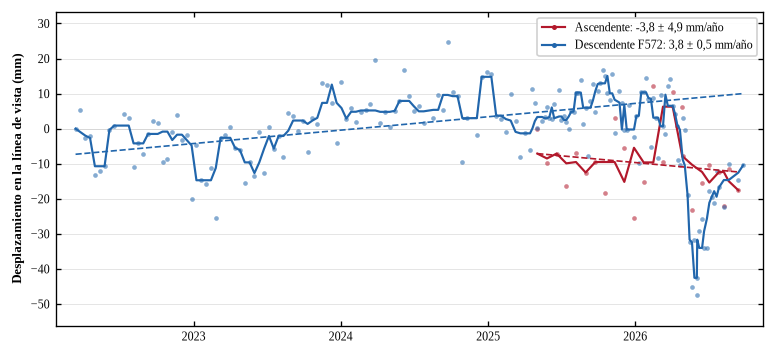

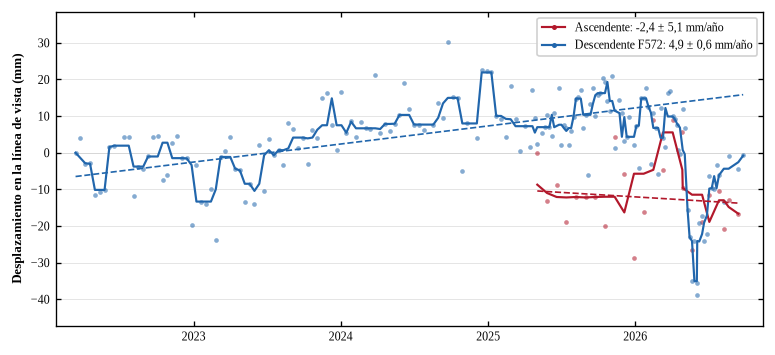

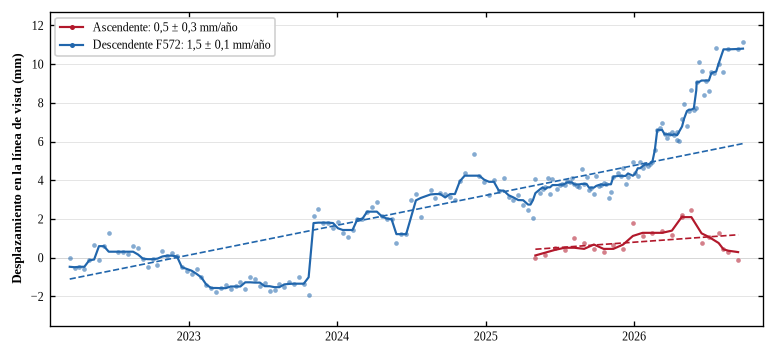

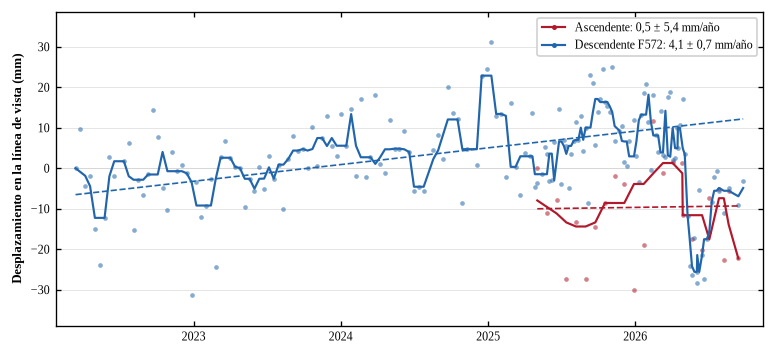

Punto,Stack,Fechas,Velocidad (mm/año),Error estándar (mm/año)
Sitio CHRL,ASCENDING_R77_F1199,24,"-7,7","6,2"
Sitio PAT4,ASCENDING_R77_F1199,24,"-44,5","7,5"
Sitio PAT4,DESCENDING_R69_F572,172,"-21,1","0,5"
Sitio SUAM,ASCENDING_R77_F1199,24,"0,1","4,4"
Sitio VMES,DESCENDING_R69_F567,172,"-8,0","0,6"
Sitio VELZ,ASCENDING_R77_F1199,24,"-10,8","6,1"
Sitio VELZ,DESCENDING_R69_F572,172,"2,3","0,6"
Sitio FLRN,DESCENDING_R69_F572,172,"2,9","1,1"
Sitio VBUV,DESCENDING_R69_F572,172,"-6,8","0,8"
Sitio TUNA,ASCENDING_R77_F1199,24,"-3,8","4,9"


sin datos: Sitio FQNE


In [28]:
PUNTOS = {}
SITIOS_GNSS = {
    "CHRL": (6.287477, -73.156451),
    "PAT4": (5.74649545, -73.12566732),
    "SUAM": (5.709874625, -72.92469695),
    "VMES": (6.88333419, -73.09168234),
    "VELZ": (5.957135, -73.646586),
    "FLRN": (5.807812, -73.971958),
    "VBUV": (5.533208338, -73.85893524),
    "TUNA": (5.531330417, -73.36388193),
    "AGTU": (5.519884547, -73.37370225),
    "OAMU": (5.647208907, -73.55802943),
    "TEAT": (5.421783709, -73.53931227),
    "FQNE": (5.467344957, -73.73480849),
}
VENTANA_PX = 1  # píxeles a cada lado del punto: 1 equivale a una ventana de 3 x 3
ANCHO_SERIE, ALTO_SERIE = FIG_ANCHO, 3.0  # pulgadas
VENTANA_SUAVIZADO = 5  # fechas de la mediana móvil
ARCHIVO_ESTACIONES = TABLAS_DIR / f"{RUN_ID}_estaciones_gnss.csv"
DIRECCION_TXT = {"DESCENDING": "Descendente", "ASCENDING": "Ascendente"}

mascaras = {}


# Máscara de confiabilidad de un stack, calculada una sola vez por ejecución
def mascara_stack(job_name):
    if job_name not in mascaras:
        mascaras[job_name] = mascara_confiable(MINTPY_ROOT / job_name)
    return mascaras[job_name]


# Filas y columnas de la ventana centrada en un punto; None si el punto queda fuera del archivo
def ventana_en_punto(archivo, lat, lon, ventana=VENTANA_PX):
    with h5py.File(archivo, "r") as f:
        attrs = {k: (v.decode() if isinstance(v, bytes) else str(v)) for k, v in f.attrs.items()}
    transform, epsg = georef(attrs)
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    fila, columna = rowcol(transform, x, y)
    filas, columnas = int(attrs["LENGTH"]), int(attrs["WIDTH"])
    if not (0 <= fila < filas and 0 <= columna < columnas):
        return None
    return (
        max(fila - ventana, 0), min(fila + ventana + 1, filas),
        max(columna - ventana, 0), min(columna + ventana + 1, columnas),
    )


serie_ref = {}


# Serie (mm) del desplazamiento mediano en la referencia de los mapas (ventana de la estación de referencia o, si el stack
# no la cubre, mediana del área de estudio), para que las series y las velocidades de los mapas compartan la misma referencia
def serie_referencia(job_name):
    if job_name not in serie_ref:
        archivo = serie_final(MINTPY_ROOT / job_name)
        confiable = mascara_stack(job_name)
        with h5py.File(archivo, "r") as f:
            attrs = {k: (v.decode() if isinstance(v, bytes) else str(v)) for k, v in f.attrs.items()}
        referencia = ventana_estacion(attrs, confiable)
        if referencia is None:
            transform, epsg = georef(attrs)
            dentro = ~geometry_mask(gdf_area.to_crs(epsg).geometry, out_shape=confiable.shape, transform=transform)
            referencia = confiable & dentro
        filas_r, cols_r = np.nonzero(referencia)
        f0, f1, c0, c1 = filas_r.min(), filas_r.max() + 1, cols_r.min(), cols_r.max() + 1
        recorte = referencia[f0:f1, c0:c1]
        with h5py.File(archivo, "r") as f:
            n = f["timeseries"].shape[0]
            serie_ref[job_name] = np.array([np.nanmedian(f["timeseries"][k, f0:f1, c0:c1][recorte]) * 1000 for k in range(n)])
    return serie_ref[job_name]


# Fechas y desplazamiento LOS medio (mm) de los píxeles confiables de la ventana, referido a la referencia de los mapas
def serie_en_punto(stack, lat, lon, ventana=VENTANA_PX):
    job_name = Path(stack).name
    archivo = serie_final(MINTPY_ROOT / job_name)
    limites = ventana_en_punto(archivo, lat, lon, ventana)
    if limites is None:
        return None, None
    f0, f1, c0, c1 = limites
    confiable = mascara_stack(job_name)[f0:f1, c0:c1]
    if not confiable.any():
        return None, None
    with h5py.File(archivo, "r") as f:
        fechas = pd.to_datetime(fechas_h5(f["date"][()]), format="%Y%m%d")
        cubo = np.where(confiable, f["timeseries"][:, f0:f1, c0:c1], np.nan) * 1000
    cubo = cubo - serie_referencia(job_name)[:, None, None]
    cubo = cubo - cubo[:1]
    return fechas, np.nanmean(cubo, axis=(1, 2))


# Velocidad media (mm/año) y su error estándar, de la tendencia lineal de la serie en mm
def tendencia(fechas, serie):
    anios = ((fechas - fechas[0]).days / 365.25).to_numpy()
    if len(serie) < 4:
        return float(np.polyfit(anios, serie, 1)[0]), np.nan
    (pendiente, _), cov = np.polyfit(anios, serie, 1, cov=True)
    return float(pendiente), float(np.sqrt(cov[0, 0]))


# Nombre de un stack para el panel: dirección de vuelo y, si hay varios, el frame
def nombre_stack_serie(job_name):
    direccion = "ASCENDING" if "ASCENDING" in job_name else "DESCENDING"
    mismos = [j for j in JOBS if direccion in j]
    marco = re.search(r"_F(\d+)", job_name)
    return f"{DIRECCION_TXT[direccion]}{' F' + marco.group(1) if marco and len(mismos) > 1 else ''}"


# Color de un stack según su dirección de vuelo; el segundo de la misma dirección usa un tono más claro
def color_stack(job_name, job_names):
    direccion = "ASCENDING" if "ASCENDING" in job_name else "DESCENDING"
    mismos = [j for j in job_names if direccion in j]
    return COLORES_STACK[direccion][min(mismos.index(job_name), 1)]


# Año decimal de cada fecha
def anio_decimal(fechas):
    return (fechas.year + (fechas.dayofyear - 1) / 365.25).to_numpy()


# Figura de un punto: por stack, los puntos de cada fecha, su mediana móvil y la tendencia lineal
def figura_serie(nombre_punto, series):
    fig, eje = plt.subplots(figsize=(ANCHO_SERIE, ALTO_SERIE))
    manijas = []
    for job_name, (fechas, serie, velocidad, error) in series.items():
        texto_error = "" if np.isnan(error) else f" ± {error:.1f}"
        etiqueta = f"{nombre_stack_serie(job_name)}: {velocidad:.1f}{texto_error} mm/año".replace(".", ",")
        manijas.append(dibujar_serie(eje, fechas, serie, color_stack(job_name, list(series)), etiqueta, ventana=VENTANA_SUAVIZADO, pendiente=velocidad))
    eje.margins(x=0.03, y=0.12)
    formato_serie(eje)
    eje.legend(handles=manijas, loc="best")
    fig.tight_layout()
    titulo_figura(f"Serie temporal InSAR de desplazamiento en la línea de vista en {nombre_punto}")
    plt.show()


puntos = {**PUNTOS, **{f"Sitio {sitio}": coordenadas for sitio, coordenadas in SITIOS_GNSS.items()}}
jobs_listos = [j for j in JOBS if (MINTPY_ROOT / j / "velocity.h5").exists()]
filas, sin_datos, filas_series = [], [], []
for nombre_punto, (lat, lon) in puntos.items():
    series = {}
    for job_name in jobs_listos:
        fechas, serie = serie_en_punto(job_name, lat, lon)
        if serie is None:
            continue
        largo = (fechas[-1] - fechas[0]).days / 365.25 >= ANIOS_MIN_ESTACIONAL
        corte = (fechas <= pd.Timestamp(FECHA_FIN_VELOCIDAD)) if largo else np.ones(len(fechas), bool)
        velocidad, error = tendencia(fechas[corte], serie[corte])
        series[job_name] = (fechas, serie, velocidad, error)
        nombre = job_name.replace(f"{RUN_ID}_", "")
        punto_csv = nombre_punto.replace("Sitio ", "Sitio GNSS ", 1) if nombre_punto.startswith("Sitio ") else nombre_punto
        filas_series.extend(
            {"punto": punto_csv, "stack": nombre, "fecha": f.strftime("%Y-%m-%d"), "desplazamiento_cm": round(float(v) / 10, 4)}
            for f, v in zip(fechas, serie)
        )
        filas.append({
            "Punto": nombre_punto,
            "Stack": nombre,
            "Fechas": len(fechas),
            "Velocidad (mm/año)": round(velocidad, 1),
            "Error estándar (mm/año)": round(error, 1),
        })
    if series:
        figura_serie(nombre_punto, series)
    else:
        sin_datos.append(nombre_punto)

series_puntos = pd.DataFrame(filas)
tabla_apa(series_puntos, "Velocidad en la línea de vista en los puntos de interés")
if sin_datos:
    print("sin datos:", ", ".join(sin_datos))

# Coordenadas de las estaciones GNSS, que usa el notebook 3
estaciones = pd.DataFrame(
    [(sitio, lat, lon) for sitio, (lat, lon) in SITIOS_GNSS.items()],
    columns=["sitio", "latitud", "longitud"],
)
estaciones.to_csv(ARCHIVO_ESTACIONES, index=False)

# Series de cada punto, que usa el notebook 3 para dibujar la serie InSAR junto a la GNSS
pd.DataFrame(filas_series).to_csv(TABLAS_DIR / f"{RUN_ID}_series_puntos.csv", index=False)

## 23b. Control de saltos comunes por fecha

**Qué hace esta celda.** Para cada stack calcula, en cada fecha, la mediana espacial del desplazamiento de una muestra de hasta `MUESTRA_PIXELES` píxeles confiables y su dispersión robusta (1,4826 veces la desviación absoluta mediana). Una fecha cuya mediana cambia de golpe respecto de la anterior (más de `UMBRAL_SALTO_MAD` desviaciones robustas de los cambios y más de `SALTO_MIN_MM` mm) tiene un salto común a toda la escena: suele venir de un error de desenrollado en el punto de referencia, de la atmósfera o de la ionosfera, y no de movimientos del terreno.

**Cómo leer la figura y la tabla.** La figura muestra, por stack, la mediana (línea) y la dispersión (banda). La tabla lista las fechas marcadas. Si una fecha marcada coincide con saltos simultáneos en las series de varias estaciones, conviene revisar sus interferogramas y, si se justifica, excluirla con `FECHAS_EXCLUIDAS` y repetir MintPy. Las velocidades descendentes se ajustan hasta `FECHA_FIN_VELOCIDAD`, de modo que los saltos posteriores no las afectan; la velocidad ascendente usa toda la serie.

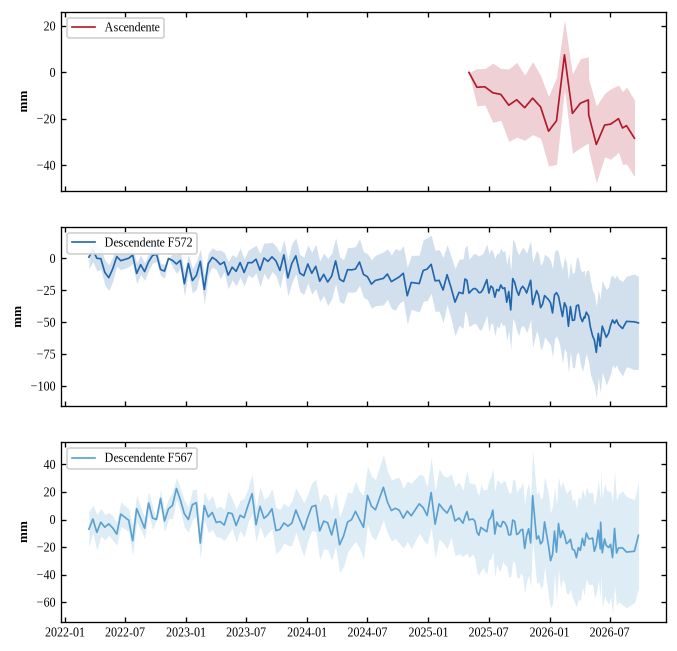

ok: ninguna fecha con salto común anómalo


In [29]:
MUESTRA_PIXELES = 20000
UMBRAL_SALTO_MAD = 5
SALTO_MIN_MM = 10


# Mediana espacial y dispersion robusta (mm) de cada fecha en una muestra de pixeles confiables del stack
def resumen_por_fecha(job_name):
    archivo = serie_final(MINTPY_ROOT / job_name)
    confiable = mascara_stack(job_name)
    indices = np.flatnonzero(confiable.ravel())
    if len(indices) == 0:
        return None, None, None
    azar = np.random.default_rng(0)
    indices = np.sort(azar.choice(indices, min(len(indices), MUESTRA_PIXELES), replace=False))
    with h5py.File(archivo, "r") as f:
        fechas = pd.to_datetime(fechas_h5(f["date"][()]), format="%Y%m%d")
        medianas, dispersiones = [], []
        for k in range(f["timeseries"].shape[0]):
            valores = f["timeseries"][k].ravel()[indices] * 1000
            valores = valores[np.isfinite(valores)]
            medianas.append(np.median(valores))
            dispersiones.append(1.4826 * np.median(np.abs(valores - np.median(valores))))
    return fechas, np.array(medianas), np.array(dispersiones)


filas_salto = []
fig, ejes = plt.subplots(len(jobs_listos), 1, figsize=(FIG_ANCHO, 2.2 * len(jobs_listos)), sharex=True, squeeze=False)
for eje, job_name in zip(ejes[:, 0], jobs_listos):
    fechas, mediana, dispersion = resumen_por_fecha(job_name)
    if fechas is None:
        continue
    color = color_stack(job_name, jobs_listos)
    eje.fill_between(fechas, mediana - dispersion, mediana + dispersion, color=color, alpha=0.2, lw=0)
    eje.plot(fechas, mediana, "-", color=color, lw=1.0, label=nombre_stack_serie(job_name))
    cambios = np.diff(mediana)
    escala = 1.4826 * np.median(np.abs(cambios - np.median(cambios)))
    for k in np.flatnonzero((np.abs(cambios - np.median(cambios)) > UMBRAL_SALTO_MAD * escala) & (np.abs(cambios) > SALTO_MIN_MM)):
        eje.plot(fechas[k + 1], mediana[k + 1], "o", ms=5, mfc="none", mec="black")
        filas_salto.append({"Stack": job_name.replace(f"{RUN_ID}_", ""), "Fecha": fechas[k + 1].strftime("%Y-%m-%d"),
                            "Cambio de la mediana (mm)": round(float(cambios[k]), 1), "Dispersión (mm)": round(float(dispersion[k + 1]), 1)})
    eje.set_ylabel("mm", fontsize=8)
    eje.legend(loc="upper left")
    estilo_eje(eje)
titulo_figura("Mediana espacial y dispersión robusta del desplazamiento por fecha en cada stack; círculos: saltos comunes")
plt.show()
if filas_salto:
    tabla_apa(pd.DataFrame(filas_salto), "Fechas con salto común a toda la escena")
else:
    print("ok: ninguna fecha con salto común anómalo")


## 24. Exportación a GeoTIFF

Para cada stack se guardan en `03_resultados/geotiff/<stack>/`, completos y recortados al área (`_area`): velocidad (mm/año), desviación estándar, máscara de confiabilidad e incidencia y azimut de la línea de vista, que permiten proyectar las velocidades GNSS a la línea de vista (notebook 3) y evaluar qué laderas observa el satélite. Los archivos usan `NaN` como valor sin dato y compresión sin pérdida (Gillies et al., 2013).

In [30]:
CAPAS_GEOMETRIA = {"incidencia_grados": "incidenceAngle", "azimut_grados": "azimuthAngle"}


# Capas de un stack para exportar: resultados con la máscara de confiabilidad y geometría de observación
def capas_geotiff(job_name):
    geometria = MINTPY_ROOT / job_name / "inputs" / "geometryGeo.h5"
    velocidad, desviacion, attrs = velocidad_confiable(job_name)
    confiable = mascara_confiable(MINTPY_ROOT / job_name)
    capas = {
        "velocidad_mm_anio": velocidad,
        "velocidad_std_mm_anio": desviacion,
        "mascara_confiable": confiable.astype("float32"),
    }
    for nombre_capa, dataset in CAPAS_GEOMETRIA.items():
        angulo = leer_h5(geometria, dataset)[0].astype("float32")
        capas[nombre_capa] = np.where(angulo != 0, angulo, np.nan)
    return capas, attrs


filas = []
for job_name in JOBS:
    if not (MINTPY_ROOT / job_name / "velocity.h5").exists():
        continue
    salida = GEOTIFF_DIR / job_name
    salida.mkdir(parents=True, exist_ok=True)
    capas, attrs = capas_geotiff(job_name)
    transform, epsg = georef(attrs)
    forma = next(iter(capas.values())).shape
    fuera = geometry_mask(gdf_area.to_crs(epsg).geometry, out_shape=forma, transform=transform)
    for nombre_capa, arr in capas.items():
        guardar_geotiff(salida / f"{nombre_capa}.tif", arr, transform, epsg)
        en_area = np.where(fuera, np.nan, arr)
        guardar_geotiff(salida / f"{nombre_capa}{SUFIJO_AREA}.tif", en_area, transform, epsg)
    filas.append(job_name)

print(f"{len(filas)} stacks exportados ({2 * len(CAPAS_GEOMETRIA) + 6} archivos cada uno)")

3 stacks exportados (10 archivos cada uno)


## 25. Tabla resumen por stack

Genera la Tabla 4 del documento: periodo, imágenes, interferogramas usados y generados, fechas excluidas por ruido (`exclude_date.txt`) y píxeles confiables del área. Se guarda en `03_resultados/tablas/`.

In [31]:
# Contenido de un archivo de texto de MintPy como lista de palabras; vacío si no existe
def leer_lista(archivo):
    return archivo.read_text().split() if archivo.exists() else []


# Fila de la Tabla 4 de un stack: periodo, imágenes, interferogramas, fechas excluidas y píxeles confiables
def resumir_resultados(job_name):
    d = MINTPY_ROOT / job_name
    velocidad, _, attrs = velocidad_confiable(job_name)
    transform, epsg = georef(attrs)
    dentro = ~geometry_mask(gdf_area.to_crs(epsg).geometry, out_shape=velocidad.shape, transform=transform)
    usados = leer_h5(d / "inputs" / "ifgramStack.h5", "dropIfgram")[0]
    with h5py.File(d / "timeseries.h5", "r") as f:
        fechas = pd.to_datetime(fechas_h5(f["date"][()]), format="%Y%m%d")
    excluidas = leer_lista(d / "exclude_date.txt")
    return {
        "Stack": nombre_stack(job_name),
        "Periodo": f"{fechas[0]:%d/%m/%Y} a {fechas[-1]:%d/%m/%Y}",
        "Imágenes": len(fechas),
        "Interferogramas (usados / generados)": f"{int(usados.sum())} / {len(usados)}",
        "Fechas excluidas": len(excluidas),
        "Píxeles confiables (%)": pct_del_area(np.isfinite(velocidad) & dentro, dentro),
    }


resumen_df = pd.DataFrame([resumir_resultados(j) for j in JOBS if (MINTPY_ROOT / j / "velocity.h5").exists()])
tabla_apa(resumen_df, "Stacks procesados y calidad de la serie temporal", numero=4)


Stack,Periodo,Imágenes,Interferogramas (usados / generados),Fechas excluidas,Píxeles confiables (%)
Ascendente R77 F1199,03/05/2025 a 14/09/2026,24,45 / 59,0,"39,2"
Descendente R69 F572,14/03/2022 a 26/09/2026,172,341 / 536,0,"45,0"
Descendente R69 F567,14/03/2022 a 26/09/2026,172,341 / 493,0,"23,6"


## Referencias

Alaska Satellite Facility. (s.f.-a). *asf_search* [Software]. https://docs.asf.alaska.edu/asf_search/basics/

Alaska Satellite Facility. (s.f.-b). *Time series analysis with HyP3 and MintPy* [Cuaderno de Jupyter]. https://github.com/ASFHyP3/hyp3-docs/blob/main/docs/tutorials/hyp3_insar_stack_for_ts_analysis.ipynb

Alaska Satellite Facility. (s.f.-c). *HyP3 SDK* [Documentación de software]. https://hyp3-docs.asf.alaska.edu/using/sdk/

Alaska Satellite Facility. (s.f.-d). *Sentinel-1 InSAR product guide* [Documentación]. https://hyp3-docs.asf.alaska.edu/guides/insar_product_guide/

Ansari, H., De Zan, F. y Parizzi, A. (2021). Study of systematic bias in measuring surface deformation with SAR interferometry. *IEEE Transactions on Geoscience and Remote Sensing, 59*(2), 1285-1301. https://doi.org/10.1109/TGRS.2020.3003421

Barra, A., Solari, L., Béjar-Pizarro, M., Monserrat, O., Bianchini, S., Herrera, G., Crosetto, M., Sarro, R., González-Alonso, E., Mateos, R. M., Ligüerzana, S., López, C. y Moretti, S. (2017). A methodology to detect and update active deformation areas based on Sentinel-1 SAR images. *Remote Sensing, 9*(10), 1002. https://doi.org/10.3390/rs9101002

Bekaert, D. P. S., Handwerger, A. L., Agram, P. y Kirschbaum, D. B. (2020). InSAR-based detection method for mapping and monitoring slow-moving landslides in remote regions with steep and mountainous terrain: An application to Nepal. *Remote Sensing of Environment, 249*, 111983. https://doi.org/10.1016/j.rse.2020.111983

Berardino, P., Fornaro, G., Lanari, R. y Sansosti, E. (2002). A new algorithm for surface deformation monitoring based on small baseline differential SAR interferograms. *IEEE Transactions on Geoscience and Remote Sensing, 40*(11), 2375-2383. https://doi.org/10.1109/TGRS.2002.803792

Chen, C. W. y Zebker, H. A. (2001). Two-dimensional phase unwrapping with use of statistical models for cost functions in nonlinear optimization. *Journal of the Optical Society of America A, 18*(2), 338-351. https://doi.org/10.1364/JOSAA.18.000338

Collette, A. (2013). *Python and HDF5*. O'Reilly Media.

Copernicus Sentinel-1. (2022-2026). *Sentinel-1 Interferometric Wide Swath SLC products* [Conjunto de datos]. European Space Agency. Obtenido del Alaska Satellite Facility Distributed Active Archive Center. https://search.asf.alaska.edu/

De Zan, F., Zonno, M. y López-Dekker, P. (2015). Phase inconsistencies and multiple scattering in SAR interferometry. *IEEE Transactions on Geoscience and Remote Sensing, 53*(12), 6608-6616. https://doi.org/10.1109/TGRS.2015.2444431

Doin, M.-P., Lasserre, C., Peltzer, G., Cavalié, O. y Doubre, C. (2009). Corrections of stratified tropospheric delays in SAR interferometry: Validation with global atmospheric models. *Journal of Applied Geophysics, 69*(1), 35-50. https://doi.org/10.1016/j.jappgeo.2009.03.010

EarthScope Consortium. (2026). *2026 Technical Course: InSAR Processing and Analysis (ISCE+)* [Materiales de curso]. https://github.com/isceplus/2026-isceplus

European Space Agency. (2022). *Copernicus Global Digital Elevation Model GLO-30* [Conjunto de datos]. https://doi.org/10.5270/ESA-c5d3d65

Fattahi, H. y Amelung, F. (2013). DEM error correction in InSAR time series. *IEEE Transactions on Geoscience and Remote Sensing, 51*(7), 4249-4259. https://doi.org/10.1109/TGRS.2012.2227761

Gillies, S., et al. (2013). *Rasterio: Geospatial raster I/O for Python programmers* [Software]. https://github.com/rasterio/rasterio

Gillies, S., van der Wel, C., Van den Bossche, J., Taves, M. W., Arnott, J., Ward, B. C., et al. (2024). *Shapely* (Versión 2.0) [Software]. Zenodo. https://doi.org/10.5281/zenodo.5597138

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., et al. (2020). Array programming with NumPy. *Nature, 585*(7825), 357-362. https://doi.org/10.1038/s41586-020-2649-2

Hersbach, H., Bell, B., Berrisford, P., Hirahara, S., Horányi, A., Muñoz-Sabater, J., et al. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society, 146*(730), 1999-2049. https://doi.org/10.1002/qj.3803

Hetland, E. A., Musé, P., Simons, M., Lin, Y. N., Agram, P. S. y DiCaprio, C. J. (2012). Multiscale InSAR Time Series (MInTS) analysis of surface deformation. *Journal of Geophysical Research: Solid Earth, 117*(B2), B02404. https://doi.org/10.1029/2011JB008731

Hogenson, K., Kristenson, H., Kennedy, J., Johnston, A., Rine, J., Logan, T., Zhu, J., Williams, F., Herrmann, J., Smale, J. y Meyer, F. (2026). *Hybrid Pluggable Processing Pipeline (HyP3): A cloud-native infrastructure for generic processing of SAR data* [Software]. Zenodo. https://doi.org/10.5281/zenodo.4646138

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

Jolivet, R., Grandin, R., Lasserre, C., Doin, M.-P. y Peltzer, G. (2011). Systematic InSAR tropospheric phase delay corrections from global meteorological reanalysis data. *Geophysical Research Letters, 38*(17), L17311. https://doi.org/10.1029/2011GL048757

Jordahl, K., Van den Bossche, J., Fleischmann, M., Wasserman, J., McBride, J., Gerard, J., et al. (2020). *geopandas/geopandas* (Versión 0.8.1) [Software]. Zenodo. https://doi.org/10.5281/zenodo.3946761

Leys, C., Ley, C., Klein, O., Bernard, P. y Licata, L. (2013). Detecting outliers: Do not use standard deviation around the mean, use absolute deviation around the median. *Journal of Experimental Social Psychology, 49*(4), 764-766. https://doi.org/10.1016/j.jesp.2013.03.013

Maghsoudi, Y., Hooper, A. J., Wright, T. J., Lazecky, M. y Ansari, H. (2022). Characterizing and correcting phase biases in short-term, multilooked interferograms. *Remote Sensing of Environment, 275*, 113022. https://doi.org/10.1016/j.rse.2022.113022

McKinney, W. (2010). Data structures for statistical computing in Python. En S. van der Walt & J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 56-61). https://doi.org/10.25080/Majora-92bf1922-00a

Pepe, A. y Lanari, R. (2006). On the extension of the minimum cost flow algorithm for phase unwrapping of multitemporal differential SAR interferograms. *IEEE Transactions on Geoscience and Remote Sensing, 44*(9), 2374-2383. https://doi.org/10.1109/TGRS.2006.873207

Pérez, F. y Granger, B. E. (2007). IPython: A system for interactive scientific computing. *Computing in Science & Engineering, 9*(3), 21-29. https://doi.org/10.1109/MCSE.2007.53

Python Software Foundation. (2024). *The Python standard library* (Versión 3.11) [Documentación de software]. https://docs.python.org/3/library/

Rosen, P. A., Gurrola, E. M., Agram, P., Cohen, J., Lavalle, M., Riel, B. V., Fattahi, H., Aivazis, M. A. G., Simons, M. y Buckley, S. M. (2018). The InSAR Scientific Computing Environment 3.0: A flexible framework for NISAR operational and user-led science processing. En *IGARSS 2018 - 2018 IEEE International Geoscience and Remote Sensing Symposium* (pp. 4897-4900). IEEE. https://doi.org/10.1109/IGARSS.2018.8517504

Snow, A. D., Whitaker, J., Cochran, M., Van den Bossche, J., Mayo, C., et al. (2024). *pyproj4/pyproj* [Software]. Zenodo. https://doi.org/10.5281/zenodo.2592232

Werner, C., Wegmüller, U., Strozzi, T. y Wiesmann, A. (2000). GAMMA SAR and interferometric processing software. En *Proceedings of the ERS-Envisat Symposium* (ESA SP-461). European Space Agency.

Yunjun, Z., Fattahi, H. y Amelung, F. (2019). Small baseline InSAR time series analysis: Unwrapping error correction and noise reduction. *Computers & Geosciences, 133*, 104331. https://doi.org/10.1016/j.cageo.2019.104331

Yunjun, Z., Fattahi, H., Pi, X., Rosen, P., Simons, M., Agram, P. y Aoki, Y. (2022). Range geolocation accuracy of C-/L-band SAR and its implications for operational stack coregistration. *IEEE Transactions on Geoscience and Remote Sensing, 60*, 1-19. https://doi.org/10.1109/TGRS.2022.3168509


Zheng, Y. (2022). *Closure phase & systematic bias in multilooked InSAR time-series* [Cuaderno de Jupyter]. MintPy-tutorial. https://github.com/insarlab/MintPy-tutorial/blob/main/applications/closure_phase_bias.ipynb

Zheng, Y., Fattahi, H., Agram, P., Simons, M. y Rosen, P. (2022). On closure phase and systematic bias in multilooked SAR interferometry. *IEEE Transactions on Geoscience and Remote Sensing, 60*, 5226611. https://doi.org/10.1109/TGRS.2022.3167648